# Evaluación y Análisis SHAP — IFN3

Notebook unificado para los modelos entrenados con datos IFN3.
Secciones:
1–7. Análisis SHAP: beeswarm agrupado, dependencia, npies, stacking
8. Summary plots (3 paneles)
9. Importancia SHAP por especie

In [20]:
import os
import re
import gc
import sys
import warnings
from pathlib import Path

import joblib
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator
from IPython.display import Image as IPImage, display as ipy_display

import shap
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

import mysql.connector
from scipy.stats import gaussian_kde
from matplotlib.colors import Normalize
import time

warnings.filterwarnings('ignore')
%matplotlib inline

print('Imports OK')

Imports OK


In [21]:
# =============================================================================
# Clases PyTorch — necesarias para deserializar modelos .joblib
# =============================================================================

def cast_to_str(X):
    return pd.DataFrame(X).astype(str).values


class PyTorchMLPDropout(nn.Module):
    def __init__(self, input_dim, hidden_layer_sizes=(100,), activation='relu',
                 dropout_rate=0.2, use_batchnorm=True):
        super().__init__()
        layers = []
        in_dim = input_dim
        if activation == 'relu':        act_fn = nn.ReLU
        elif activation == 'tanh':      act_fn = nn.Tanh
        elif activation == 'leaky_relu': act_fn = lambda: nn.LeakyReLU(0.1)
        else:                           act_fn = nn.ReLU
        for h in hidden_layer_sizes:
            layers.append(nn.Linear(in_dim, h))
            if use_batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(act_fn())
            if dropout_rate > 0: layers.append(nn.Dropout(dropout_rate))
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class MLPRegressorTorch(BaseEstimator, RegressorMixin):
    def __init__(self, hidden_layer_sizes=(100,), activation='relu', solver='adam',
                 alpha=1e-4, learning_rate_init=1e-3, max_iter=200, batch_size=256,
                 dropout_rate=0.2, use_batchnorm=True, device='cpu', verbose=False):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.activation = activation
        self.solver = solver
        self.alpha = alpha
        self.learning_rate_init = learning_rate_init
        self.max_iter = max_iter
        self.batch_size = batch_size
        self.dropout_rate = dropout_rate
        self.use_batchnorm = use_batchnorm
        self.device = device
        self.verbose = verbose
        self.model_ = None

    def predict(self, X):
        if self.model_ is None:
            raise RuntimeError('Model not fitted')
        self.model_.eval()
        self.model_.to(self.device)
        X_t = torch.tensor(pd.DataFrame(X).values, dtype=torch.float32).to(self.device)
        with torch.no_grad():
            return self.model_(X_t).cpu().numpy().flatten()


# Inject into __main__ for joblib unpickling
import __main__
__main__.cast_to_str = cast_to_str
__main__.PyTorchMLPDropout = PyTorchMLPDropout
__main__.MLPRegressorTorch = MLPRegressorTorch

print('Clases PyTorch OK — spoofing listo')

Clases PyTorch OK — spoofing listo


In [22]:
# =============================================================================
# Rutas y configuración
# =============================================================================

BASE = Path('../../../')

DATA_PATH             = BASE / 'data/processed/ifn_entrenamiento_year_agrupado_periodo_completado_2.csv'
MODELS_IFN3_C4        = BASE / 'models/artifacts/IFN3/c4/base'
MODELS_IFN3_CB4       = BASE / 'models/artifacts/IFN3/carbono_bruto4/base'
MODELS_IFN3_C4_STACK  = BASE / 'models/artifacts/IFN3/c4/stackings'
MODELS_IFN3_CB4_STACK = BASE / 'models/artifacts/IFN3/carbono_bruto4/stackings'
OUTPUT_SHAP           = BASE / 'figures/shap'
CACHE_SHAP            = OUTPUT_SHAP / 'cache'
OUTPUT_SHAP.mkdir(parents=True, exist_ok=True)
CACHE_SHAP.mkdir(parents=True, exist_ok=True)

# Mappings ordinales
MAPA_PENDIENTE = {
    'muy suave (<5°)': 0, 'suave (5-10°)': 1, 'moderada (10-15°)': 2,
    'fuerte (15-20°)': 3, 'muy fuerte (20-30°)': 4,
    'escarpada (30-50°)': 5, 'extrema (>50°)': 6
}
MAPA_ORIENTACION = {'N': 0, 'NE': 1, 'E': 2, 'SE': 3, 'S': 4, 'SO': 5, 'O': 6, 'NO': 7}

FEATURES_C4 = [
    'especie_id', 'tipo_especie', 'periodo_agrupado', 'radio', 'ocupa',
    'npies_1', 'npies_2', 'npies_5', 'npies_10', 'npies_15', 'npies_20',
    'npies_25', 'npies_30', 'npies_35', 'npies_40', 'npies_45', 'npies_50',
    'npies_55', 'npies_60', 'npies_65', 'npies_70',
    'estado_id', 'fccarb', 'disesp_id', 'modcomb_id', 'nivel2_id', 'tratmasa_id',
    'rocosidad_id', 'orientacion_cat', 'elevacion', 'pendiente_cat', 'martonneidx_id',
    'skt_mean_primavera', 'pr_sum_primavera', 'skt_std_verano', 'skt_std_primavera',
    'pr_sum_otoño', 'skt_mean_verano', 'pr_sum_verano', 'pr_sum_invierno',
    'gndvi_mean_verano', 'ndii_mean_primavera', 'gndvi_std_primavera', 'evi_mean_primavera'
]

FEATURES_CB4 = [
    'especie_id', 'tipo_especie', 'periodo_agrupado', 'radio', 'ocupa',
    'npies_1', 'npies_2', 'npies_5', 'npies_10', 'npies_15', 'npies_20',
    'npies_25', 'npies_30', 'npies_35', 'npies_40', 'npies_45', 'npies_50',
    'npies_55', 'npies_60', 'npies_65', 'npies_70',
    'estado_id', 'fccarb', 'disesp_id', 'modcomb_id', 'nivel2_id', 'tratmasa_id',
    'rocosidad_id', 'orientacion_cat', 'elevacion', 'pendiente_cat', 'martonneidx_id',
    'gndvi_mean_verano', 'ndii_mean_primavera', 'gndvi_std_primavera', 'evi_mean_primavera'
]

VARS_CATEGORICAS = [
    'especie_id', 'tipo_especie', 'estado_id', 'disesp_id',
    'modcomb_id', 'nivel2_id', 'tratmasa_id', 'rocosidad_id',
    'martonneidx_id', 'orientacion_cat', 'pendiente_cat'
]

# Variables categóricas con orden significativo → color = valor real (no carbono medio)
VARS_ORDINALES = {'rocosidad_id', 'martonneidx_id', 'estado_id', 'tratmasa_id', 'pendiente_cat'}

# Configuraciones de stacking: nombre → lista de modelos base que recibe el meta-learner
STACK_CONFIGS = {
    'Stack1': ['LightGBM', 'Random_Forest'],
    'Stack2': ['LightGBM', 'XGBoost', 'GBDT'],
    'Stack3': ['CatBoost', 'Random_Forest', 'GBDT'],
    'Stack4': ['CatBoost', 'LightGBM', 'Random_Forest', 'GBDT'],
    'Stack5': ['CatBoost', 'LightGBM', 'XGBoost', 'Random_Forest', 'GBDT', 'BaggedDT'],
}

print(f'Datos:            {DATA_PATH}')
print(f'Modelos c4:       {MODELS_IFN3_C4}')
print(f'Modelos cb4:      {MODELS_IFN3_CB4}')
print(f'Stackings c4:     {MODELS_IFN3_C4_STACK}')
print(f'Stackings cb4:    {MODELS_IFN3_CB4_STACK}')
print(f'Figuras SHAP:     {OUTPUT_SHAP}')

# Directorios adicionales (summary + force plots, especie SHAP)
OUT_SUMMARY = BASE / 'figures/shap_summary'
OUT_FORCE   = BASE / 'figures/shap_force'
OUT_SUMMARY.mkdir(parents=True, exist_ok=True)
OUT_FORCE.mkdir(parents=True, exist_ok=True)

# Configuración BD para análisis de especies
DB_CFG = dict(host='127.0.0.1', port=3306,
              user=os.environ.get('DB_USER', 'root'), password=os.environ['DB_PASSWORD'],
              database=os.environ.get('DB_NAME', 'ddbb_gwest'))

# CONFIGS para summary/force plots
CONFIGS_SF = {
    'c4':             {'features': FEATURES_C4,  'unit': 'tC/ha',
                      'models':   MODELS_IFN3_C4},
    'carbono_bruto4': {'features': FEATURES_CB4, 'unit': 'tC',
                      'models':   MODELS_IFN3_CB4},
}
print(f'Caché SHAP:       {CACHE_SHAP}')

Datos:            ../../data/processed/ifn_entrenamiento_year_agrupado_periodo_completado_2.csv
Modelos c4:       ../../models/artifacts/IFN3/c4/base
Modelos cb4:      ../../models/artifacts/IFN3/carbono_bruto4/base
Stackings c4:     ../../models/artifacts/IFN3/c4/stackings
Stackings cb4:    ../../models/artifacts/IFN3/carbono_bruto4/stackings
Figuras SHAP:     ../../figures/shap
Caché SHAP:       ../../figures/shap/cache


## Tratamiento de variables categóricas en el análisis SHAP

Las variables categóricas se codifican con **One-Hot Encoding (OHE)** antes de entrar al modelo,
generando una columna binaria por cada categoría. En los gráficos SHAP, los valores de cada variable
se **reagrupan** sumando las contribuciones SHAP de todas sus columnas OHE (etiqueta con `*`).

El **color** de cada punto en el beeswarm y violín indica el valor de la variable en esa muestra,
pero su interpretación varía según el tipo de variable:

### Variables agrupadas ordinales — color = valor real de la variable
El valor numérico tiene un orden significativo: un número mayor implica mayor intensidad del fenómeno.

| Variable | Escala |
|---|---|
| `estado_id*` | 1 = Repoblado → 4 = Fustal (madurez del bosque) |
| `rocosidad_id*` | 1 = Sin pedregosidad → 5 = Roquedo |
| `martonneidx_id*` | 1 = Zona árida → 6 = Zona perhúmeda |
| `tratmasa_id*` | 1 = Monte alto → 3 = Monte bajo |
| `tipo_especie*` | 0 = Conífera (azul), 1 = Frondosa (rojo) — binaria, color directo |

### Variables agrupadas nominales — color = carbono medio del dataset para esa categoría
El valor numérico es un identificador sin orden intrínseco. El color refleja el carbono medio
observado en el dataset para la categoría concreta de cada muestra (calculado sobre todos los datos
antes del split train/test).

| Variable | Descripción |
|---|---|
| `especie_id*` | Especie arbórea (OHE con ~190 categorías) |
| `disesp_id*` | Distribución espacial de la masa |
| `modcomb_id*` | Modelo de combustible (13 tipos) |
| `nivel2_id*` | Nivel morfoestructural del monte |
| `orientacion_cat*` | Orientación cardinal (N/NE/E/SE/S/SO/O/NO) — circular, sin orden lineal |
| `pendiente_cat*` | Clase de pendiente — ordinal en campo, pero tratada como nominal por ser OHE |

### Variable especial: `npies* (Densidad)`
Agrupa las 16 columnas `npies_1` a `npies_70` (número de pies por hectárea por clase diamétrica).
El color es la **suma de los valores normalizados por columna** [0,1]: cada clase diamétrica
contribuye por igual, evitando que `npies_1` (siempre el mayor por ser acumulativo) domine el color.

### Variables continuas — color = valor real normalizado
El resto de variables (`elevacion`, `radio`, `ocupa`, `fccarb`, `periodo_agrupado`, variables
climáticas y de teledetección) usan directamente su valor normalizado como color.


In [23]:
# =============================================================================
# Funciones auxiliares
# =============================================================================

def get_feature_names(preprocessor):
    import math

    def _is_nan(v):
        try: return math.isnan(v)
        except: return False

    try:
        return list(preprocessor.get_feature_names_out())
    except Exception:
        names = []
        for name, step, cols in preprocessor.transformers_:
            if name == 'remainder' and step == 'drop':
                continue
            # Detectar columnas eliminadas por SimpleImputer (statistics_ = NaN
            # para columnas completamente vacías en entrenamiento)
            surviving = list(cols)
            if isinstance(step, Pipeline):
                for _, est in step.steps:
                    if hasattr(est, 'statistics_'):
                        surviving = [c for c, v in zip(surviving, est.statistics_)
                                     if not _is_nan(v)]
                        break
            s = step.steps[-1][1] if isinstance(step, Pipeline) else step
            if isinstance(s, OneHotEncoder) and hasattr(s, 'categories_'):
                for col, cats in zip(surviving, s.categories_):
                    names.extend([f'{col}_{c}' for c in cats])
            else:
                names.extend(surviving)
        return names


def compute_shap(pipeline, X_raw, X_bg_raw, model_name):
    """
    Calcula SHAP values.
    - Árbol (XGBoost, LightGBM, CatBoost, RF, GBDT, BaggedDT, AdaBoost): TreeExplainer
    - Resto (KNN, SVR, MLP, BayesianNN): KernelExplainer con kmeans background (10 centroides)
      sobre una muestra de 100 instancias.
    Devuelve: shap_vals, feat_names, X_transformed_df, X_raw_used, base_value
    """
    preprocessor = pipeline.named_steps['preprocessor']
    model = pipeline.named_steps['regressor']

    feat_names = get_feature_names(preprocessor)
    X_trans = preprocessor.transform(X_raw)
    if X_trans.shape[1] != len(feat_names):
        feat_names = [f'f_{i:03d}' for i in range(X_trans.shape[1])]
    X_df = pd.DataFrame(X_trans, columns=feat_names)

    tree_types = ['XGBoost', 'LightGBM', 'CatBoost', 'Random_Forest', 'GBDT', 'BaggedDT', 'AdaBoost']
    use_tree = any(t in model_name for t in tree_types)

    if use_tree:
        try:
            explainer = shap.TreeExplainer(model)
            shap_vals = explainer.shap_values(X_df)
            X_used_df = X_df
            X_used_raw = X_raw
        except Exception:
            use_tree = False  # fallback

    if not use_tree:
        bg_trans = preprocessor.transform(X_bg_raw)
        bg = shap.kmeans(pd.DataFrame(bg_trans, columns=feat_names), 10)
        n = min(100, len(X_df))
        X_used_df = X_df.iloc[:n]
        X_used_raw = X_raw.iloc[:n]
        explainer = shap.KernelExplainer(model.predict, bg)
        shap_vals = explainer.shap_values(X_used_df)

    if isinstance(shap_vals, list):
        shap_vals = shap_vals[0]
    base_val = explainer.expected_value
    if isinstance(base_val, (list, np.ndarray)):
        base_val = float(base_val[0])

    return shap_vals, feat_names, X_used_df, X_used_raw, base_val


def load_or_compute_shap(model_path, X_raw, X_bg_raw, model_name, cache_path=None):
    """
    Si cache_path existe, carga los SHAP values desde disco sin tocar el modelo.
    Si no, carga el modelo, calcula SHAP, guarda en caché y libera el modelo.

    Esto es especialmente valioso para modelos lentos (KNN, SVR, MLP, BayesianNN)
    donde KernelExplainer puede tardar minutos.
    """
    if cache_path is not None:
        cache_path = Path(cache_path)
        if cache_path.exists():
            print(f'[caché] ', end='')
            d = joblib.load(cache_path)
            return d['shap_vals'], d['feat_names'], d['X_trans_df'], d['X_raw_used'], d['base_val']

    pipeline = None
    try:
        pipeline = joblib.load(model_path)
        result = compute_shap(pipeline, X_raw, X_bg_raw, model_name)
    finally:
        if pipeline is not None:
            del pipeline
        gc.collect()

    if cache_path is not None:
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        joblib.dump({
            'shap_vals':  result[0],
            'feat_names': result[1],
            'X_trans_df': result[2],
            'X_raw_used': result[3],
            'base_val':   result[4],
        }, cache_path, compress=3)

    return result


# Colores para etiquetas de variables en los gráficos SHAP
COLOR_VAR_CONT    = '#212121'  # Variables continuas — negro
COLOR_VAR_NPIES   = '#00897b'  # npies* (Densidad) — teal
COLOR_VAR_ORDINAL = '#e65100'  # Categóricas ordinales — naranja oscuro
COLOR_VAR_NOMINAL = '#6a1b9a'  # Categóricas nominales — morado oscuro

def group_shap_explanation(shap_vals, feat_names, X_raw_used, X_trans_df, target_means_maps):
    """
    Agrupa features para el beeswarm:
    - npies_*  → suma de SHAP; color = densidad total
    - Categóricas OHE → suma de SHAP; color = target mean encoding
    - Resto → sin cambio
    """
    f_shap, f_data, f_names, f_colors = [], [], [], []
    processed = set()

    # 1. npies*
    npies_idx = [i for i, f in enumerate(feat_names) if f.startswith('npies')]
    if npies_idx:
        f_shap.append(np.sum(shap_vals[:, npies_idx], axis=1))
        npies_cols = [c for c in X_raw_used.columns if 'npies' in c]
        npies_df = X_raw_used[npies_cols].astype(float)
        col_min = npies_df.min(); col_max = npies_df.max()
        npies_norm = (npies_df - col_min) / (col_max - col_min + 1e-12)
        f_data.append(npies_norm.sum(axis=1).values)
        f_names.append('npies* (Density)')
        f_colors.append(COLOR_VAR_NPIES)
        processed.update(npies_idx)

    # 2. Categóricas
    for cat in VARS_CATEGORICAS:
        idx = [
            i for i, f in enumerate(feat_names)
            if (f == cat or f.startswith(cat + '_') or f.startswith(cat + '.'))
            and i not in processed
        ]
        if not idx:
            continue
        f_shap.append(np.sum(shap_vals[:, idx], axis=1))
        if cat in X_raw_used.columns:
            if cat in VARS_ORDINALES:
                f_data.append(X_raw_used[cat].values.astype(float))
                f_colors.append(COLOR_VAR_ORDINAL)
            else:
                mapping = target_means_maps.get(cat, {})
                f_data.append(np.array([mapping.get(v, 0.0) for v in X_raw_used[cat].values]))
                f_colors.append(COLOR_VAR_NOMINAL)
        else:
            f_data.append(np.zeros(shap_vals.shape[0]))
            f_colors.append(COLOR_VAR_NOMINAL)
        f_names.append(f'{cat}*')
        processed.update(idx)

    # 3. Resto (numéricas)
    for i, fname in enumerate(feat_names):
        if i in processed:
            continue
        f_shap.append(shap_vals[:, i])
        if fname in X_raw_used.columns:
            f_data.append(X_raw_used[fname].values)
        else:
            f_data.append(X_trans_df.iloc[:, i].values)
        f_names.append(fname)
        f_colors.append(COLOR_VAR_CONT)

    return np.column_stack(f_shap), np.column_stack(f_data), f_names, f_colors


print('Funciones auxiliares OK')

# Alias para compatibilidad con sección de summary plots
group_shap = group_shap_explanation


Funciones auxiliares OK


In [24]:
# =============================================================================
# Carga de datos IFN3
# =============================================================================

def load_ifn3_data(target, features):
    """
    Carga datos IFN3, aplica filtros de calidad según el target,
    reconstruye el test set con GroupShuffleSplit(random_state=42, test_size=0.2)
    y calcula target mean encoding para variables categóricas.

    Retorna: X_test (DataFrame), target_means_maps (dict)
    """
    print(f'Cargando datos para target={target}...')
    df = pd.read_csv(DATA_PATH)
    df['ifn_str'] = df['ifn_id'].astype(str)
    df = df[df['ifn_str'].str.contains('3')].copy()

    df['pendiente_cat']  = df['pendiente_cat'].map(MAPA_PENDIENTE)
    df['orientacion_cat'] = df['orientacion_cat'].map(MAPA_ORIENTACION)

    # Filtros de calidad
    mask = (df[target].notna()) & (df[target] != 0)
    if target == 'carbono_bruto4':
        mask &= (df['c'].isna()) | (df['c'] < df[target])
        df_work = df[mask].copy()
        df_work = df_work[~(df_work['fccarb'].notna() & (df_work['fccarb'] < 20))].copy()
    else:
        df_work = df[mask].copy()

    # Target mean encoding
    target_means_maps = {}
    for col in VARS_CATEGORICAS:
        if col in df_work.columns:
            target_means_maps[col] = df_work.groupby(col)[target].mean().to_dict()

    # Reconstrucción test set
    present = [c for c in features if c in df_work.columns]
    X = df_work[present].copy().astype('float32')
    y = df_work[target].copy().astype('float32')

    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    _, te_idx = next(gss.split(X, y, groups=df_work['parcela_id']))
    X_test = X.iloc[te_idx].copy()

    print(f'  IFN3 | target={target} | test set: {len(X_test)} muestras')
    return X_test, target_means_maps


X_test_c4,  tm_c4  = load_ifn3_data('c4',            FEATURES_C4)
X_test_cb4, tm_cb4 = load_ifn3_data('carbono_bruto4', FEATURES_CB4)

# Muestras para SHAP (200 instancias + 50 para background kernel)
X_sample_c4  = X_test_c4.sample(200, random_state=42)  if len(X_test_c4)  > 200 else X_test_c4
X_bg_c4      = X_test_c4.sample(50,  random_state=42)  if len(X_test_c4)  > 50  else X_test_c4
X_sample_cb4 = X_test_cb4.sample(200, random_state=42) if len(X_test_cb4) > 200 else X_test_cb4
X_bg_cb4     = X_test_cb4.sample(50,  random_state=42) if len(X_test_cb4) > 50  else X_test_cb4

print('\nDatos listos.')

Cargando datos para target=c4...
  IFN3 | target=c4 | test set: 15574 muestras
Cargando datos para target=carbono_bruto4...
  IFN3 | target=carbono_bruto4 | test set: 17937 muestras

Datos listos.


---
## 1. SHAP Beeswarm Agrupado — c4 (IFN3)

Beeswarm agrupado (Top 12 features) para cada uno de los 11 modelos base entrenados con IFN3, target `c4`.

**Agrupación:**
- `npies_*` → suma de SHAP values; color = densidad total de pies
- Variables categóricas (OHE) → suma de SHAP values; color = target mean encoding
- Variables numéricas → sin cambio

Modelos c4 a procesar: 11
  [OK] AdaBoost


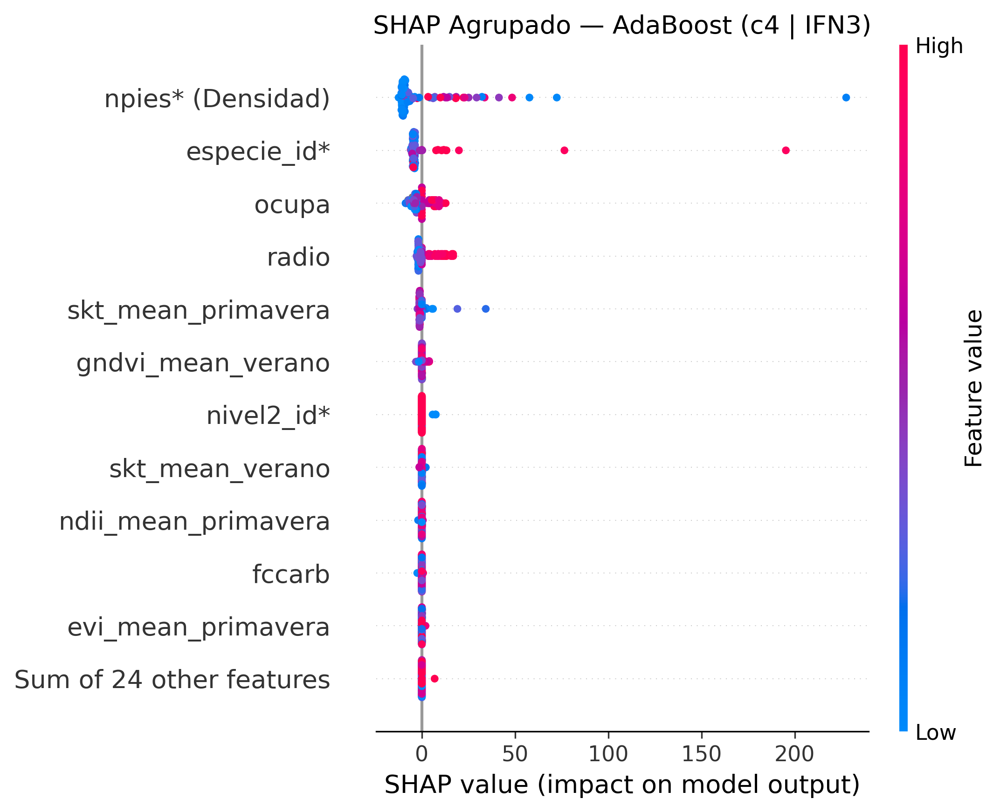

  [OK] BaggedDT


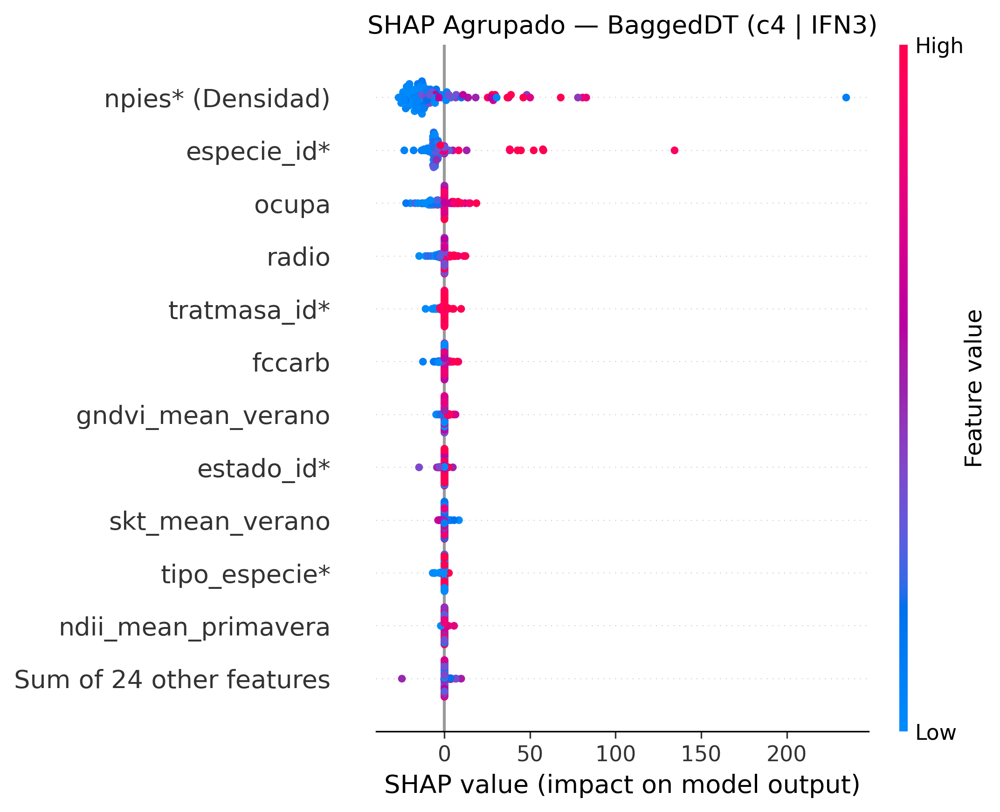

  [OK] BayesianNN


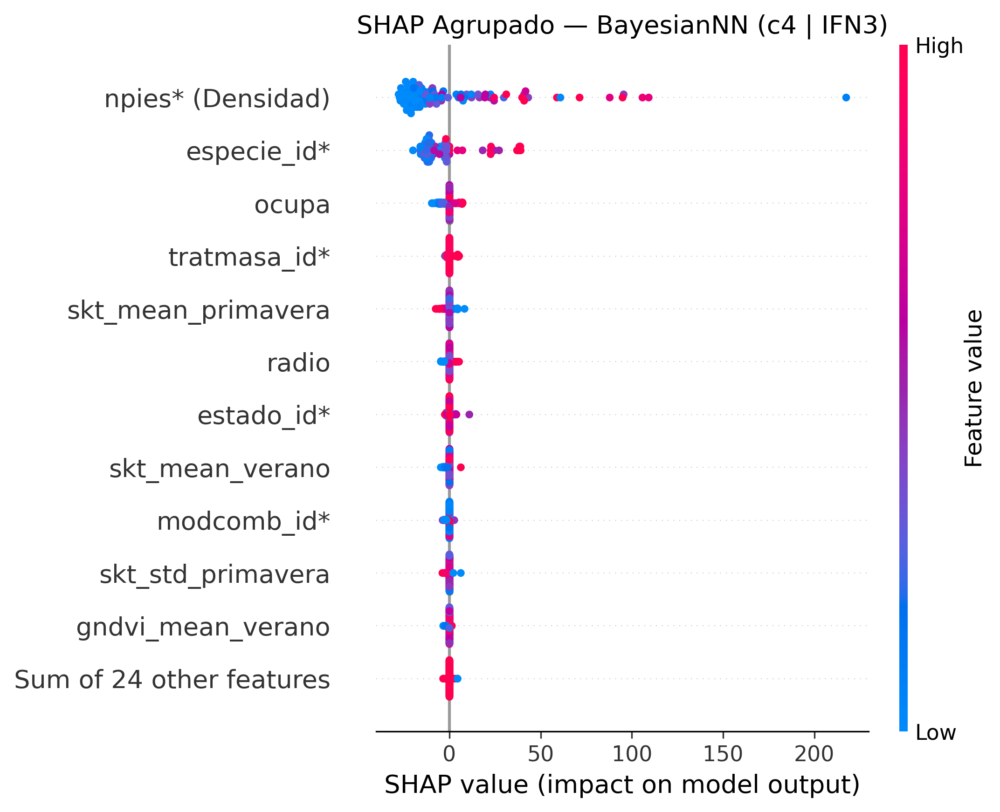

  [OK] CatBoost


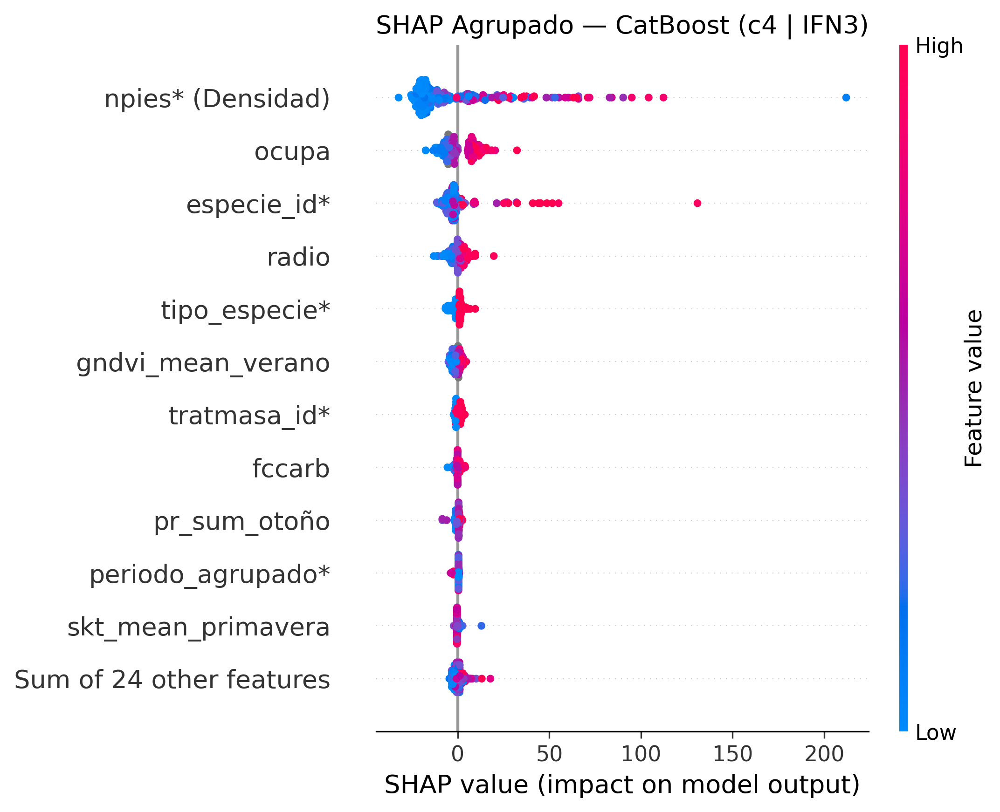

  [OK] GBDT


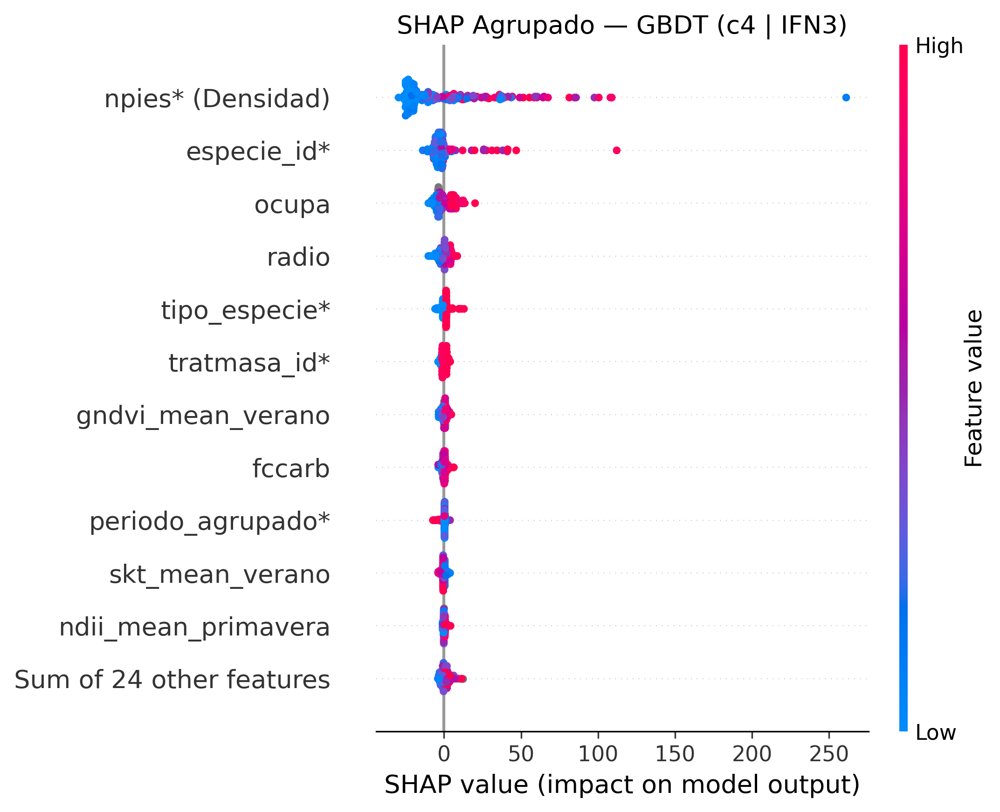

  [OK] KNN


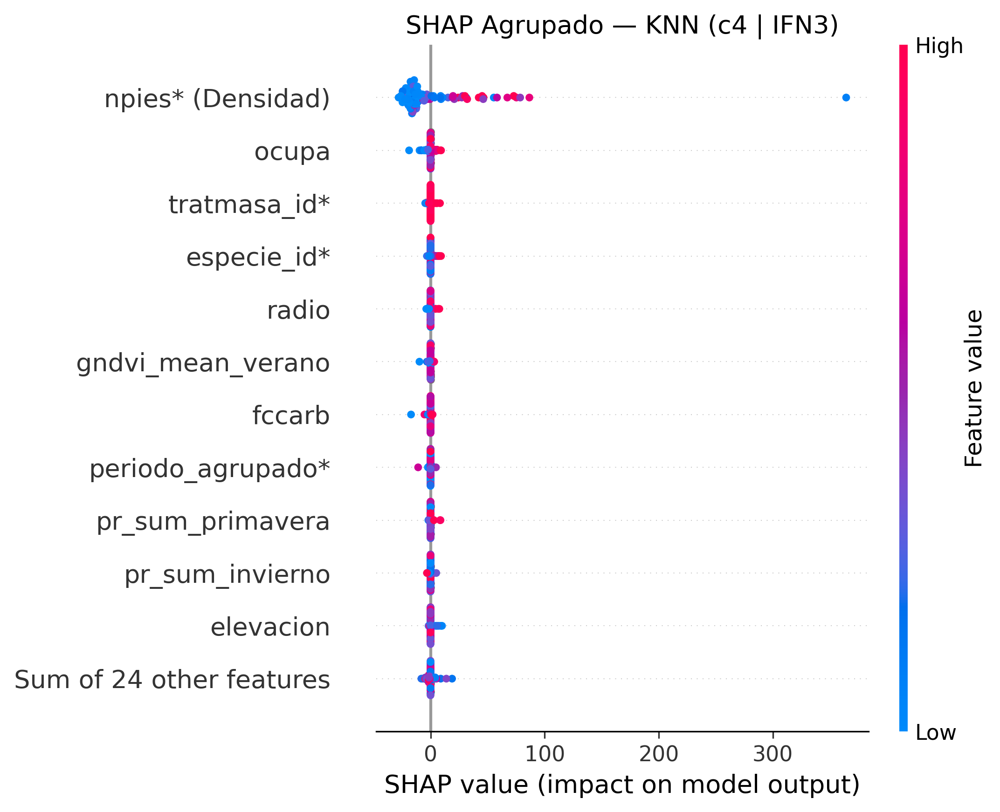

  [OK] LightGBM


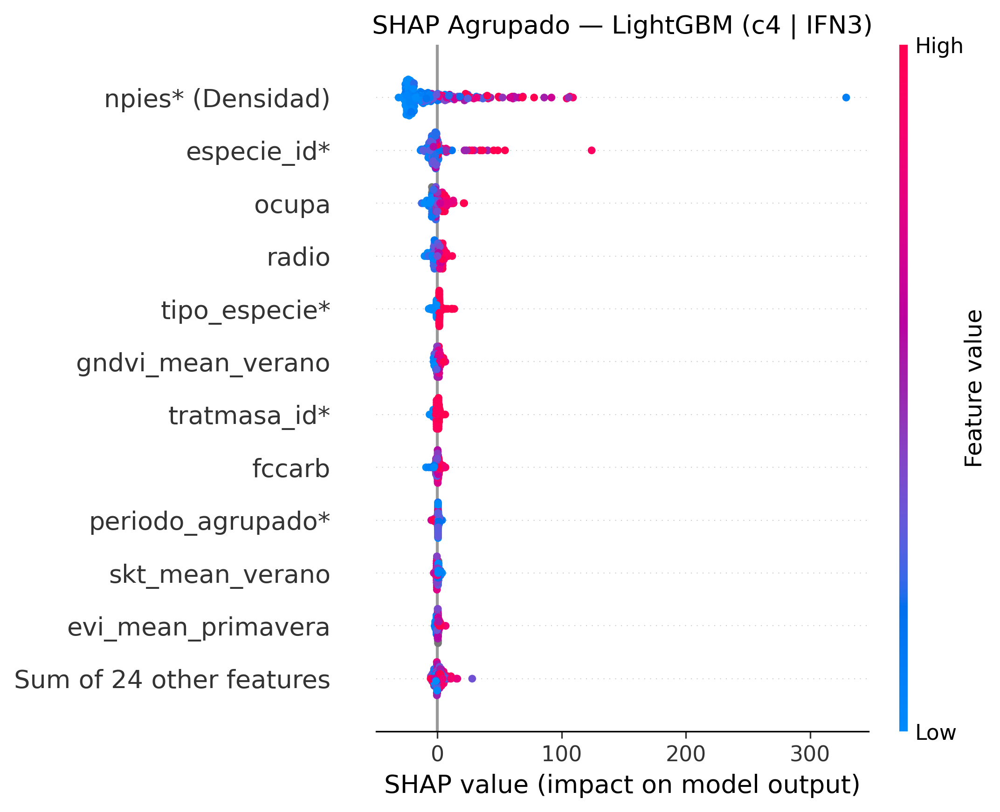

  [OK] MLP_PyTorch


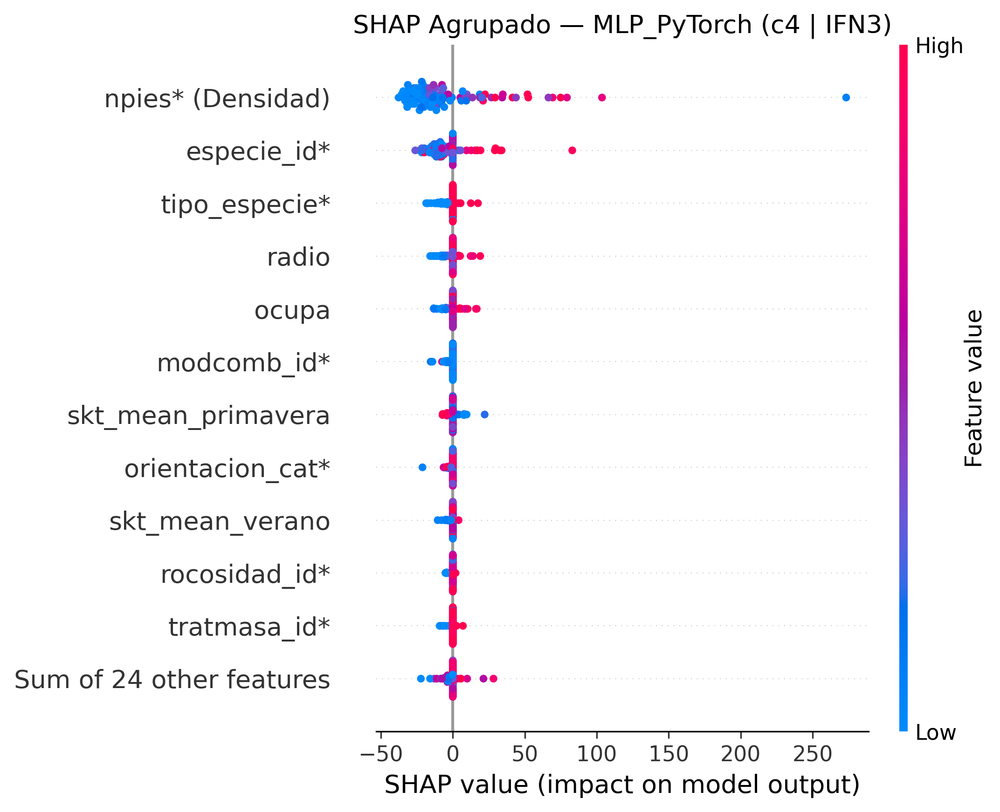

  [OK] Random_Forest


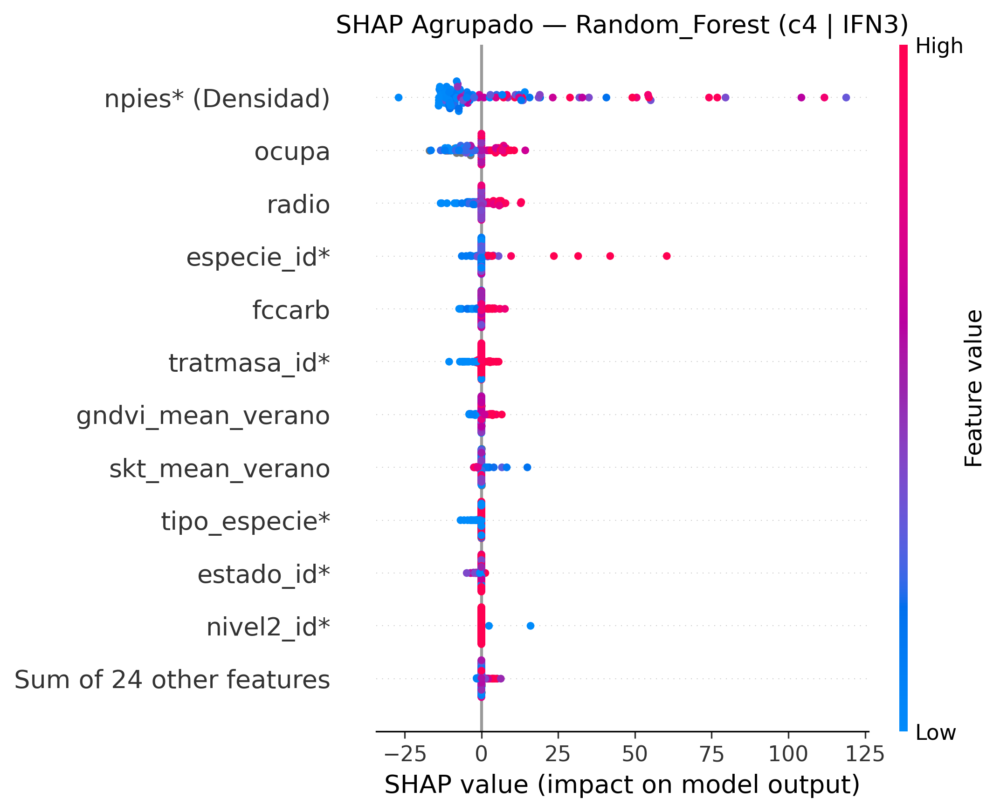

  [OK] SVR


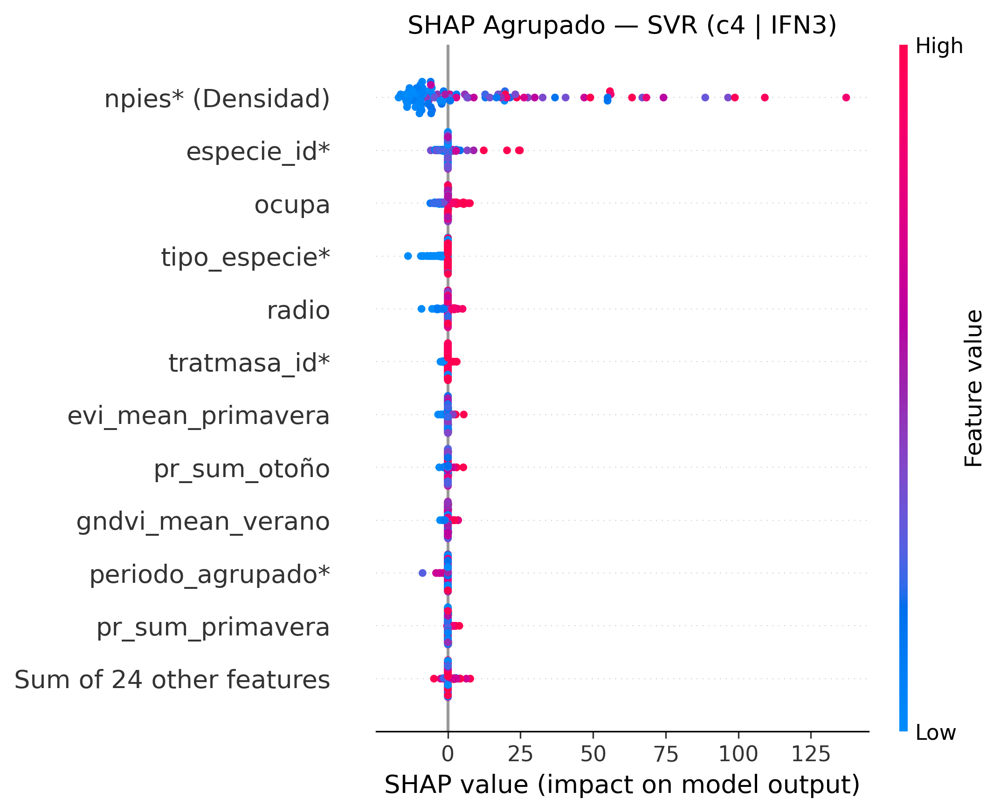

  [OK] XGBoost


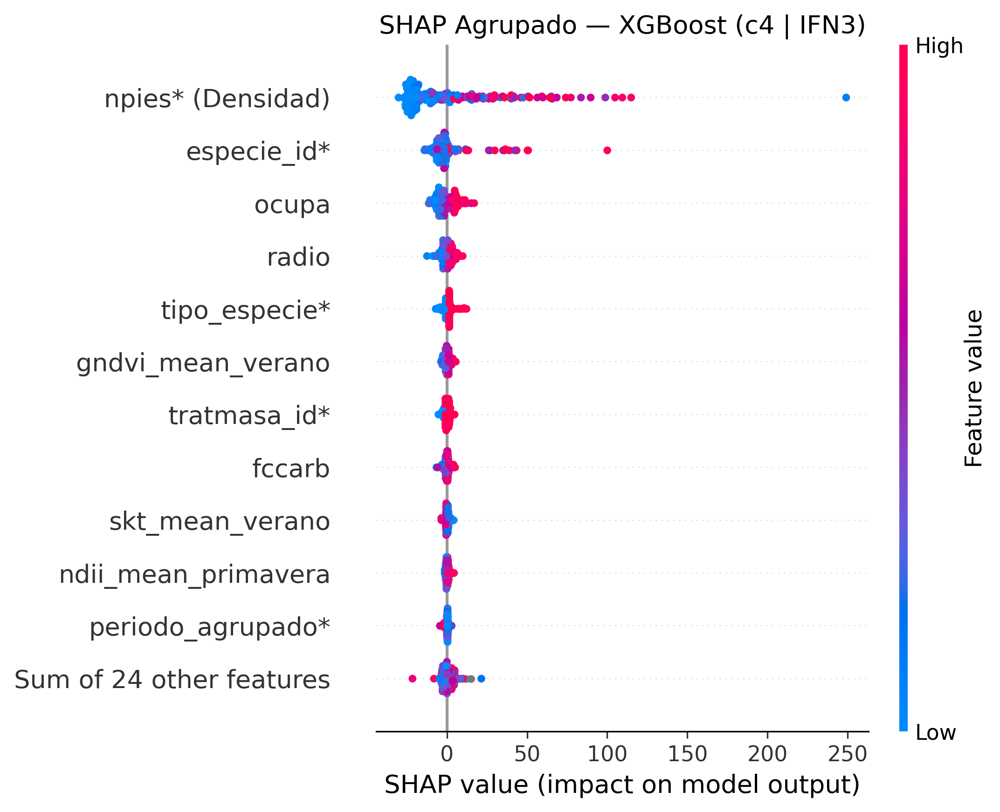


Seccion 1 completada.


In [25]:
model_files_c4 = sorted(
    f for f in os.listdir(MODELS_IFN3_C4)
    if f.endswith('.joblib') and 'training_context' not in f and 'test_indices' not in f
)

out_dir_c4 = OUTPUT_SHAP / 'c4' / 'beeswarm_grouped'
out_dir_c4.mkdir(parents=True, exist_ok=True)

print(f'Modelos c4 a procesar: {len(model_files_c4)}')

for fname in model_files_c4:
    model_name = fname.replace('.joblib', '')
    model_path = MODELS_IFN3_C4 / fname
    save_path  = out_dir_c4 / f'beeswarm_grouped_{model_name}.png'
    cache_path = CACHE_SHAP / 'base' / 'c4' / f'{model_name}.joblib'

    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {model_name}')
        ipy_display(IPImage(str(save_path)))
        continue

    print(f'  {model_name}...', end=' ')
    try:
        shap_vals, feat_names, X_trans_df, X_raw_used, base_val = load_or_compute_shap(
            model_path, X_sample_c4, X_bg_c4, model_name, cache_path=cache_path
        )
        shap_g, data_g, names_g = group_shap_explanation(
            shap_vals, feat_names, X_raw_used, X_trans_df, tm_c4
        )
        explanation = shap.Explanation(
            values=shap_g, base_values=base_val,
            data=data_g, feature_names=names_g
        )
        fig, ax = plt.subplots(figsize=(10, 8))
        shap.plots.beeswarm(explanation, max_display=12, show=False)
        plt.title(f'SHAP Agrupado — {model_name} (c4 | IFN3)', fontsize=13)
        plt.subplots_adjust(left=0.35, bottom=0.10)
        print(f'  -> {save_path}')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
        plt.show()
        plt.close()
        print('OK')
    except Exception as e:
        print(f'ERROR: {e}')
    finally:
        gc.collect()

print('\nSeccion 1 completada.')

---
## 2. SHAP Beeswarm Agrupado — carbono\_bruto4 (IFN3)

Modelos carbono_bruto4 a procesar: 11
  [OK] AdaBoost


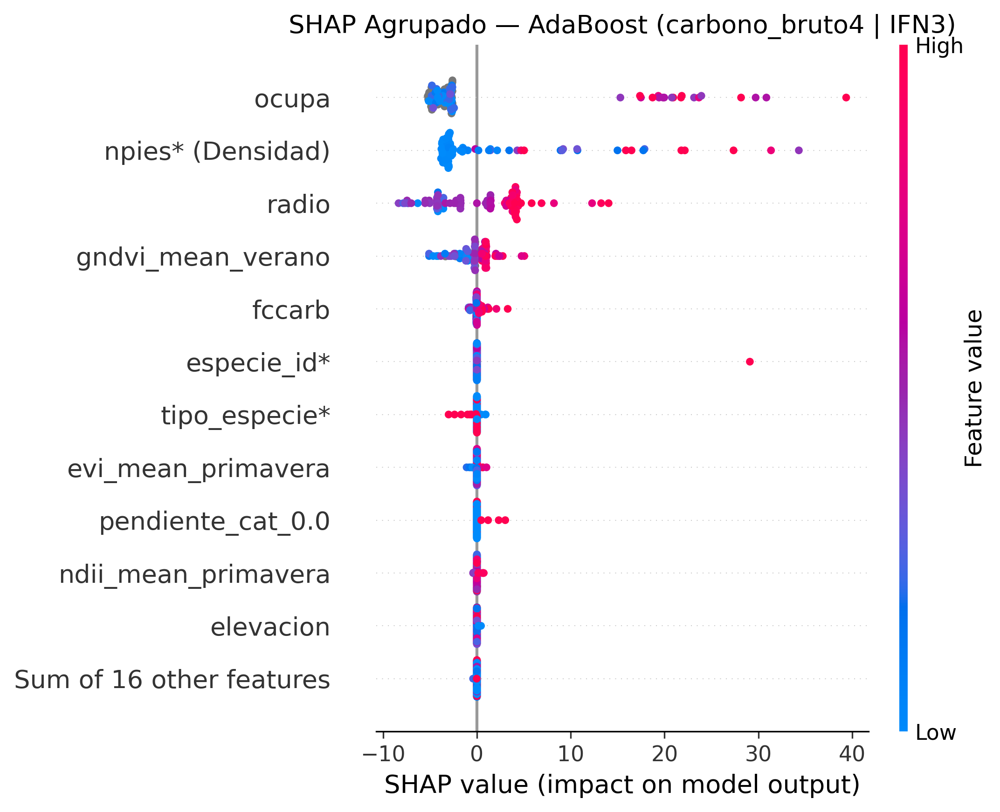

  [OK] BaggedDT


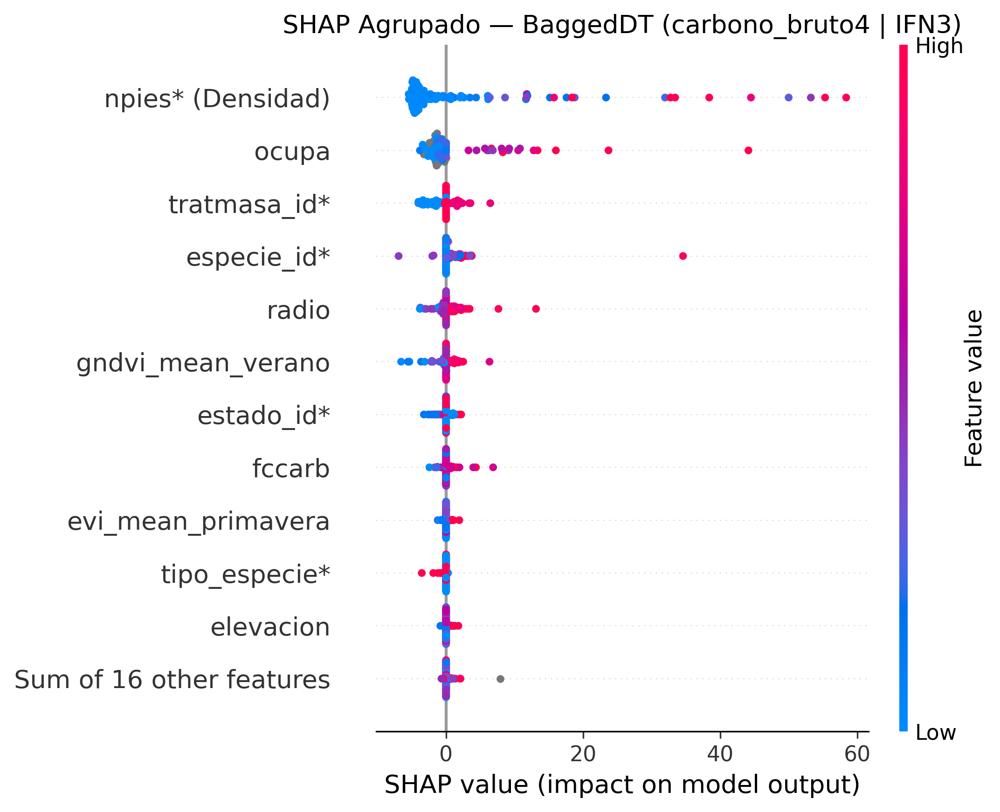

  [OK] BayesianNN


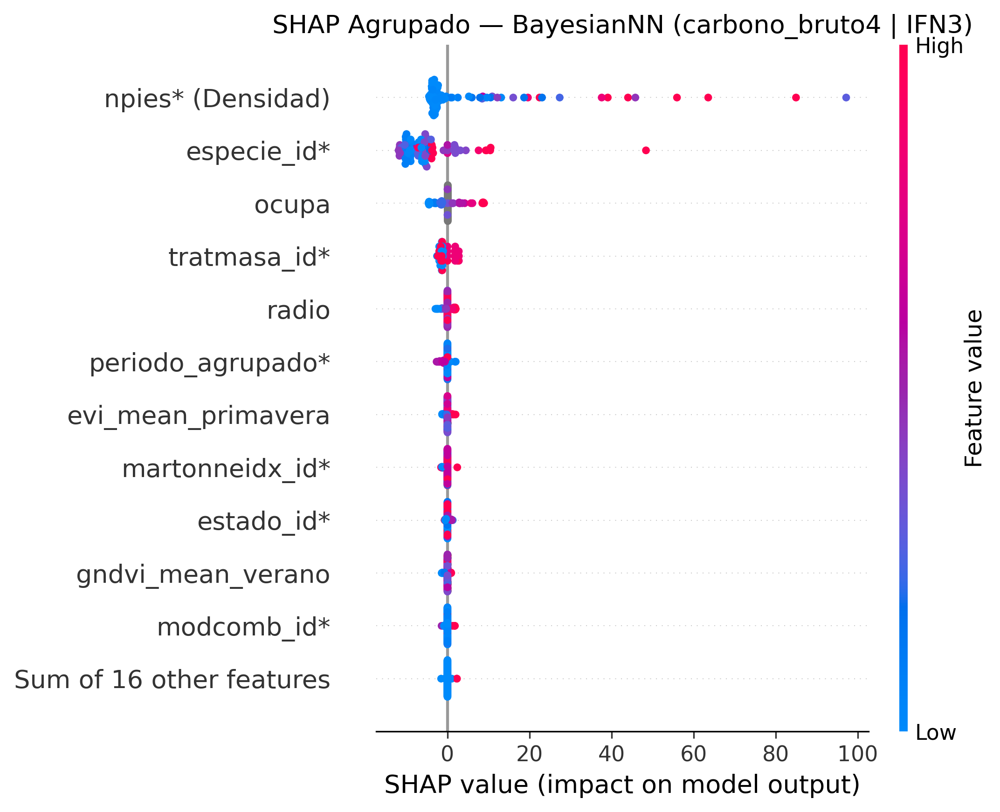

  [OK] CatBoost


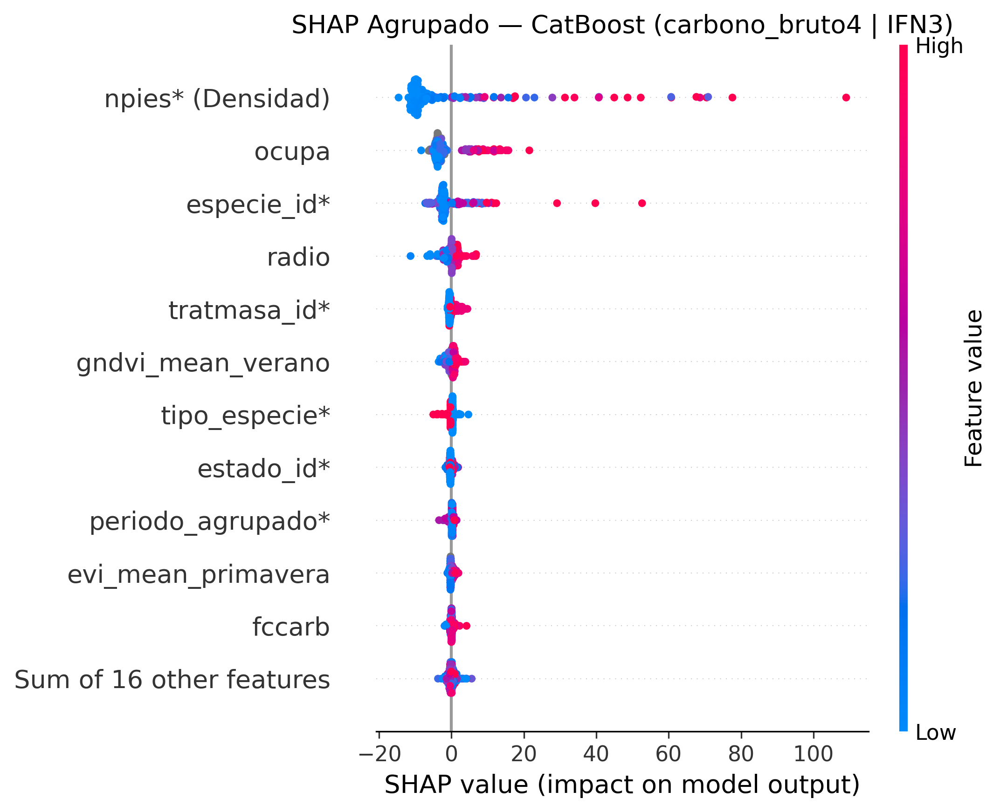

  [OK] GBDT


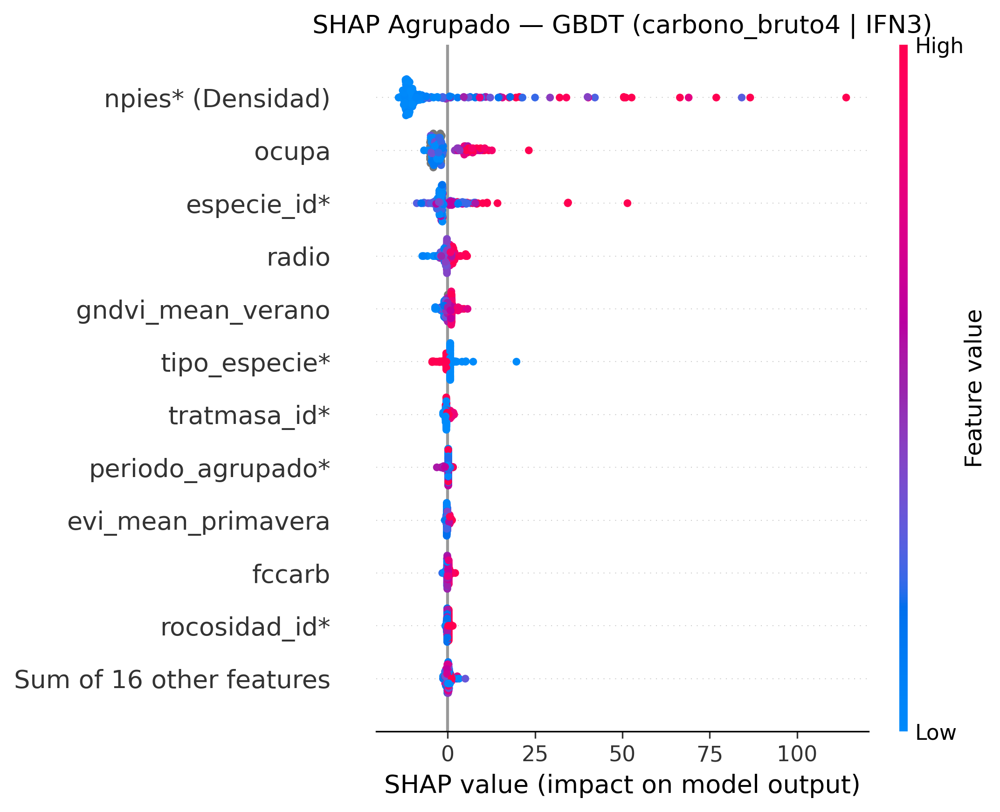

  [OK] KNN


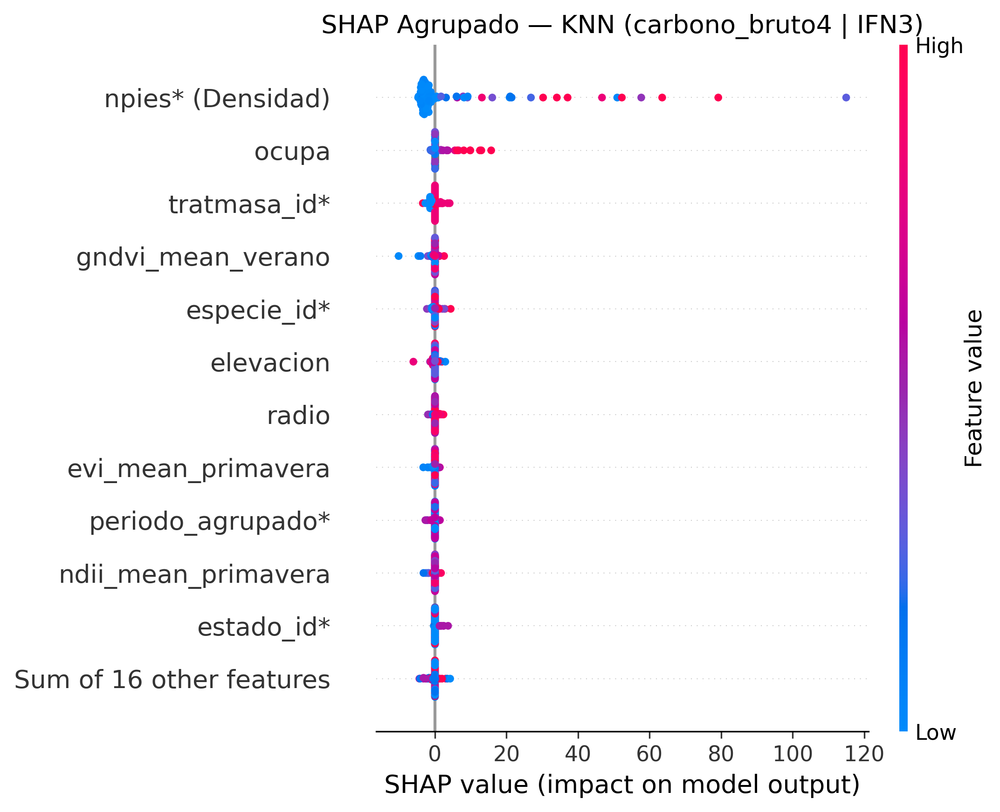

  [OK] LightGBM


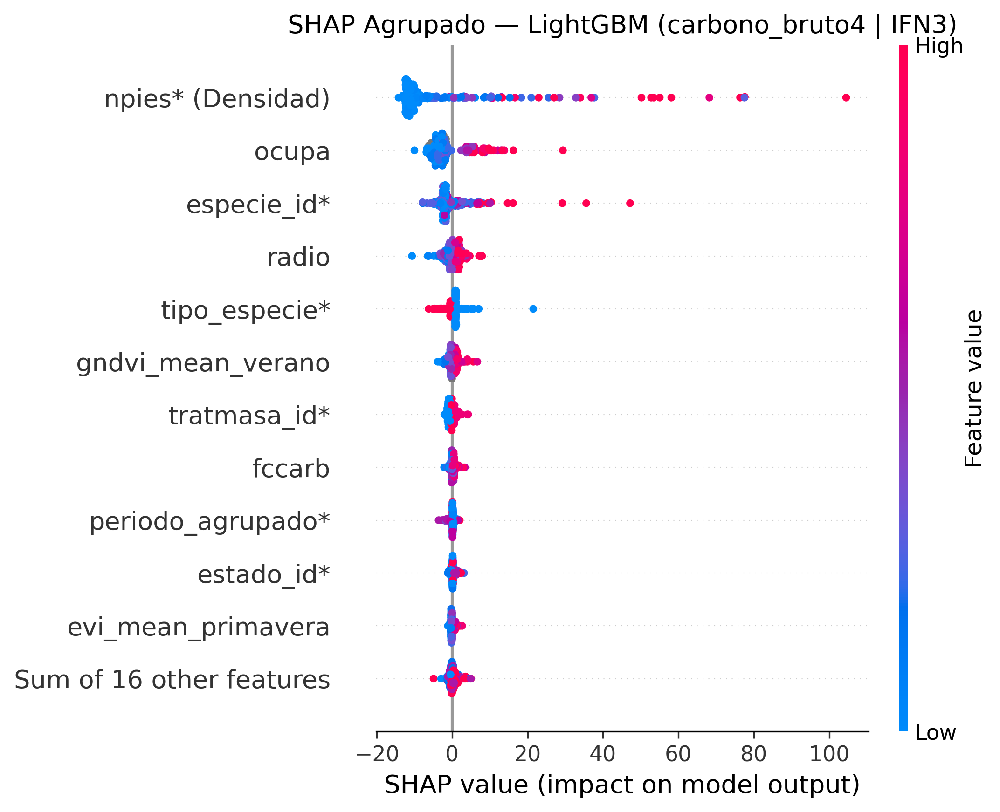

  [OK] MLP_PyTorch


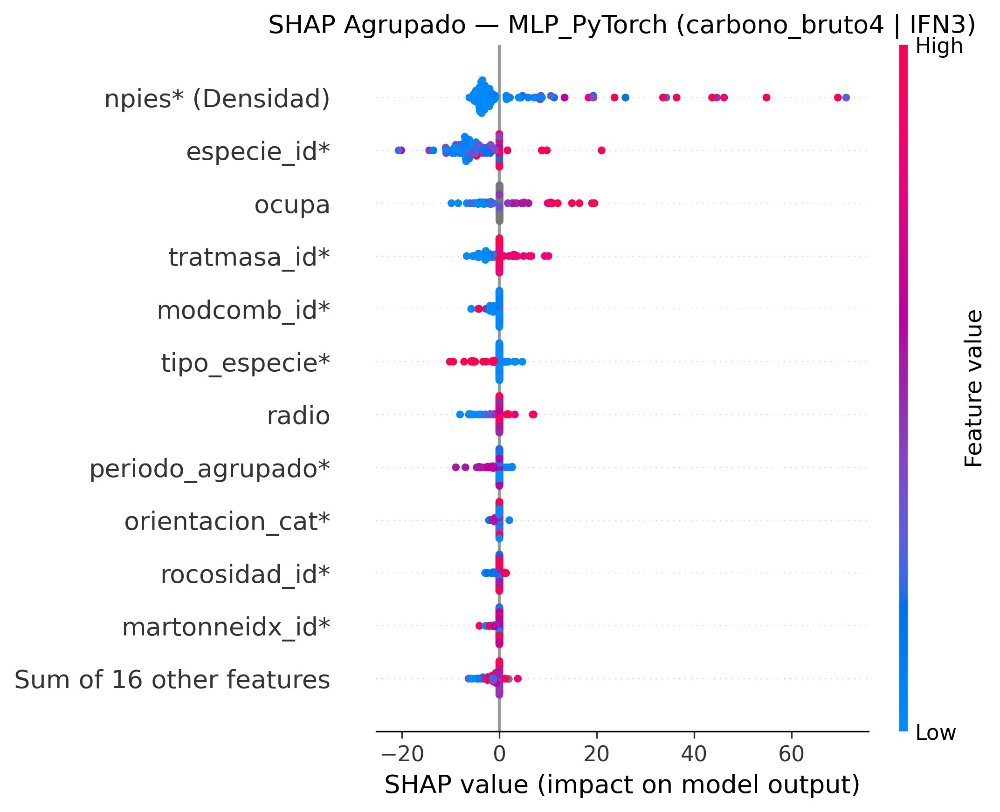

  [OK] Random_Forest


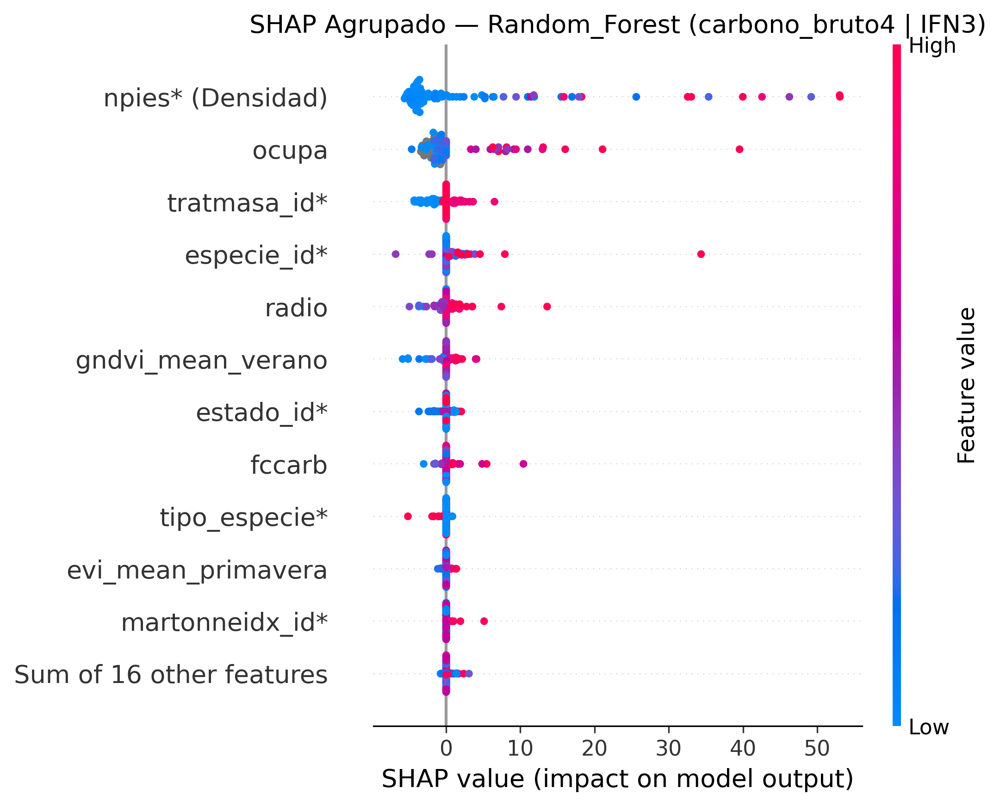

  [OK] SVR


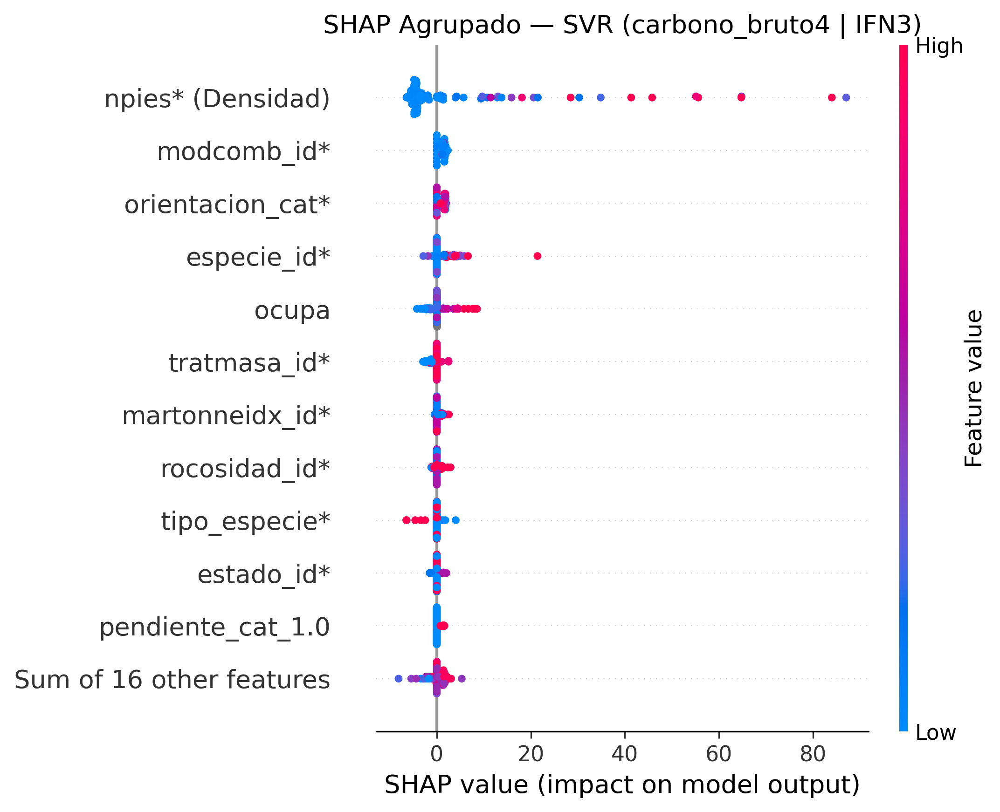

  [OK] XGBoost


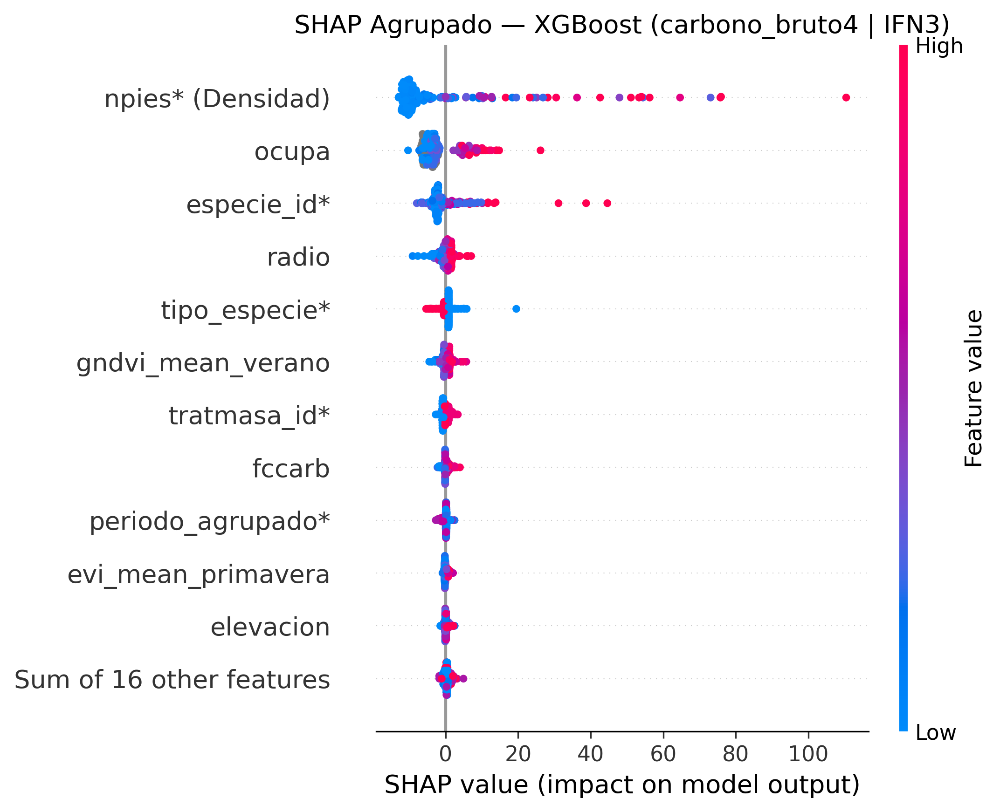


Seccion 2 completada.


In [26]:
model_files_cb4 = sorted(
    f for f in os.listdir(MODELS_IFN3_CB4)
    if f.endswith('.joblib') and 'training_context' not in f and 'test_indices' not in f
)

out_dir_cb4 = OUTPUT_SHAP / 'carbono_bruto4' / 'beeswarm_grouped'
out_dir_cb4.mkdir(parents=True, exist_ok=True)

print(f'Modelos carbono_bruto4 a procesar: {len(model_files_cb4)}')

for fname in model_files_cb4:
    model_name = fname.replace('.joblib', '')
    model_path = MODELS_IFN3_CB4 / fname
    save_path  = out_dir_cb4 / f'beeswarm_grouped_{model_name}.png'
    cache_path = CACHE_SHAP / 'base' / 'carbono_bruto4' / f'{model_name}.joblib'

    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {model_name}')
        ipy_display(IPImage(str(save_path)))
        continue

    print(f'  {model_name}...', end=' ')
    try:
        shap_vals, feat_names, X_trans_df, X_raw_used, base_val = load_or_compute_shap(
            model_path, X_sample_cb4, X_bg_cb4, model_name, cache_path=cache_path
        )
        shap_g, data_g, names_g = group_shap_explanation(
            shap_vals, feat_names, X_raw_used, X_trans_df, tm_cb4
        )
        explanation = shap.Explanation(
            values=shap_g, base_values=base_val,
            data=data_g, feature_names=names_g
        )
        fig, ax = plt.subplots(figsize=(10, 8))
        shap.plots.beeswarm(explanation, max_display=12, show=False)
        plt.title(f'SHAP Agrupado — {model_name} (carbono_bruto4 | IFN3)', fontsize=13)
        plt.subplots_adjust(left=0.35, bottom=0.10)
        print(f'  -> {save_path}')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
        plt.show()
        plt.close()
        print('OK')
    except Exception as e:
        print(f'ERROR: {e}')
    finally:
        gc.collect()

print('\nSeccion 2 completada.')

---
## 3. SHAP Dependence — c4 (IFN3, CatBoost)

Gráficos de dependencia SHAP para el modelo **CatBoost** (IFN3, target `c4`).

### 3.1 Variables generales
Features: `fccarb`, `elevacion`, `gndvi_mean_verano`, `evi_mean_primavera`, `skt_mean_verano`, `pr_sum_primavera`

In [27]:
# Muestra más grande para dependence plots (2000 instancias del test set)
X_dep_c4 = X_test_c4.sample(min(2000, len(X_test_c4)), random_state=42)

cache_dep_c4 = CACHE_SHAP / 'dependence' / 'c4' / 'CatBoost_2000.joblib'

if cache_dep_c4.exists():
    print('Cargando SHAP values CatBoost c4 desde caché...')
    _d = joblib.load(cache_dep_c4)
    feat_names_c4 = _d['feat_names']
    shap_vals_c4  = _d['shap_vals']
    X_df_c4       = _d['X_df']
    del _d; gc.collect()
else:
    print('Cargando CatBoost c4...')
    pipeline_catboost_c4 = joblib.load(MODELS_IFN3_C4 / 'CatBoost.joblib')

    preprocessor_c4 = pipeline_catboost_c4.named_steps['preprocessor']
    model_c4        = pipeline_catboost_c4.named_steps['regressor']

    feat_names_c4 = get_feature_names(preprocessor_c4)
    X_trans_c4    = preprocessor_c4.transform(X_dep_c4)
    if X_trans_c4.shape[1] != len(feat_names_c4):
        feat_names_c4 = [f'f_{i:03d}' for i in range(X_trans_c4.shape[1])]
    X_df_c4 = pd.DataFrame(X_trans_c4, columns=feat_names_c4)

    print('Calculando SHAP values (TreeExplainer)...')
    explainer_c4  = shap.TreeExplainer(model_c4)
    shap_vals_c4  = explainer_c4.shap_values(X_df_c4)
    if isinstance(shap_vals_c4, list):
        shap_vals_c4 = shap_vals_c4[0]

    del pipeline_catboost_c4, preprocessor_c4, model_c4, explainer_c4
    gc.collect()

    cache_dep_c4.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({'feat_names': feat_names_c4, 'shap_vals': shap_vals_c4, 'X_df': X_df_c4},
                cache_dep_c4, compress=3)
    print('Caché guardada.')

print(f'SHAP values: {shap_vals_c4.shape}')

Cargando SHAP values CatBoost c4 desde caché...
SHAP values: (2000, 211)


  [OK] fccarb


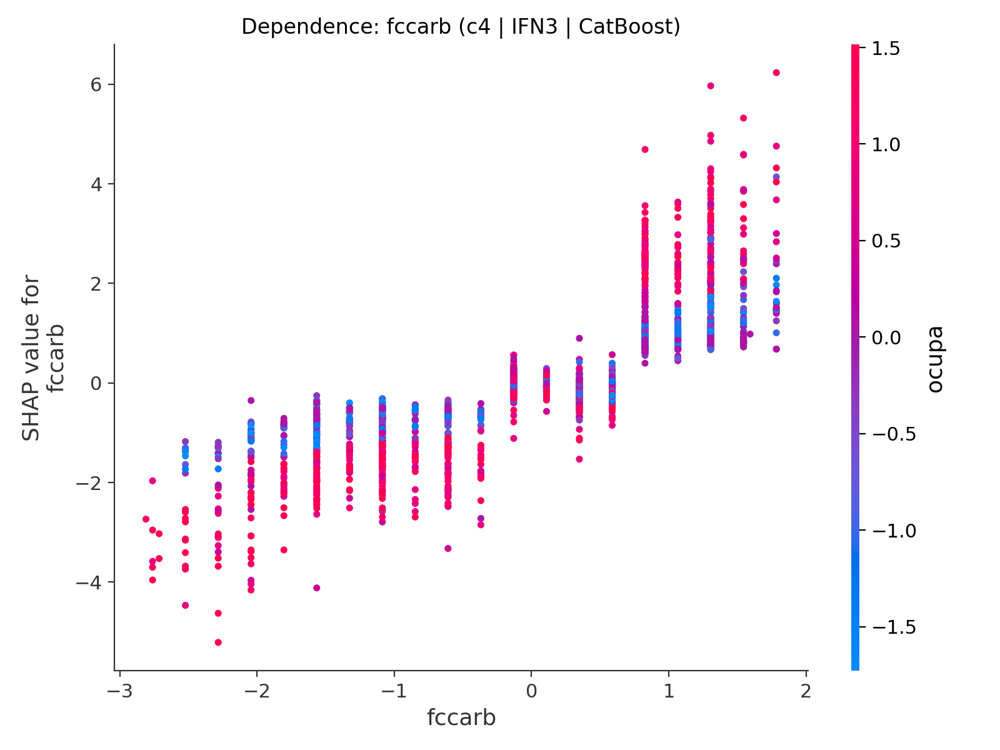

  [OK] elevacion


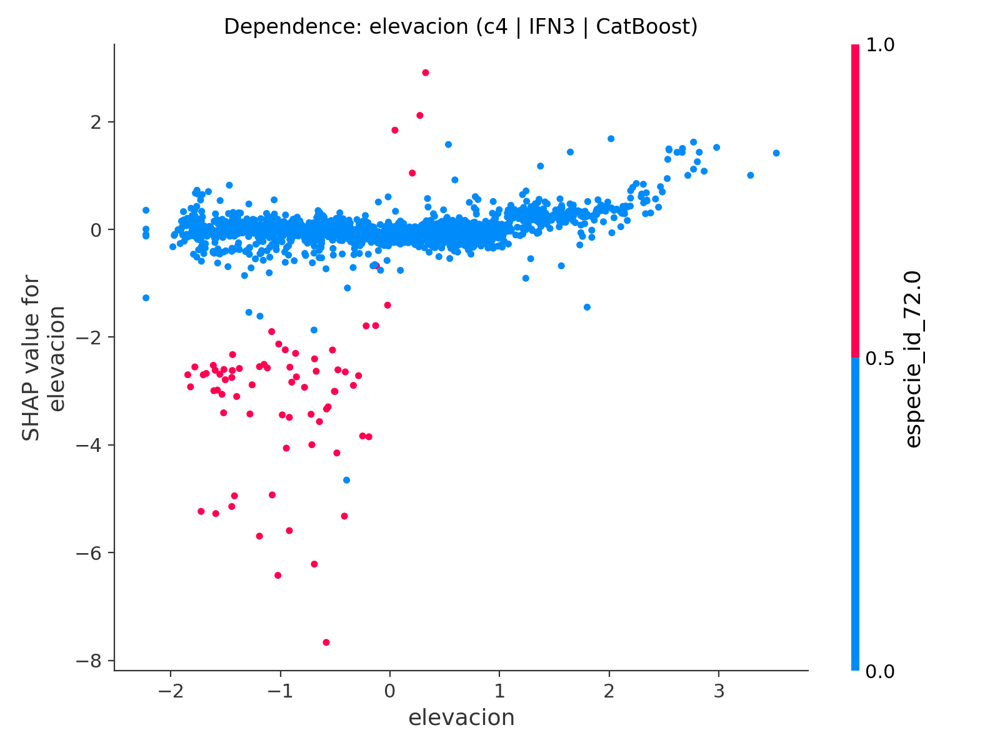

  [OK] gndvi_mean_verano


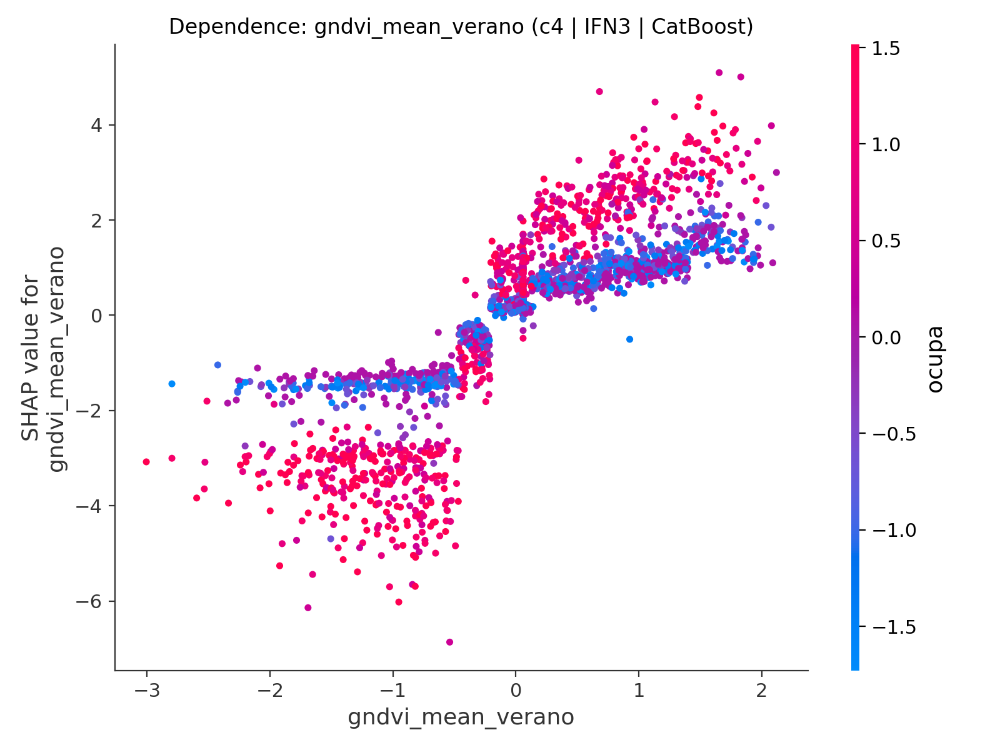

  [OK] evi_mean_primavera


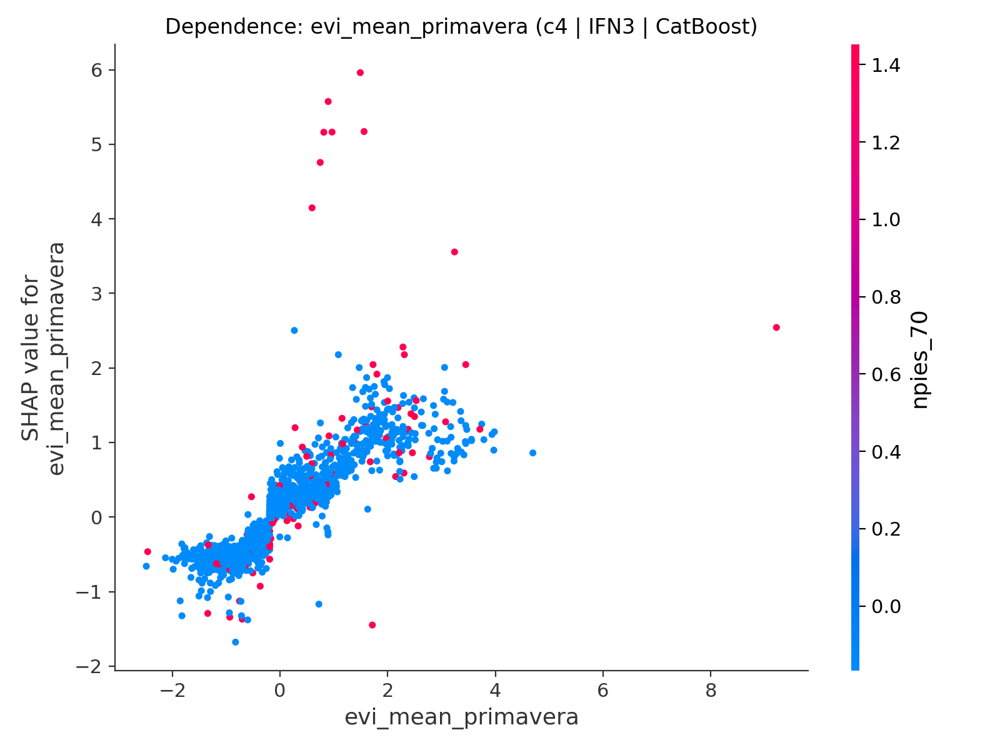

  [OK] skt_mean_verano


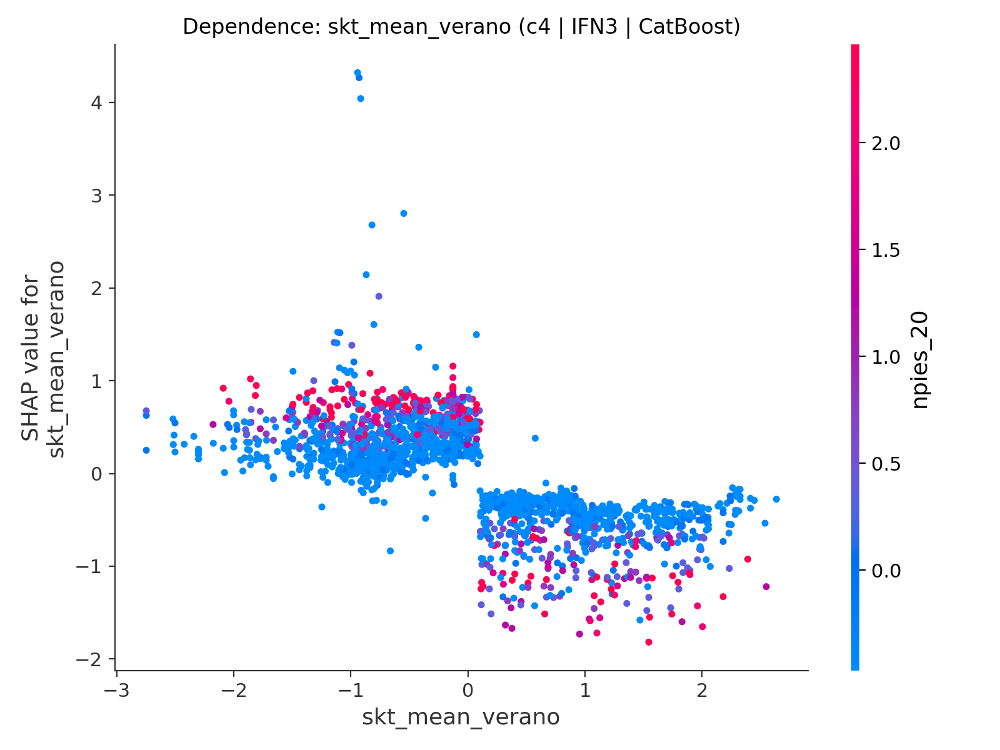

  [OK] pr_sum_primavera


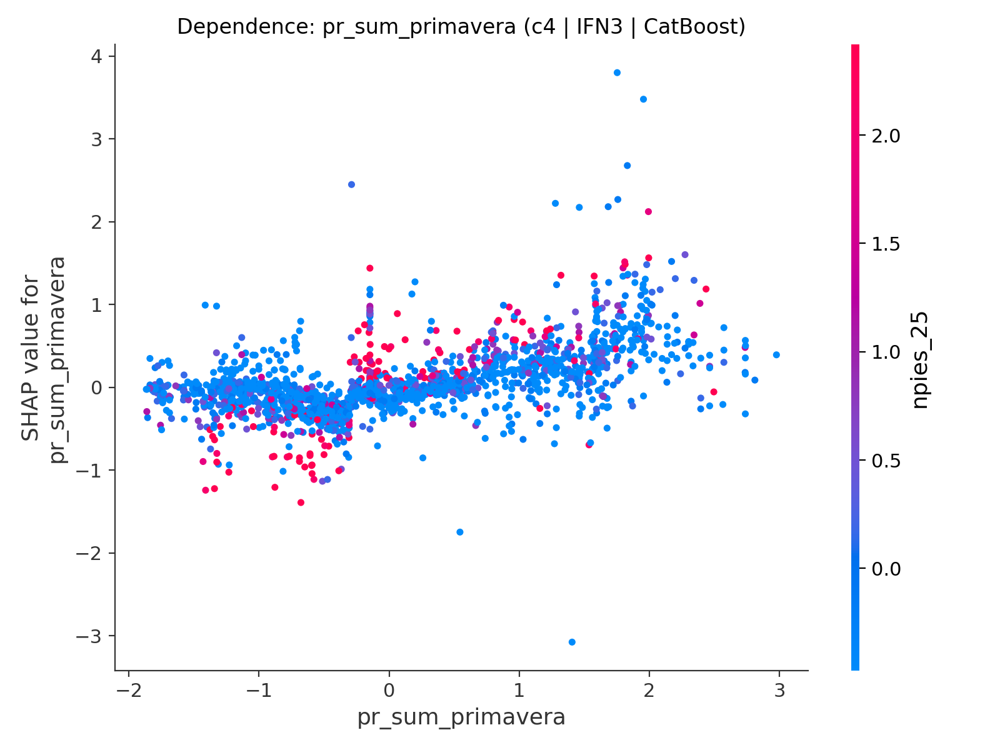

Dependence plots generales c4 completados.


In [28]:
# Dependence plots — variables generales c4
feats_generales_c4 = [
    'fccarb', 'elevacion', 'gndvi_mean_verano',
    'evi_mean_primavera', 'skt_mean_verano', 'pr_sum_primavera'
]

out_dep_c4 = OUTPUT_SHAP / 'c4' / 'dependence'
out_dep_c4.mkdir(parents=True, exist_ok=True)

for feat in feats_generales_c4:
    save_path = out_dep_c4 / f'dep_{feat}.png'
    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {feat}')
        ipy_display(IPImage(str(save_path)))
        continue
    col = next((f for f in feat_names_c4 if feat in f), None)
    if col is None:
        print(f'  Feature {feat} no encontrada, omitiendo')
        continue
    fig, ax = plt.subplots(figsize=(8, 6))
    shap.dependence_plot(col, shap_vals_c4, X_df_c4, display_features=X_df_c4, show=False, ax=ax)
    ax.set_title(f'Dependence: {feat} (c4 | IFN3 | CatBoost)', fontsize=12)
    plt.tight_layout()
    print(f'  -> {save_path}')
    plt.savefig(save_path, dpi=300)
    plt.savefig(save_path.with_suffix('.pdf'))
    plt.show()
    plt.close()

print('Dependence plots generales c4 completados.')

### 3.2 Estructura diamétrica vs tipo de especie (c4)

SHAP dependence de cada clase diamétrica (`npies_*`) coloreado por `tipo_especie` (0=Conífera, 1=Frondosa).

  [OK] npies_1


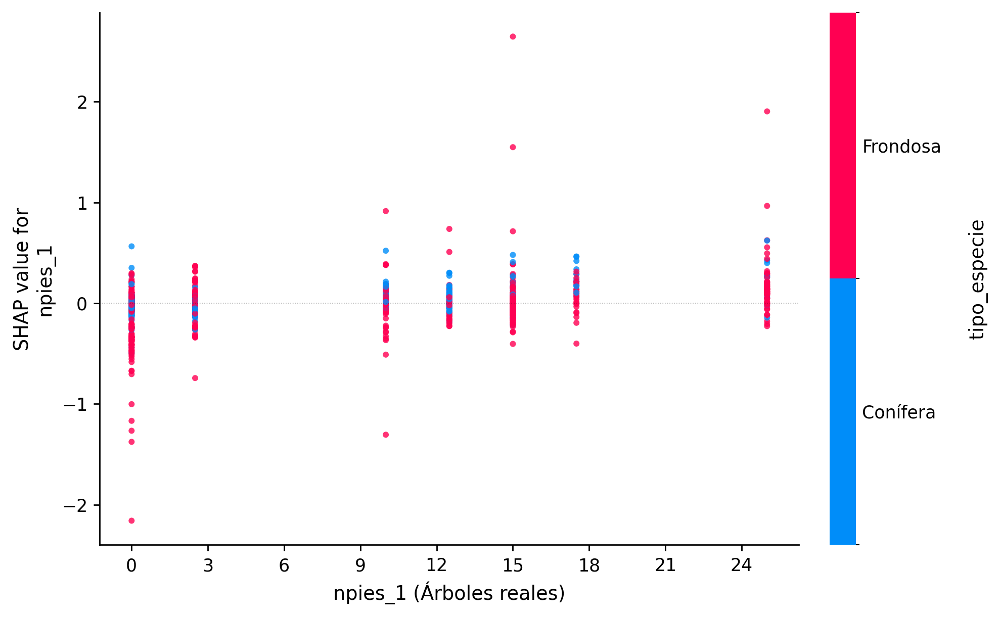

  [OK] npies_2


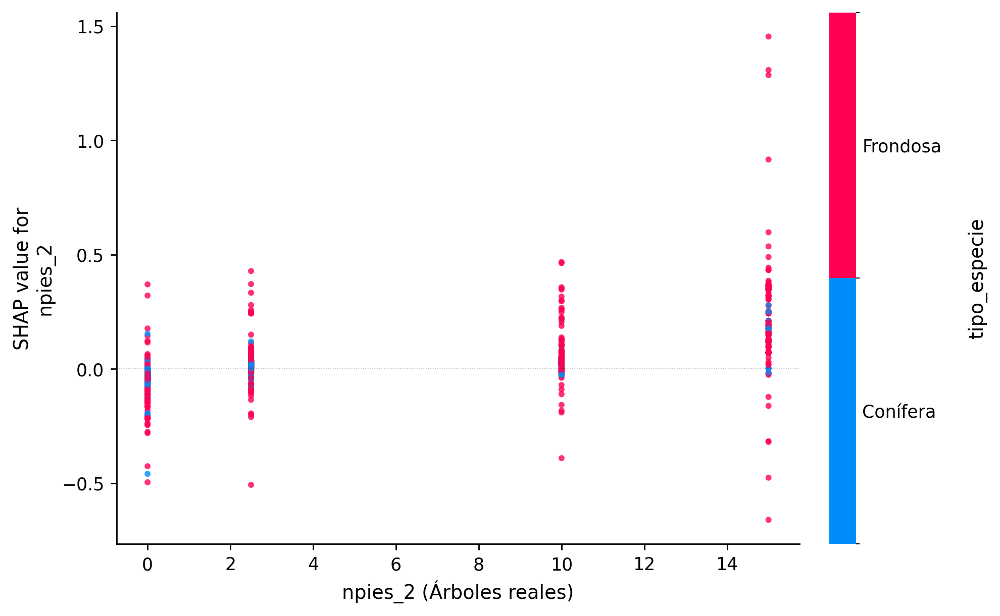

  [OK] npies_5


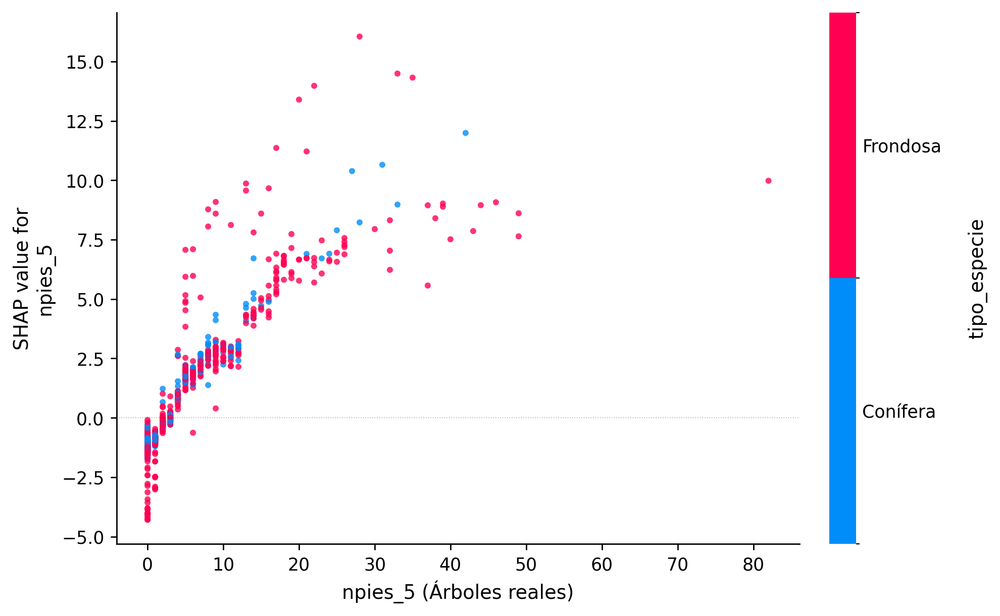

  [OK] npies_10


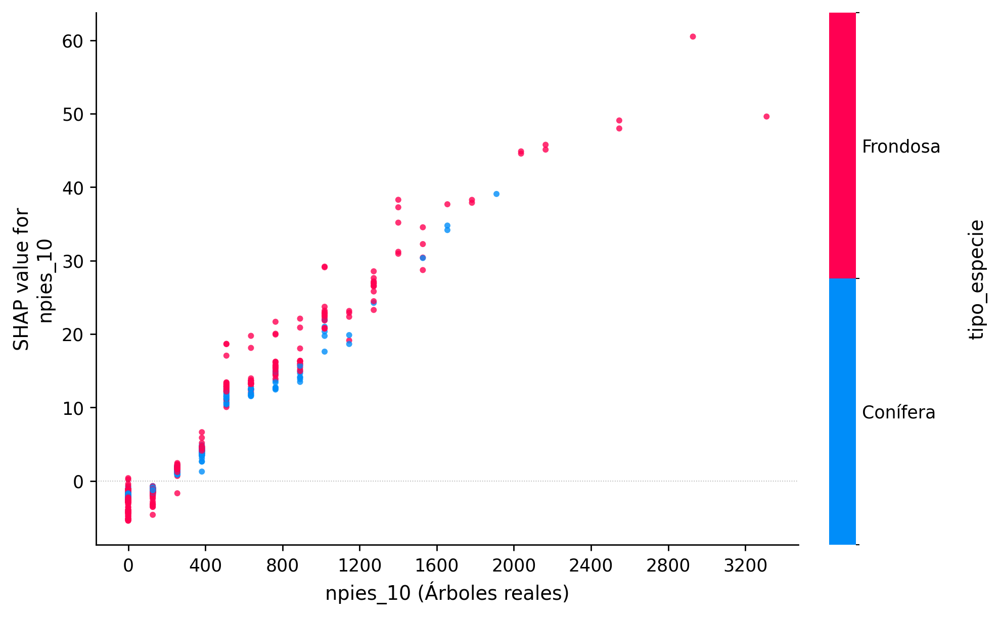

  [OK] npies_15


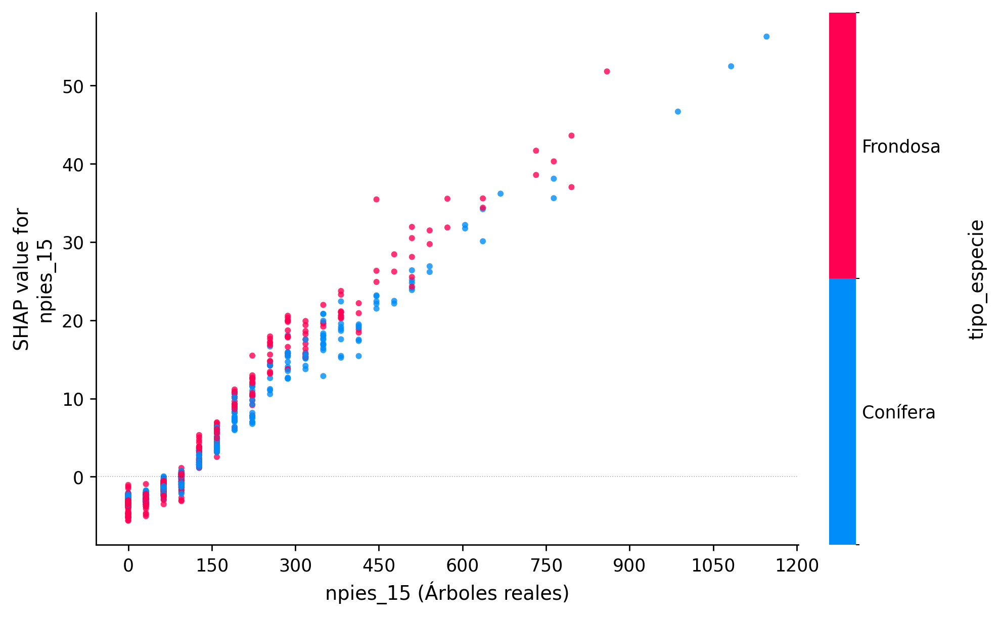

  [OK] npies_20


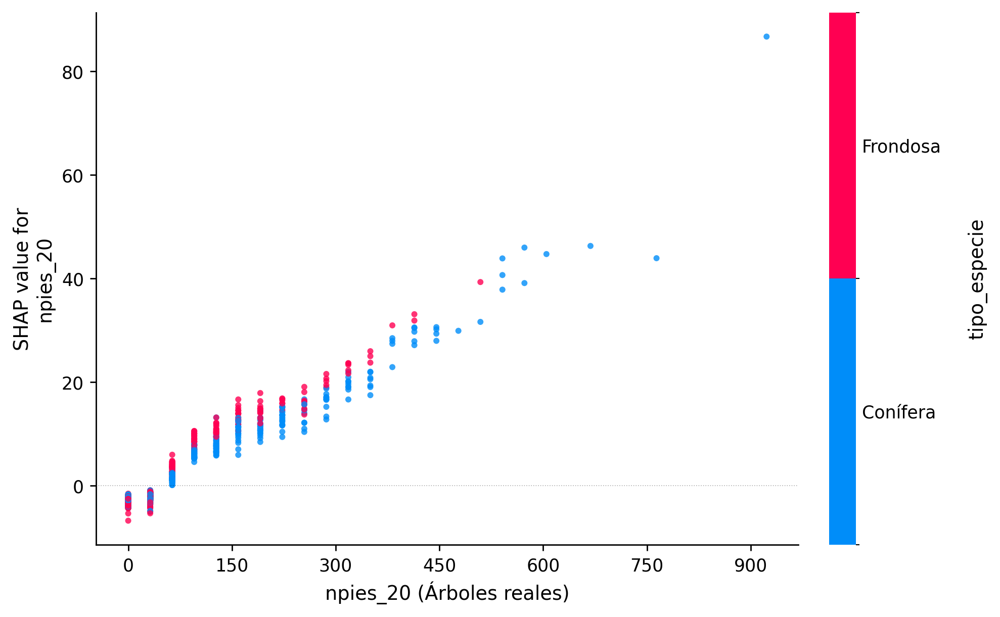

  [OK] npies_25


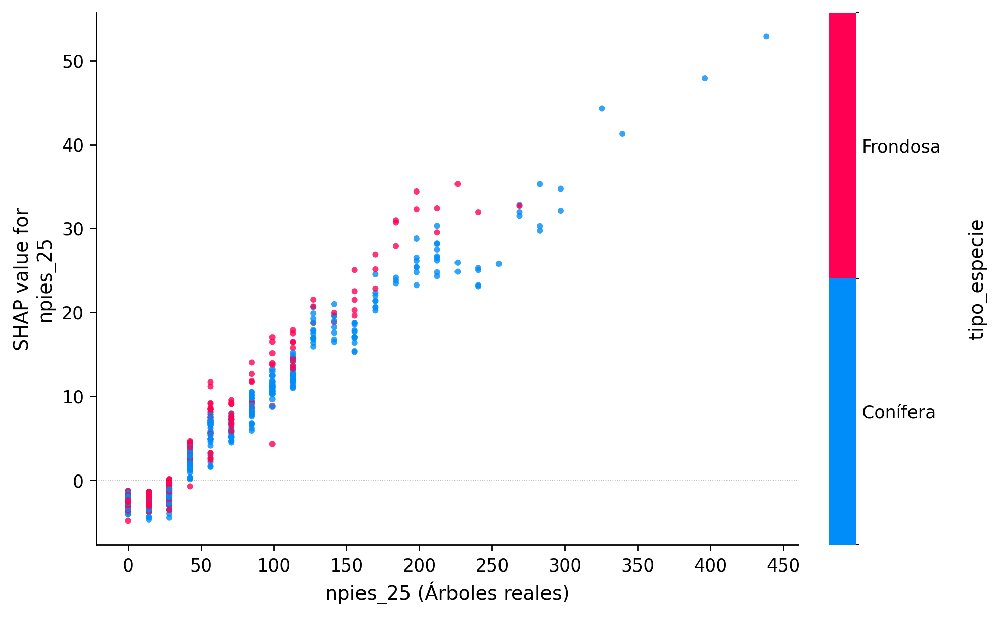

  [OK] npies_30


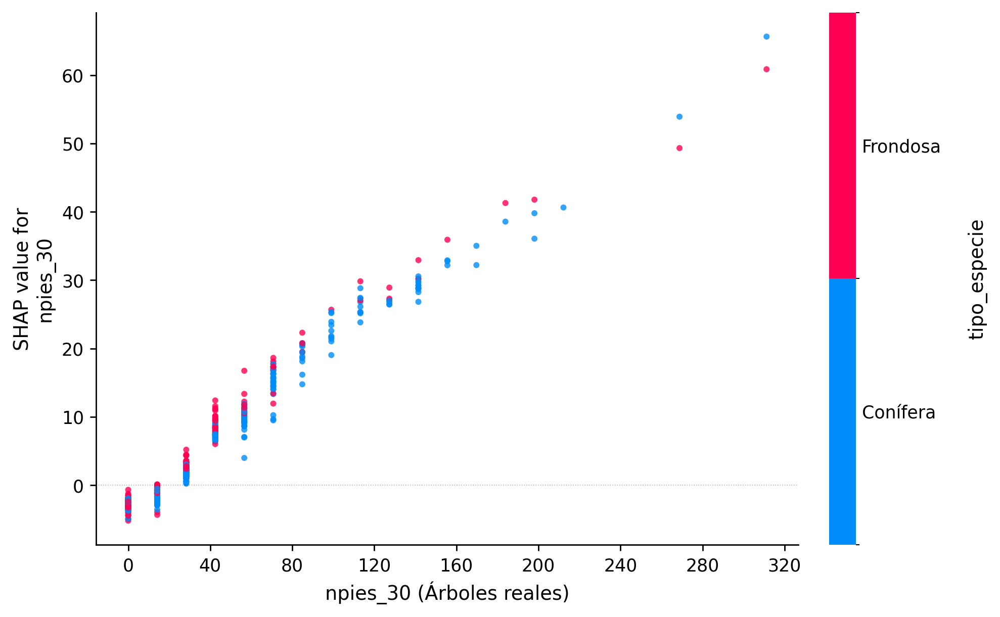

  [OK] npies_35


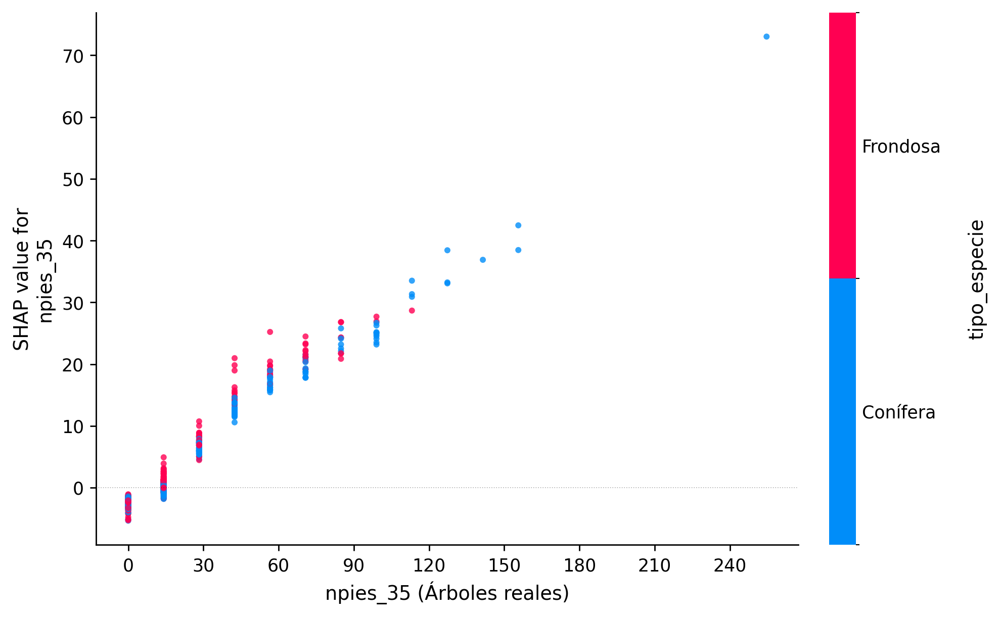

  [OK] npies_40


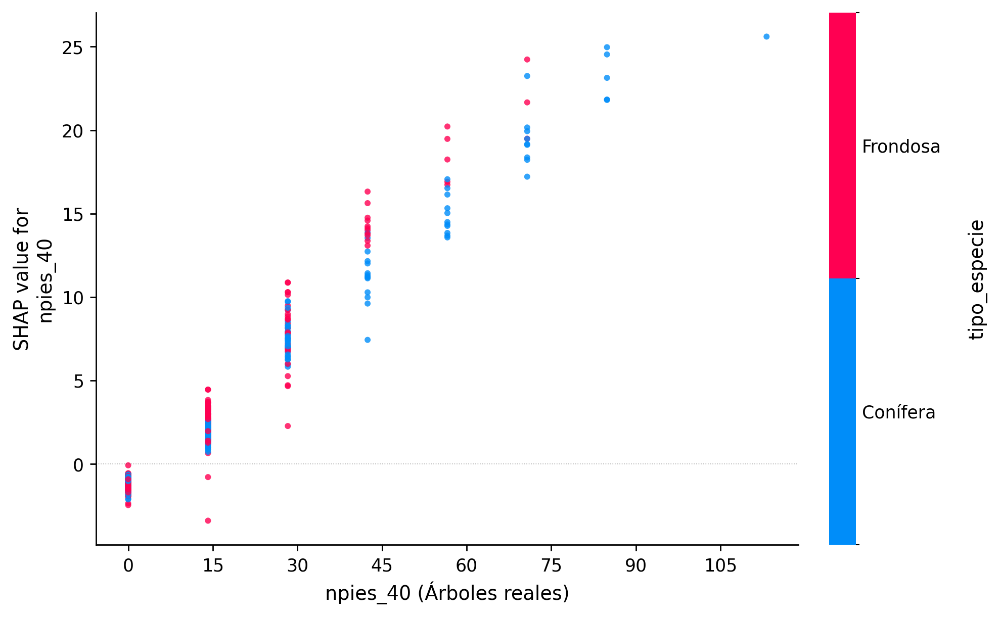

  [OK] npies_45


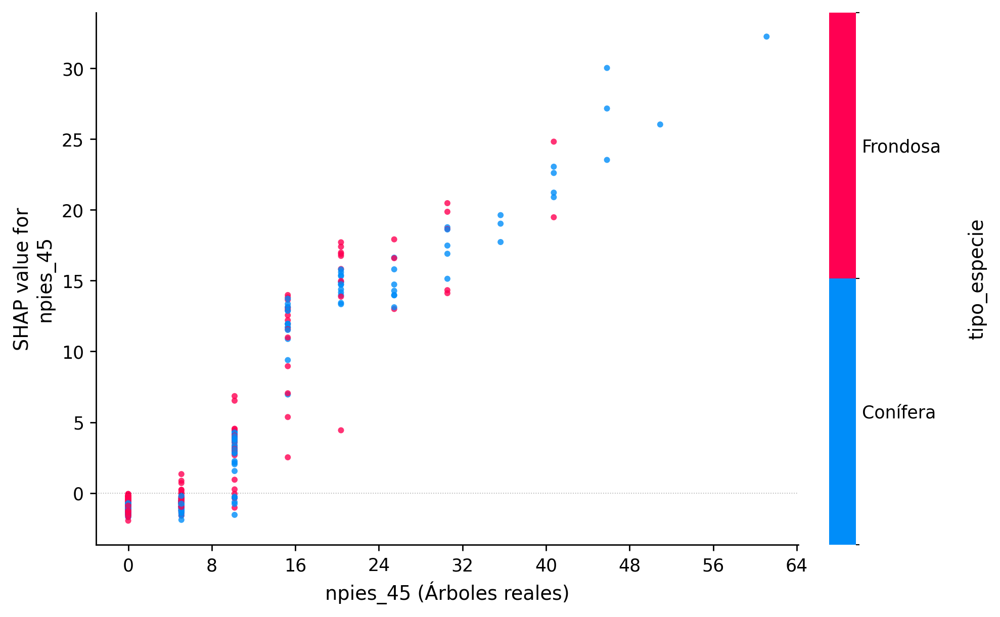

  [OK] npies_50


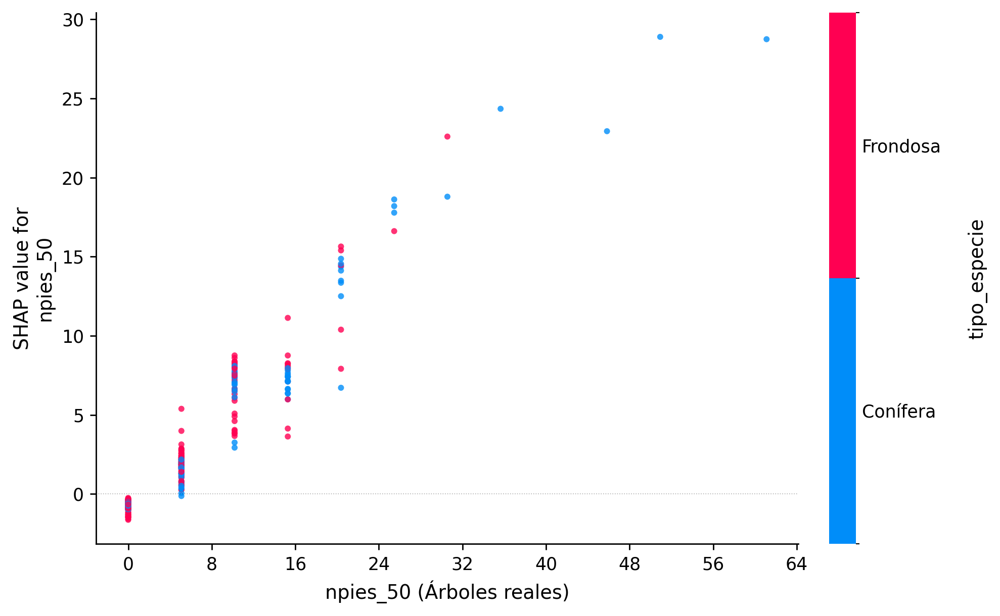

  [OK] npies_55


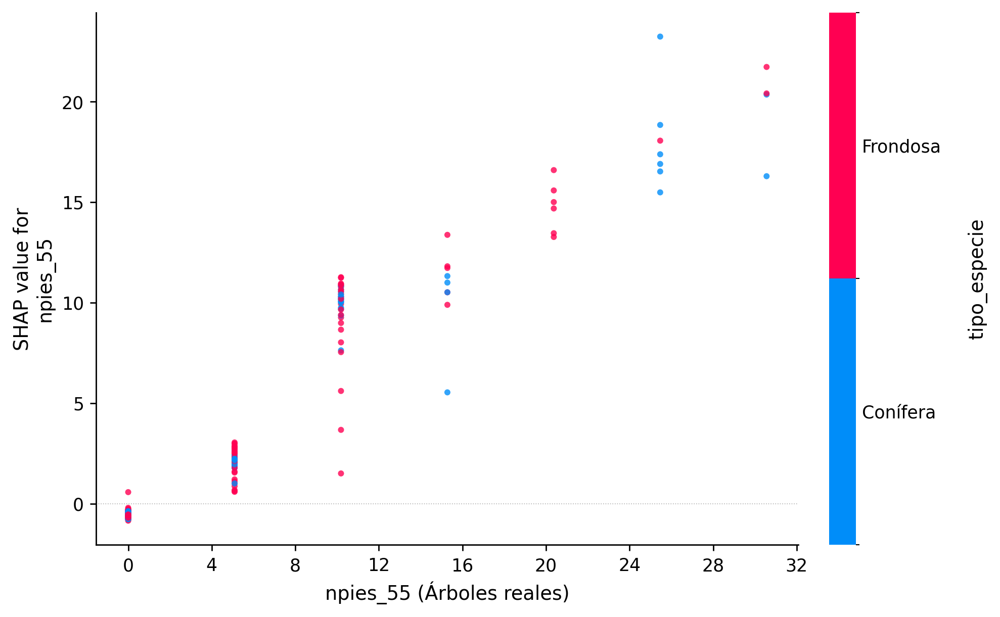

  [OK] npies_60


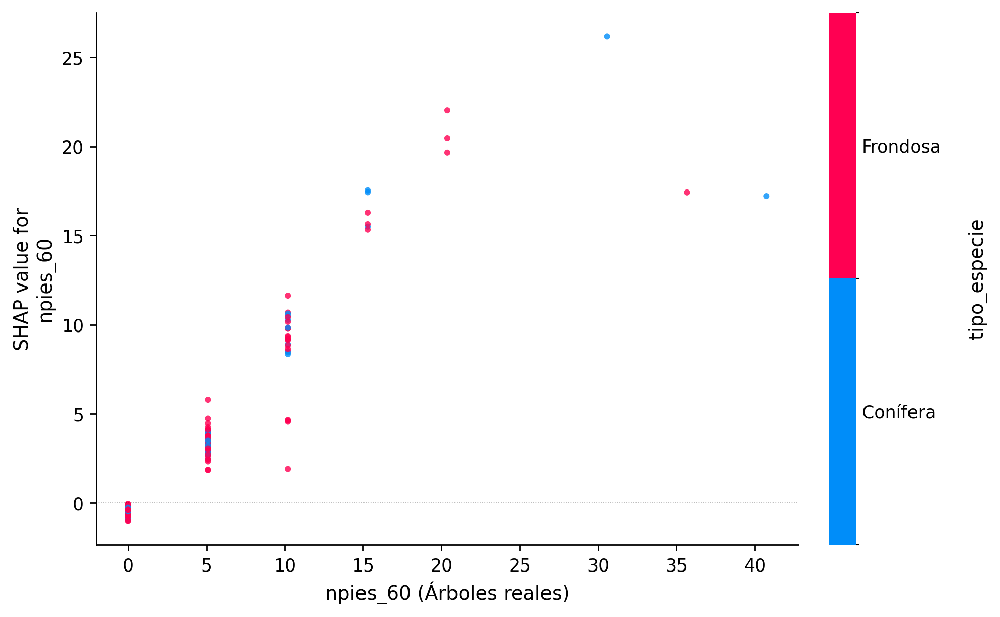

  [OK] npies_65


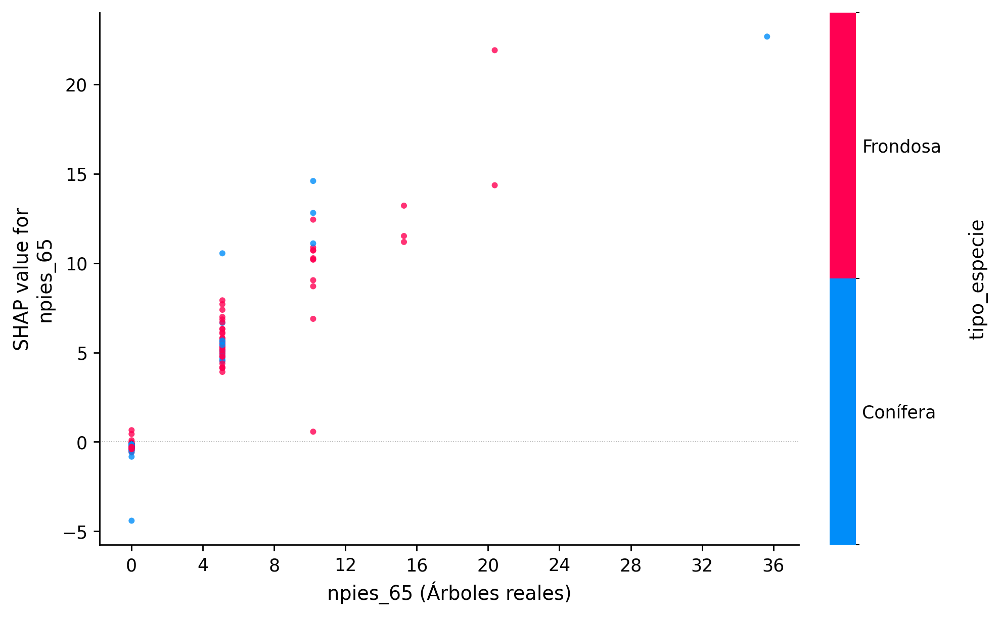

  [OK] npies_70


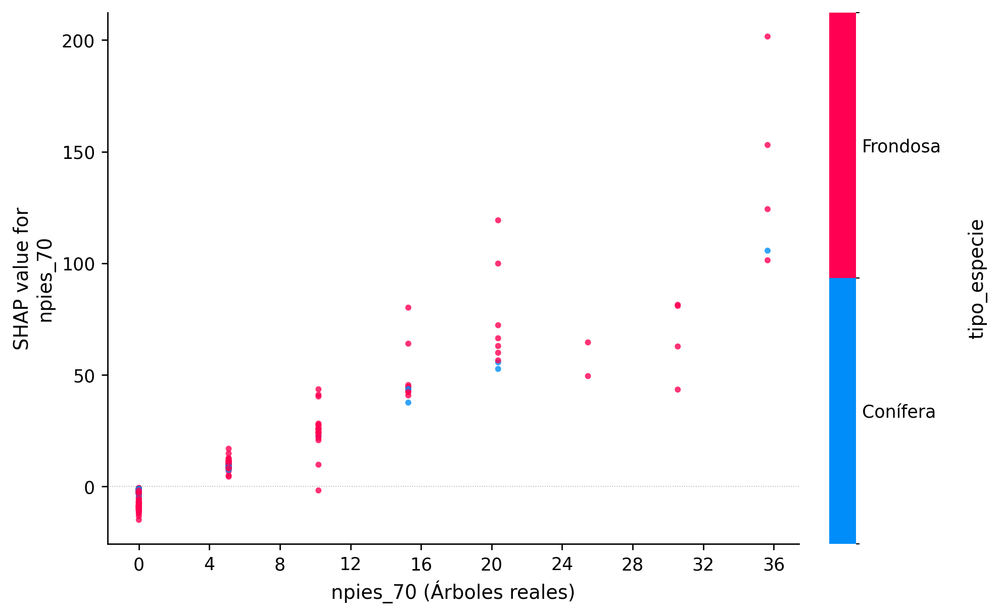

Dependence npies c4 completados.


In [29]:
shap_red  = '#ff0052'  # Frondosa
shap_blue = '#008df9'  # Conífera
shap_cmap = ListedColormap([shap_blue, shap_red])

plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top']   = False

npies_cols = [c for c in FEATURES_C4 if 'npies_' in c]
cat_codes  = X_dep_c4['tipo_especie'].values if 'tipo_especie' in X_dep_c4.columns else None

out_npies_c4 = OUTPUT_SHAP / 'c4' / 'dependence_npies'
out_npies_c4.mkdir(parents=True, exist_ok=True)

for feat in npies_cols:
    save_path = out_npies_c4 / f'dep_npies_{feat}.png'
    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {feat}')
        ipy_display(IPImage(str(save_path)))
        continue
    col = next((f for f in feat_names_c4 if feat in f), None)
    if col is None or cat_codes is None:
        continue
    col_idx   = feat_names_c4.index(col)
    x_vals    = X_dep_c4[feat].values
    y_shap    = shap_vals_c4[:, col_idx]

    fig, ax = plt.subplots(figsize=(8, 5))
    norm = mpl.colors.BoundaryNorm([-0.5, 0.5, 1.5], shap_cmap.N)
    ax.scatter(x_vals, y_shap, c=cat_codes, cmap=shap_cmap,
               s=12, alpha=0.8, edgecolors='none', vmin=0, vmax=1)
    cbar = plt.colorbar(
        mpl.cm.ScalarMappable(norm=norm, cmap=shap_cmap),
        ax=ax, ticks=[0, 1], fraction=0.046, pad=0.04
    )
    cbar.set_ticklabels(['Con\u00edfera', 'Frondosa'])
    cbar.ax.set_ylabel('tipo_especie', rotation=90, labelpad=15, fontsize=11)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(size=0)
    ax.set_xlabel(f'{feat} (\u00c1rboles reales)', fontsize=11)
    ax.set_ylabel(f'SHAP value for\n{feat}', fontsize=11)
    ax.axhline(0, color='black', linestyle=':', linewidth=0.5, alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.tight_layout()
    print(f'  -> {save_path}')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
    plt.show()
    plt.close()

print('Dependence npies c4 completados.')

---
## 4. SHAP Dependence — carbono\_bruto4 (IFN3, CatBoost)

### 4.1 Variables generales
Features: `fccarb`, `elevacion`, `gndvi_mean_verano`, `evi_mean_primavera`, `martonneidx_id`

In [30]:
X_dep_cb4 = X_test_cb4.sample(min(2000, len(X_test_cb4)), random_state=42)

cache_dep_cb4 = CACHE_SHAP / 'dependence' / 'carbono_bruto4' / 'CatBoost_2000.joblib'

if cache_dep_cb4.exists():
    print('Cargando SHAP values CatBoost carbono_bruto4 desde caché...')
    _d = joblib.load(cache_dep_cb4)
    feat_names_cb4 = _d['feat_names']
    shap_vals_cb4  = _d['shap_vals']
    X_df_cb4       = _d['X_df']
    del _d; gc.collect()
else:
    print('Cargando CatBoost carbono_bruto4...')
    pipeline_catboost_cb4 = joblib.load(MODELS_IFN3_CB4 / 'CatBoost.joblib')

    preprocessor_cb4 = pipeline_catboost_cb4.named_steps['preprocessor']
    model_cb4        = pipeline_catboost_cb4.named_steps['regressor']

    feat_names_cb4 = get_feature_names(preprocessor_cb4)
    X_trans_cb4    = preprocessor_cb4.transform(X_dep_cb4)
    if X_trans_cb4.shape[1] != len(feat_names_cb4):
        feat_names_cb4 = [f'f_{i:03d}' for i in range(X_trans_cb4.shape[1])]
    X_df_cb4 = pd.DataFrame(X_trans_cb4, columns=feat_names_cb4)

    print('Calculando SHAP values (TreeExplainer)...')
    explainer_cb4  = shap.TreeExplainer(model_cb4)
    shap_vals_cb4  = explainer_cb4.shap_values(X_df_cb4)
    if isinstance(shap_vals_cb4, list):
        shap_vals_cb4 = shap_vals_cb4[0]

    del pipeline_catboost_cb4, preprocessor_cb4, model_cb4, explainer_cb4
    gc.collect()

    cache_dep_cb4.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({'feat_names': feat_names_cb4, 'shap_vals': shap_vals_cb4, 'X_df': X_df_cb4},
                cache_dep_cb4, compress=3)
    print('Caché guardada.')

print(f'SHAP values: {shap_vals_cb4.shape}')

Cargando SHAP values CatBoost carbono_bruto4 desde caché...
SHAP values: (2000, 210)


  [OK] fccarb


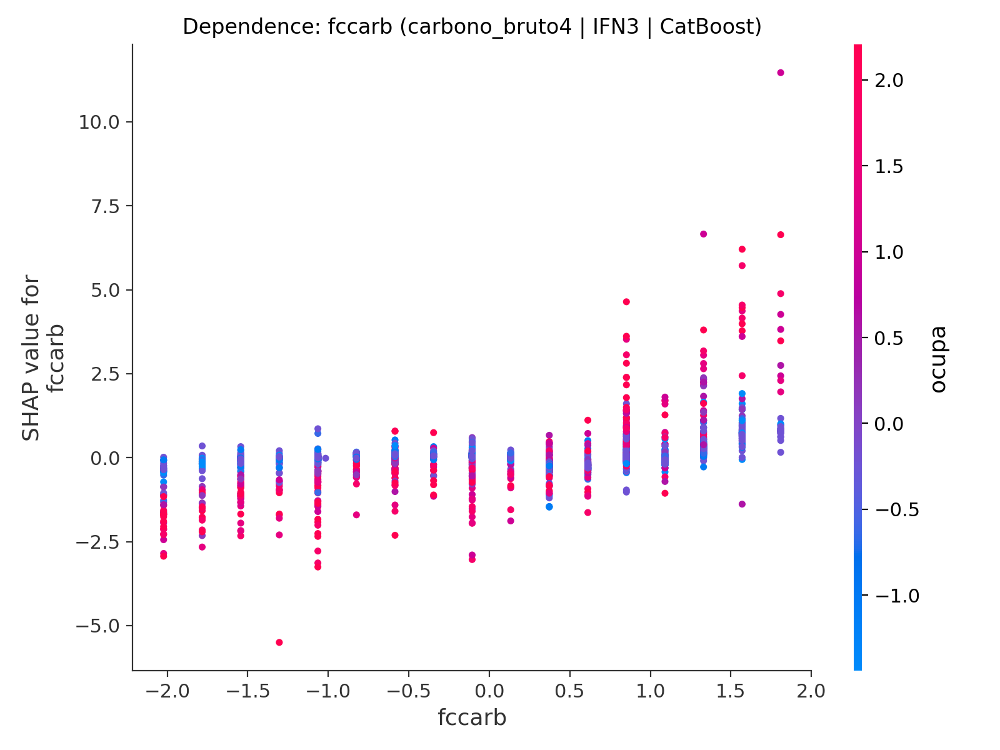

  [OK] elevacion


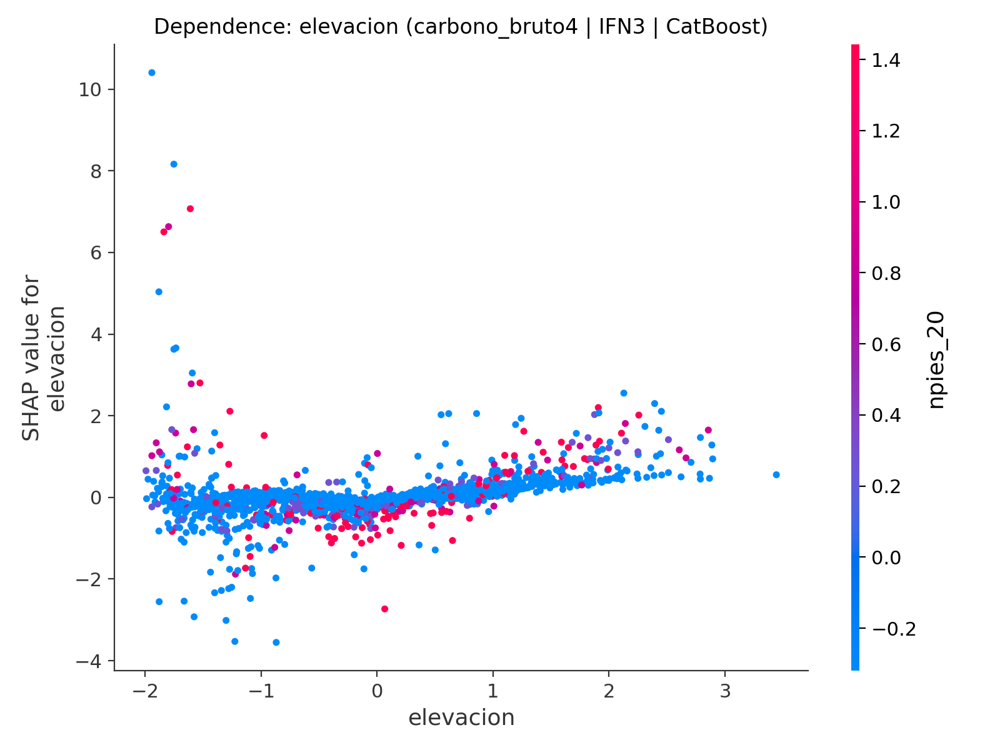

  [OK] gndvi_mean_verano


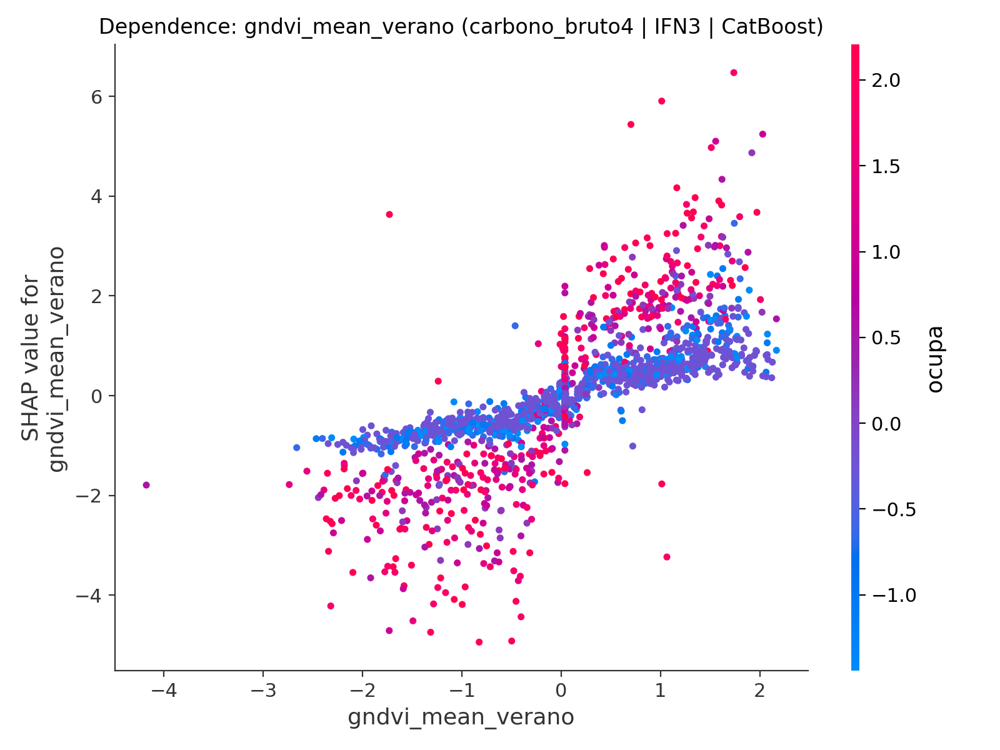

  [OK] evi_mean_primavera


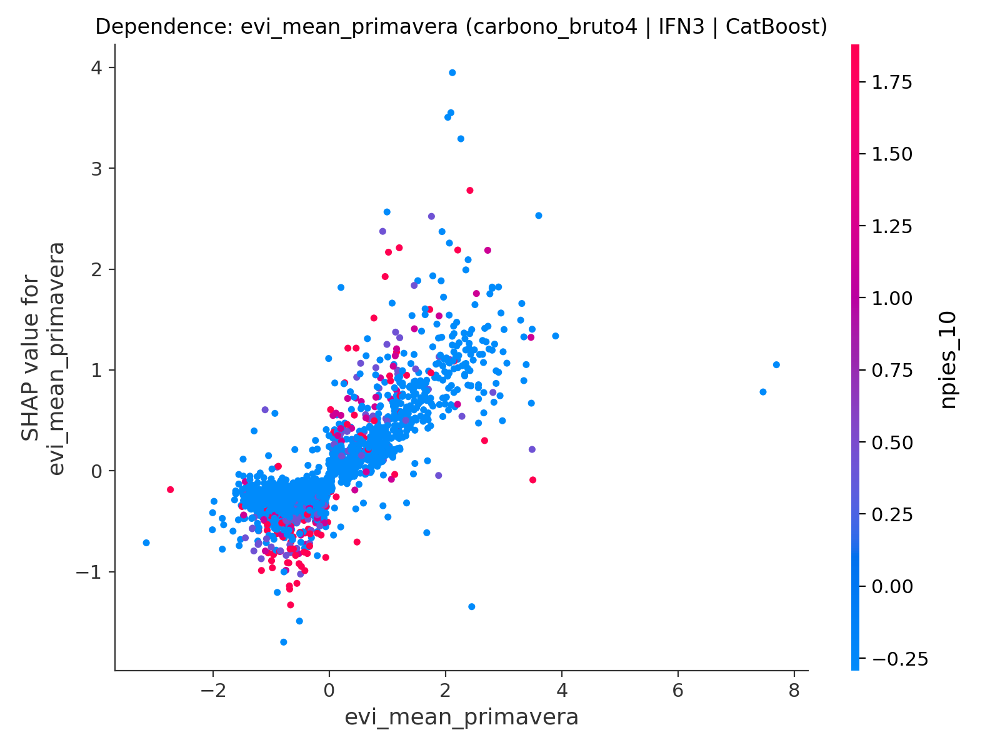

  [OK] martonneidx_id


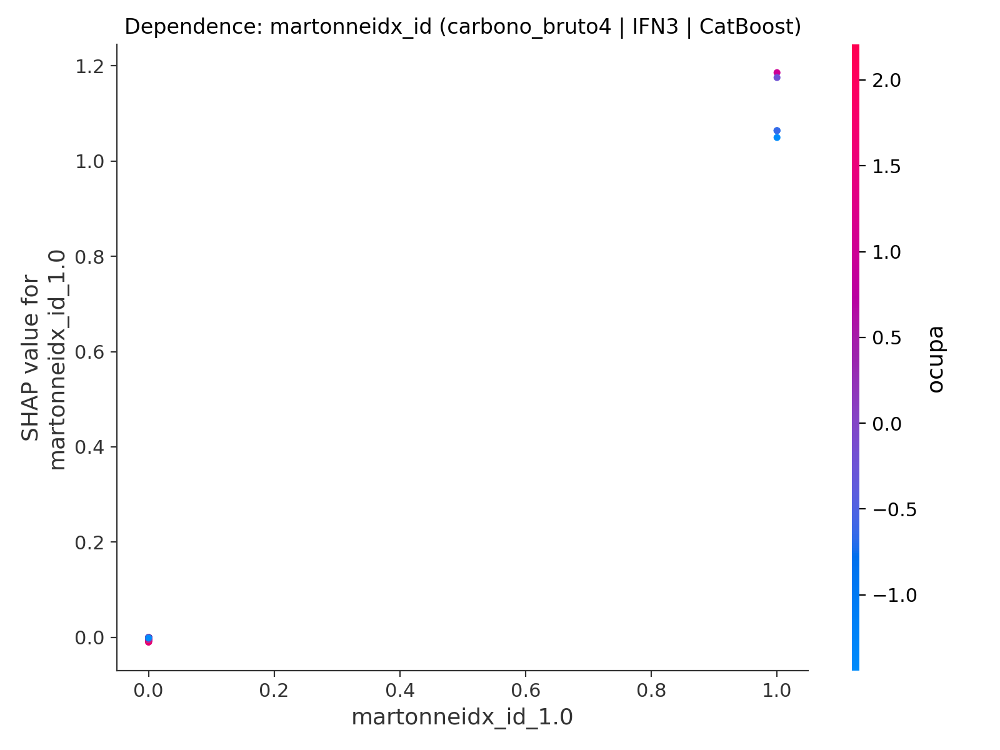

Dependence plots generales carbono_bruto4 completados.


In [31]:
feats_generales_cb4 = [
    'fccarb', 'elevacion', 'gndvi_mean_verano',
    'evi_mean_primavera', 'martonneidx_id'
]

out_dep_cb4 = OUTPUT_SHAP / 'carbono_bruto4' / 'dependence'
out_dep_cb4.mkdir(parents=True, exist_ok=True)

for feat in feats_generales_cb4:
    save_path = out_dep_cb4 / f'dep_{feat}.png'
    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {feat}')
        ipy_display(IPImage(str(save_path)))
        continue
    col = next((f for f in feat_names_cb4 if feat in f), None)
    if col is None:
        print(f'  Feature {feat} no encontrada, omitiendo')
        continue
    fig, ax = plt.subplots(figsize=(8, 6))
    shap.dependence_plot(col, shap_vals_cb4, X_df_cb4, display_features=X_df_cb4, show=False, ax=ax)
    ax.set_title(f'Dependence: {feat} (carbono_bruto4 | IFN3 | CatBoost)', fontsize=12)
    plt.tight_layout()
    print(f'  -> {save_path}')
    plt.savefig(save_path, dpi=300)
    plt.savefig(save_path.with_suffix('.pdf'))
    plt.show()
    plt.close()

print('Dependence plots generales carbono_bruto4 completados.')

### 4.2 Estructura diamétrica vs tipo de especie (carbono\_bruto4)

  [OK] npies_1


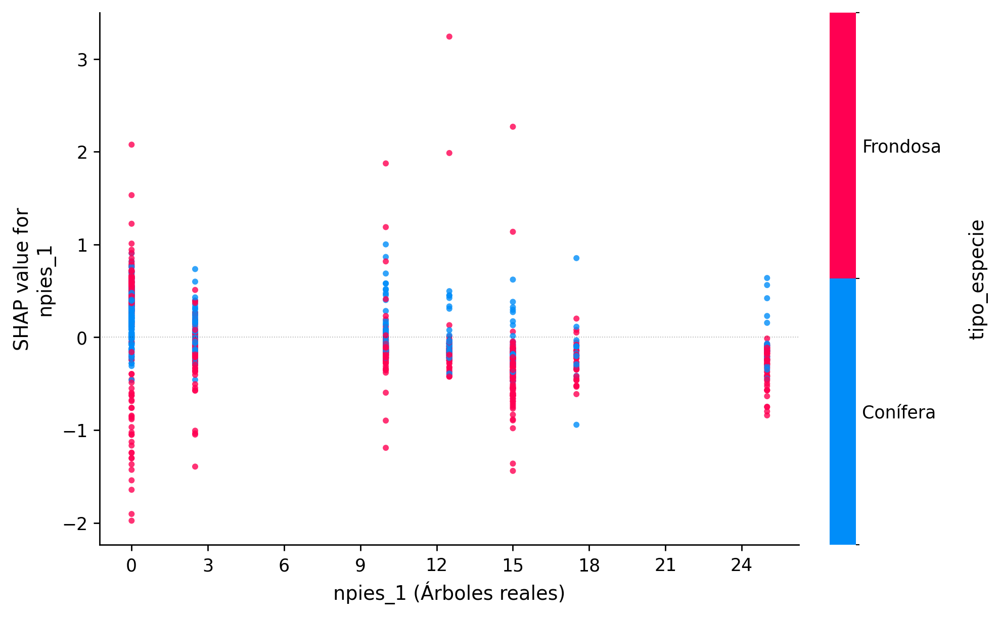

  [OK] npies_2


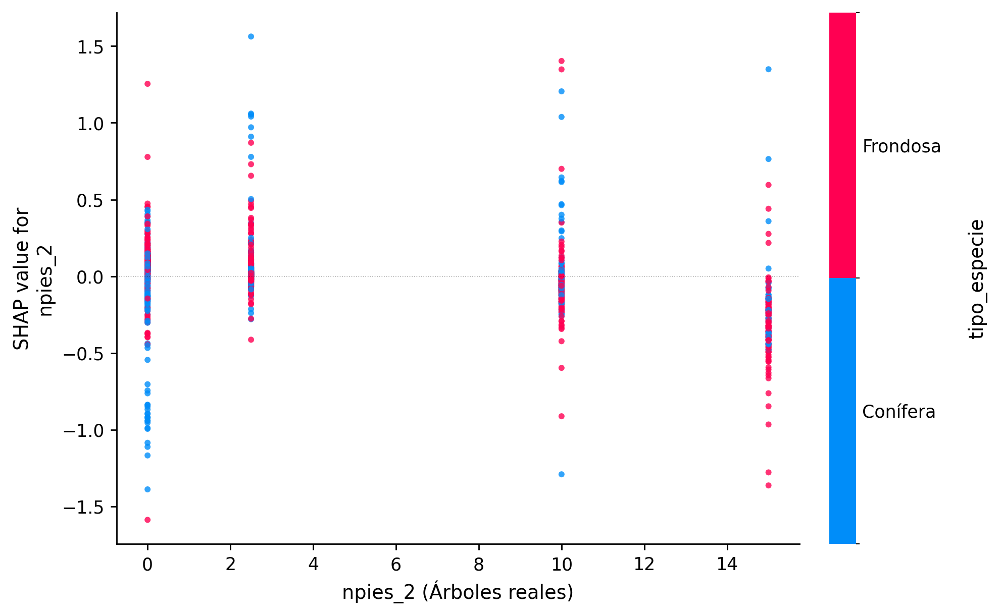

  [OK] npies_5


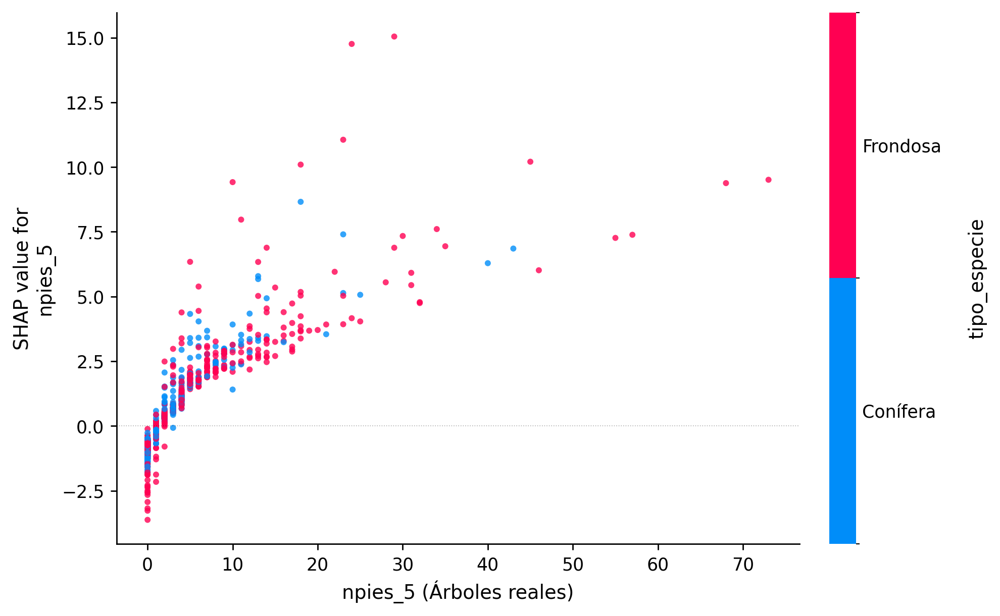

  [OK] npies_10


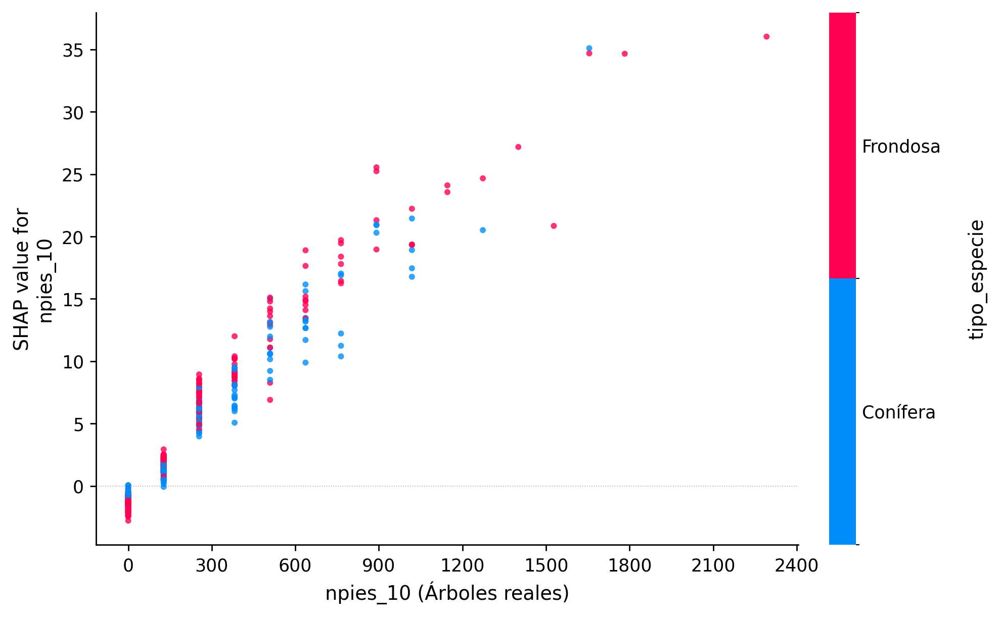

  [OK] npies_15


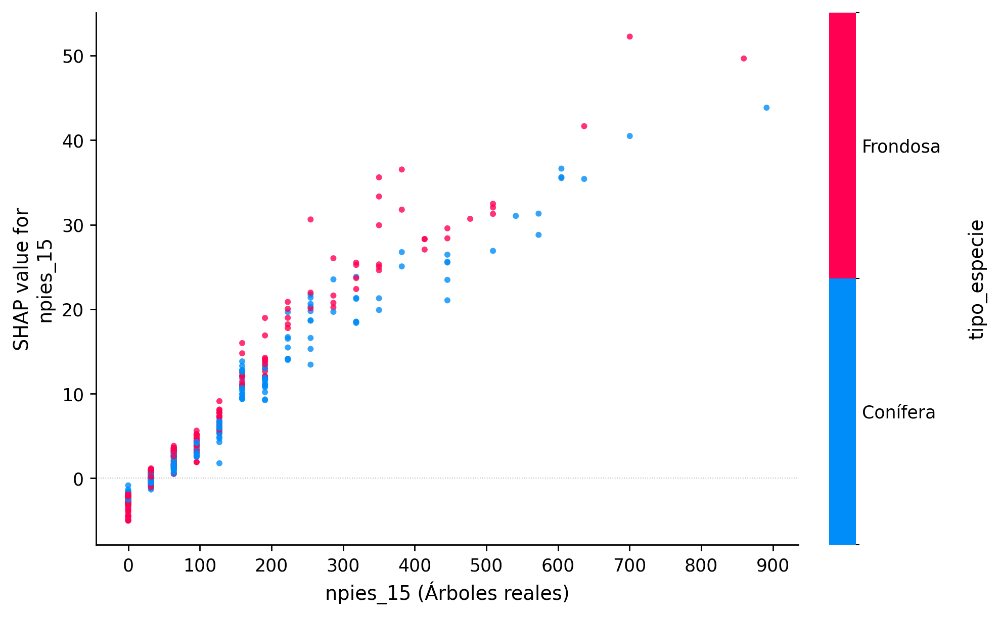

  [OK] npies_20


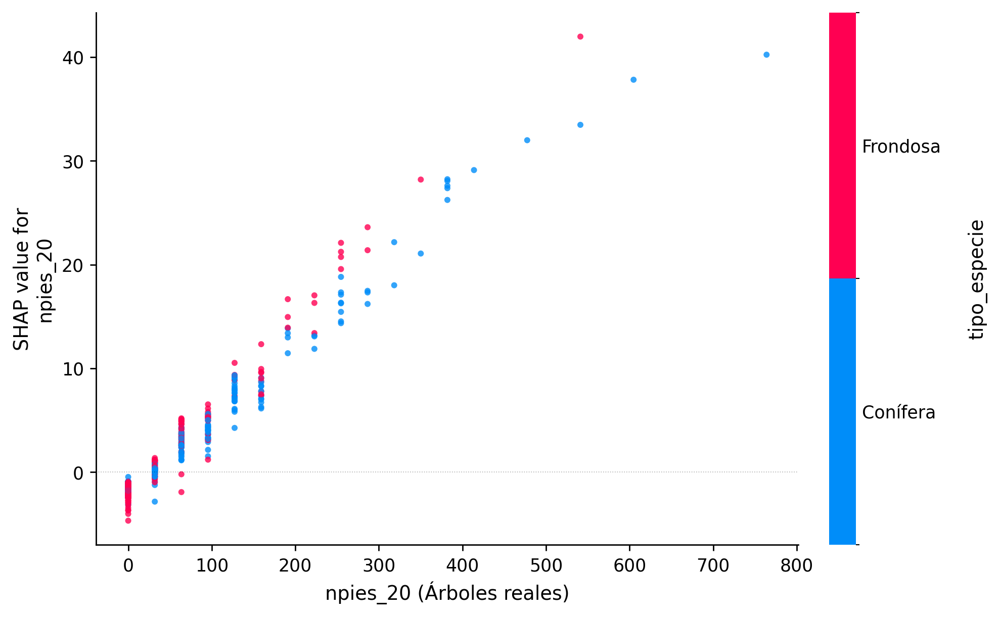

  [OK] npies_25


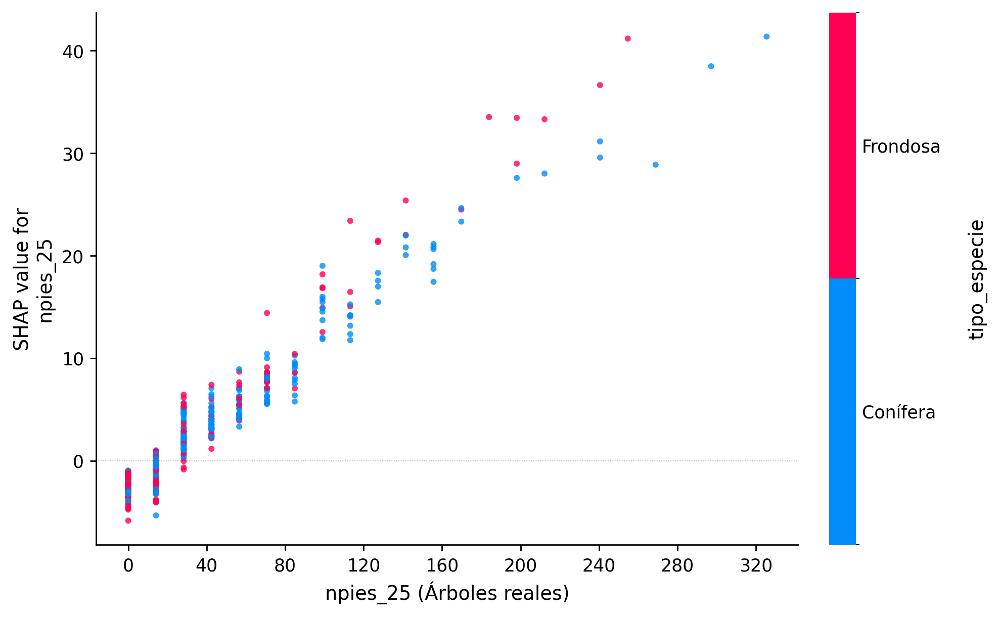

  [OK] npies_30


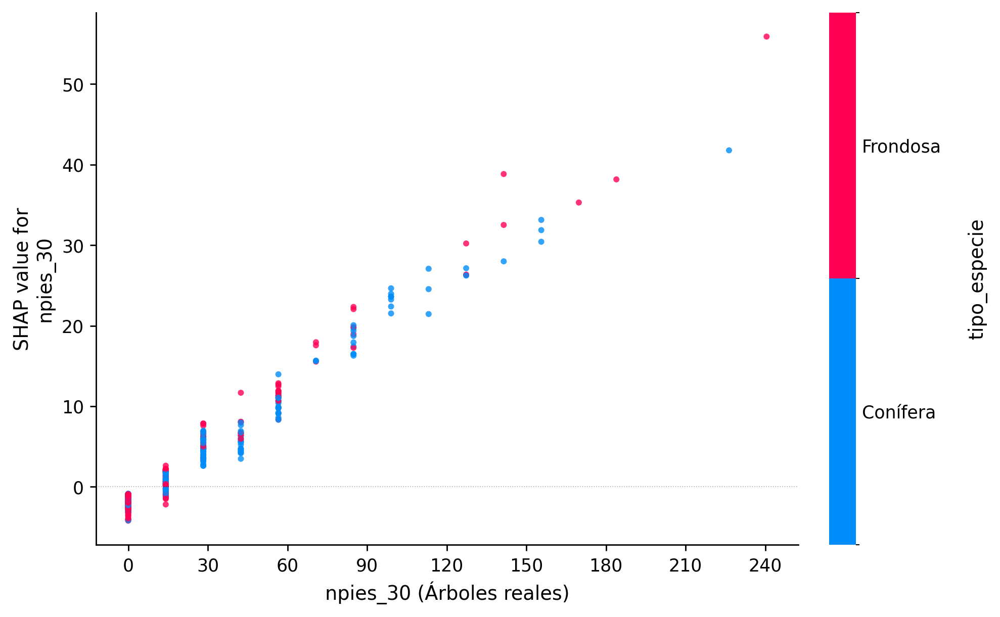

  [OK] npies_35


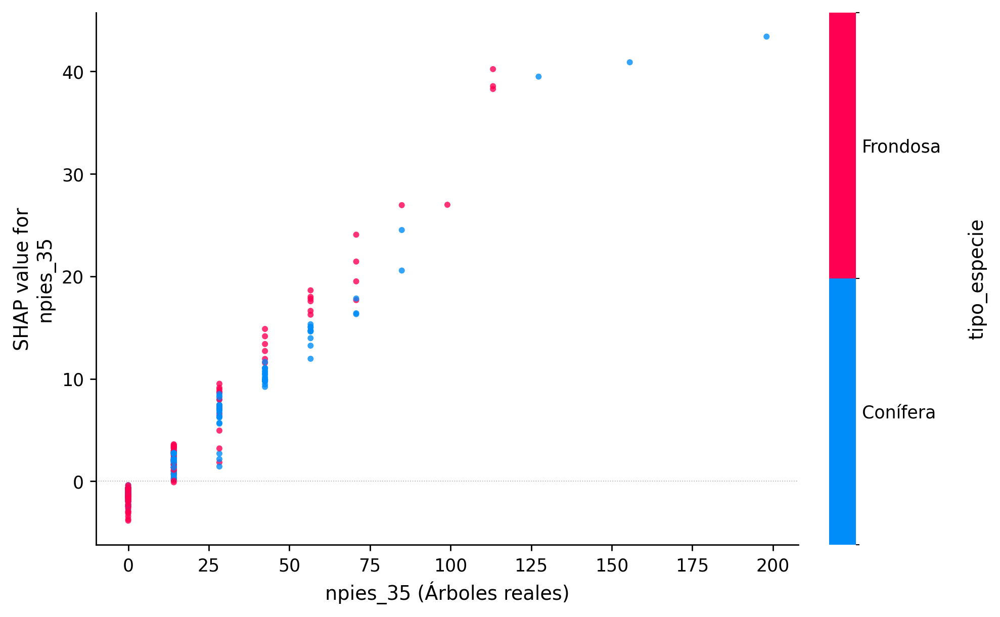

  [OK] npies_40


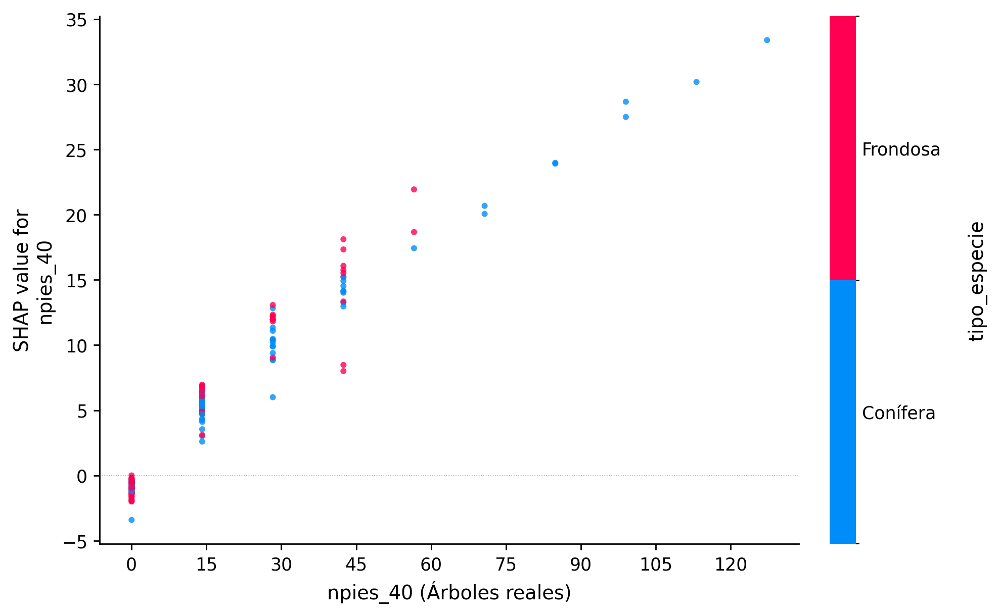

  [OK] npies_45


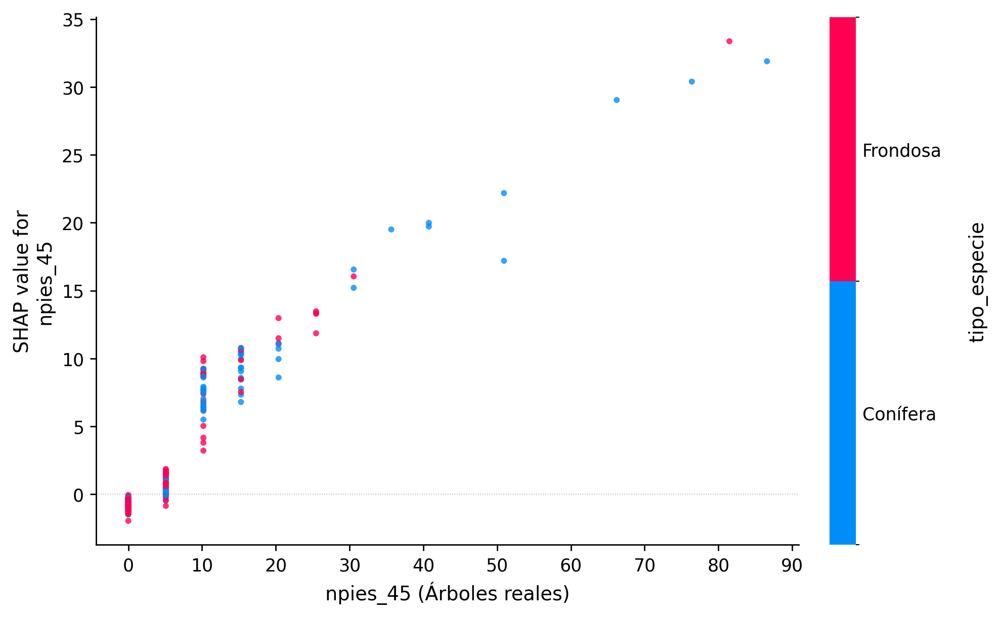

  [OK] npies_50


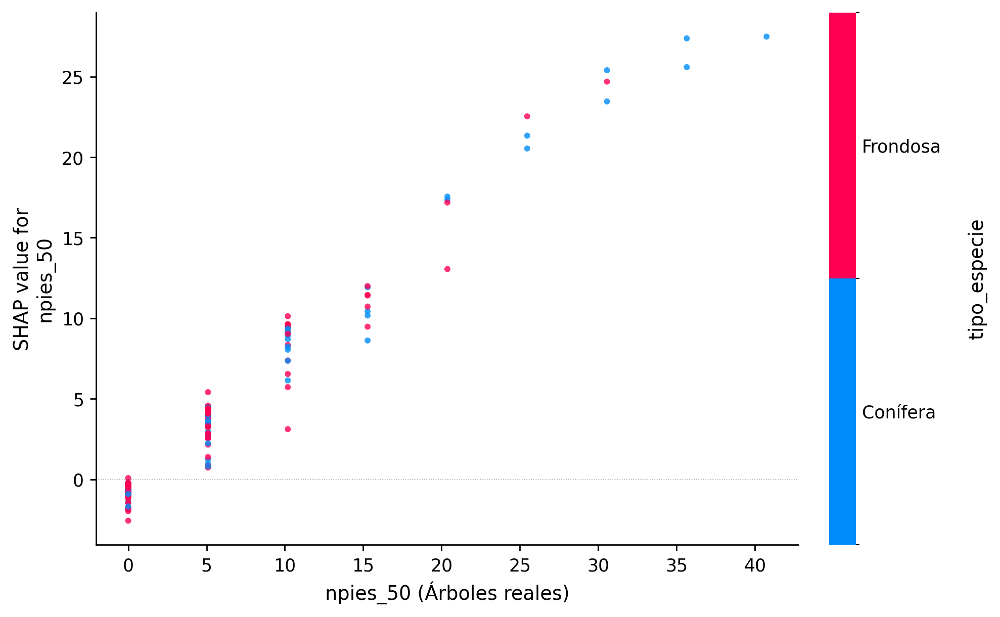

  [OK] npies_55


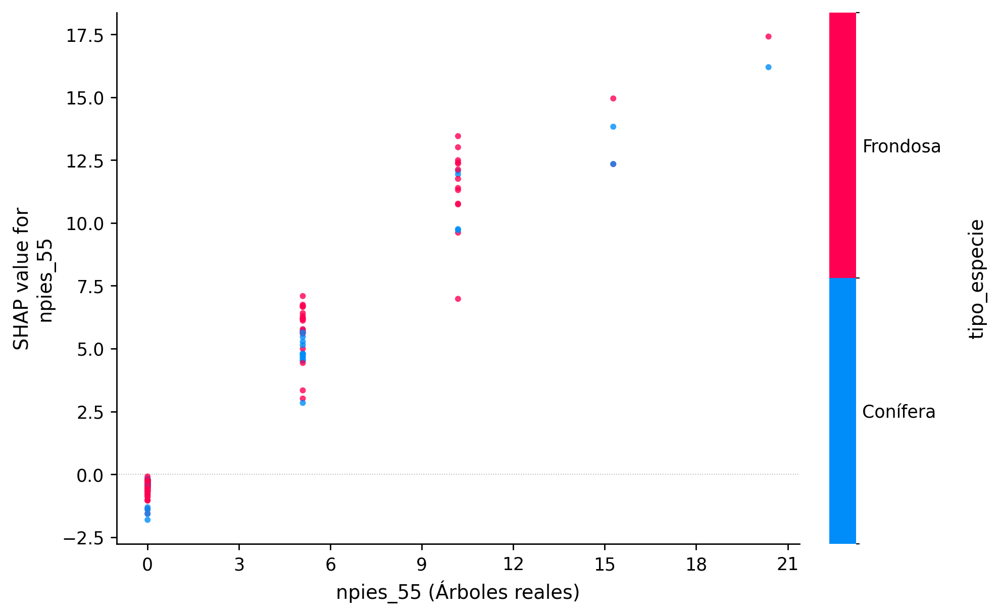

  [OK] npies_60


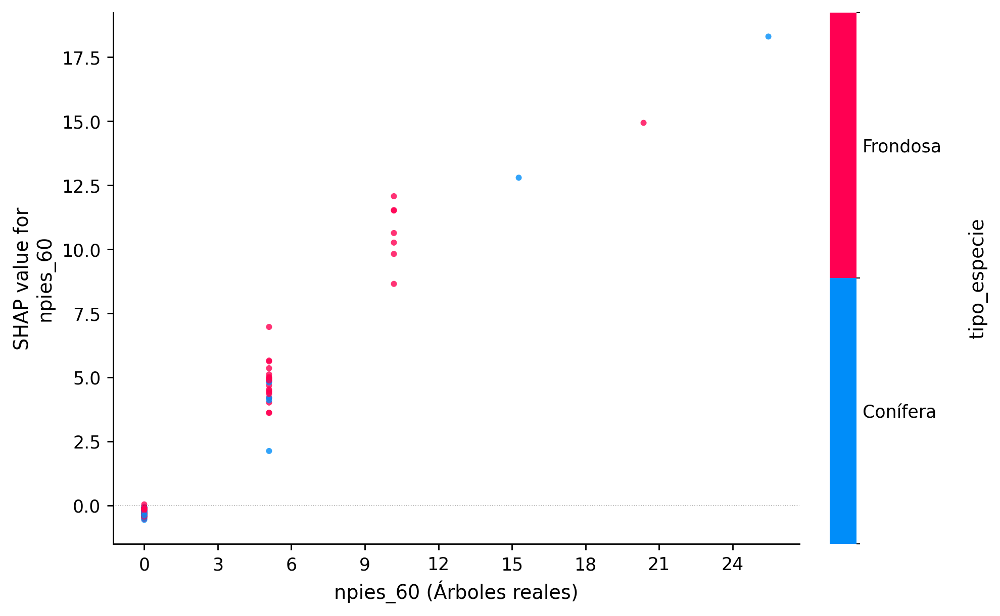

  [OK] npies_65


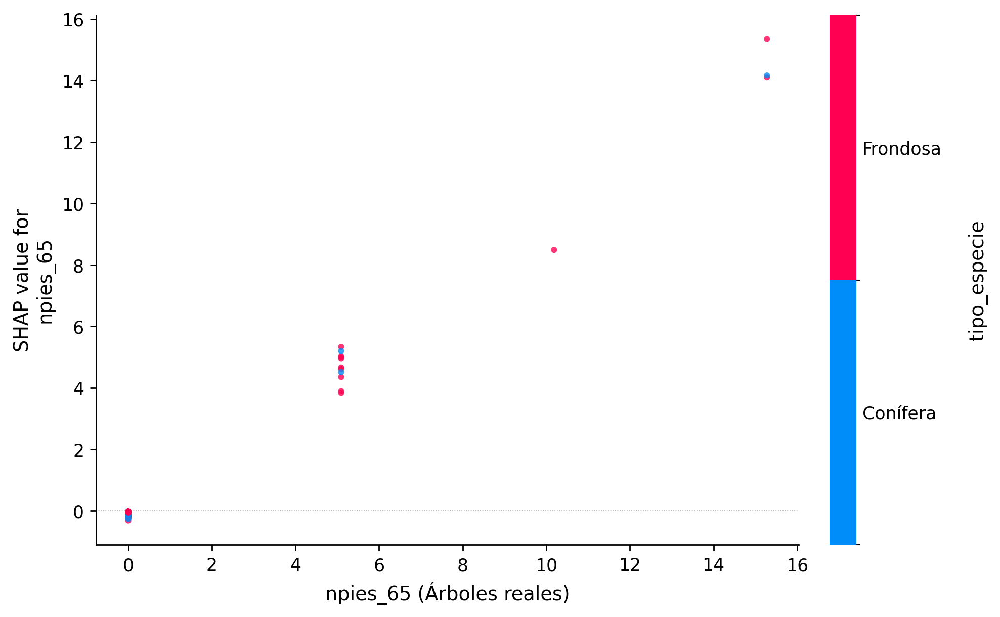

  [OK] npies_70


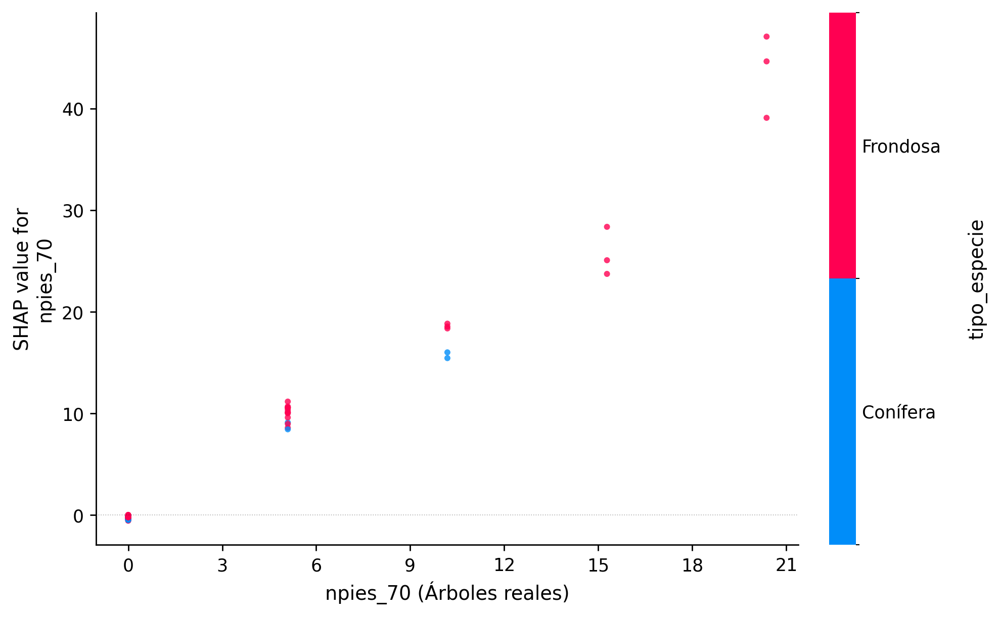

Dependence npies carbono_bruto4 completados.


In [32]:
npies_cols_cb4 = [c for c in FEATURES_CB4 if 'npies_' in c]
cat_codes_cb4  = X_dep_cb4['tipo_especie'].values if 'tipo_especie' in X_dep_cb4.columns else None

out_npies_cb4 = OUTPUT_SHAP / 'carbono_bruto4' / 'dependence_npies'
out_npies_cb4.mkdir(parents=True, exist_ok=True)

for feat in npies_cols_cb4:
    save_path = out_npies_cb4 / f'dep_npies_{feat}.png'
    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {feat}')
        ipy_display(IPImage(str(save_path)))
        continue
    col = next((f for f in feat_names_cb4 if feat in f), None)
    if col is None or cat_codes_cb4 is None:
        continue
    col_idx = feat_names_cb4.index(col)
    x_vals  = X_dep_cb4[feat].values
    y_shap  = shap_vals_cb4[:, col_idx]

    fig, ax = plt.subplots(figsize=(8, 5))
    norm = mpl.colors.BoundaryNorm([-0.5, 0.5, 1.5], shap_cmap.N)
    ax.scatter(x_vals, y_shap, c=cat_codes_cb4, cmap=shap_cmap,
               s=12, alpha=0.8, edgecolors='none', vmin=0, vmax=1)
    cbar = plt.colorbar(
        mpl.cm.ScalarMappable(norm=norm, cmap=shap_cmap),
        ax=ax, ticks=[0, 1], fraction=0.046, pad=0.04
    )
    cbar.set_ticklabels(['Con\u00edfera', 'Frondosa'])
    cbar.ax.set_ylabel('tipo_especie', rotation=90, labelpad=15, fontsize=11)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(size=0)
    ax.set_xlabel(f'{feat} (\u00c1rboles reales)', fontsize=11)
    ax.set_ylabel(f'SHAP value for\n{feat}', fontsize=11)
    ax.axhline(0, color='black', linestyle=':', linewidth=0.5, alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.tight_layout()
    print(f'  -> {save_path}')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
    plt.show()
    plt.close()

print('Dependence npies carbono_bruto4 completados.')

---
## 5. Análisis Estructura Diamétrica (npies) — carbono\_bruto4

Para cada modelo base, beeswarm SHAP limitado a las features `npies_*`.
Después, gráfico consolidado de importancia media absoluta SHAP por clase diamétrica y por modelo.

  AdaBoost... [caché] 

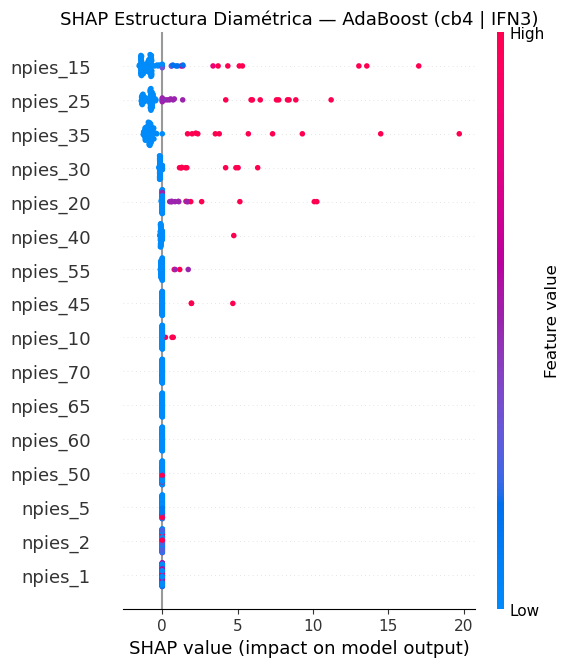

OK
  BaggedDT... [caché] 

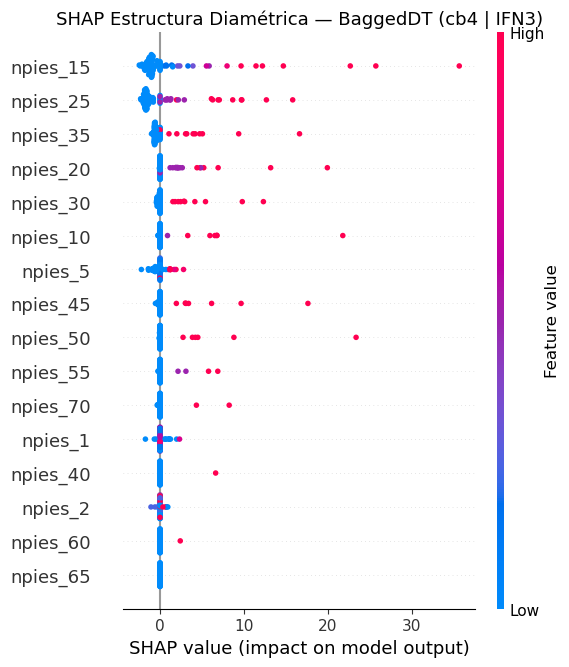

OK
  BayesianNN... [caché] 

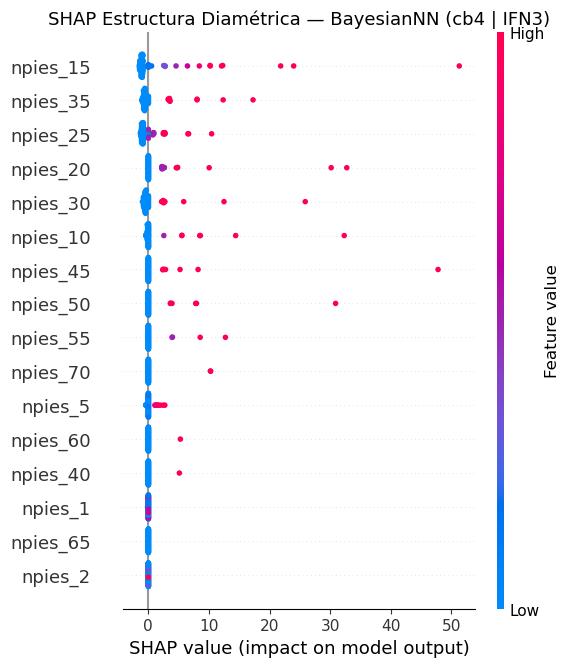

OK
  CatBoost... [caché] 

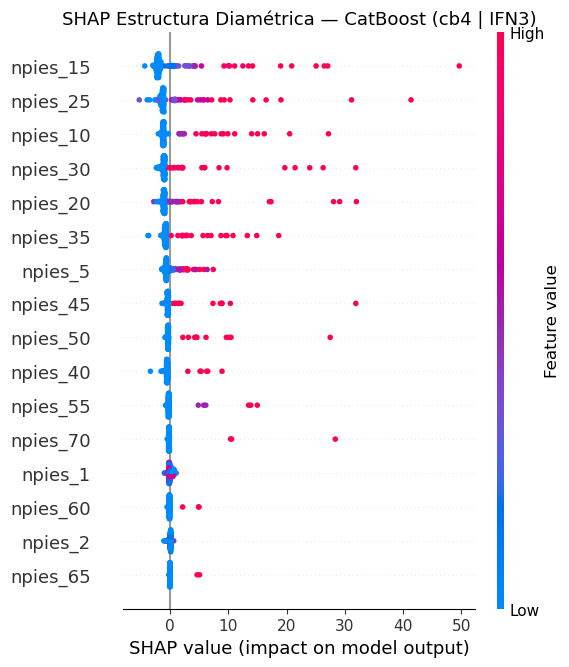

OK
  GBDT... [caché] 

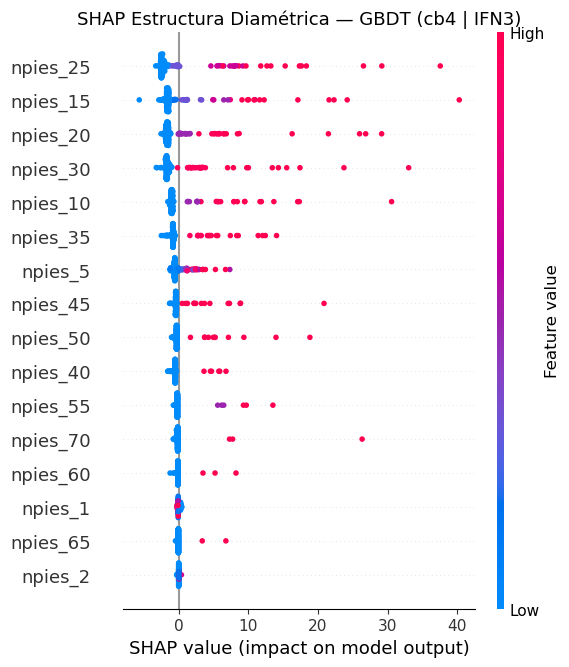

OK
  KNN... [caché] 

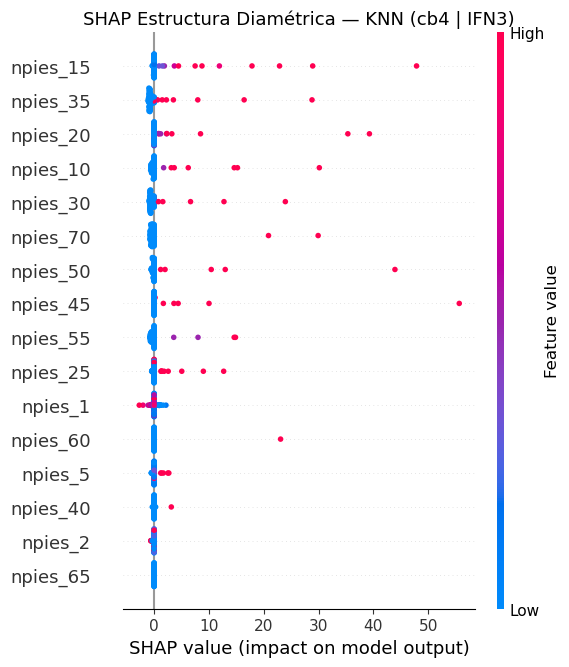

OK
  LightGBM... [caché] 

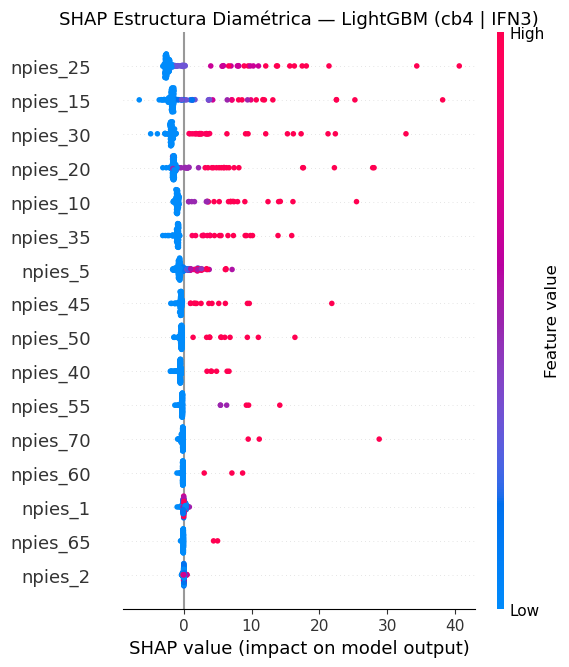

OK
  MLP_PyTorch... [caché] 

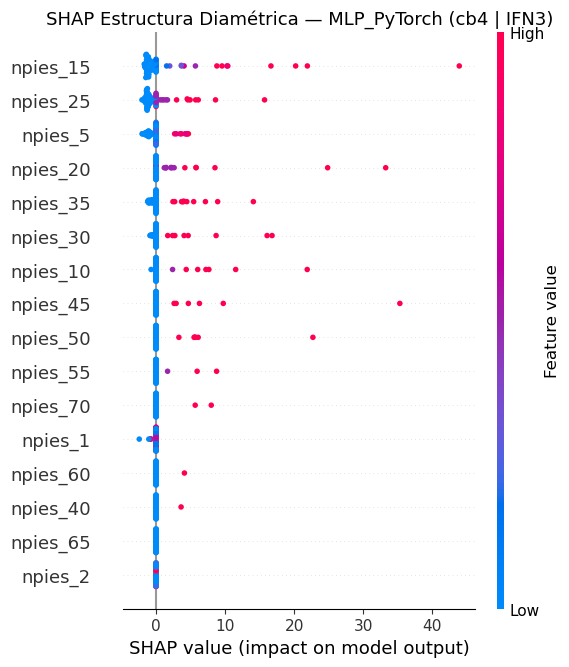

OK
  Random_Forest... [caché] 

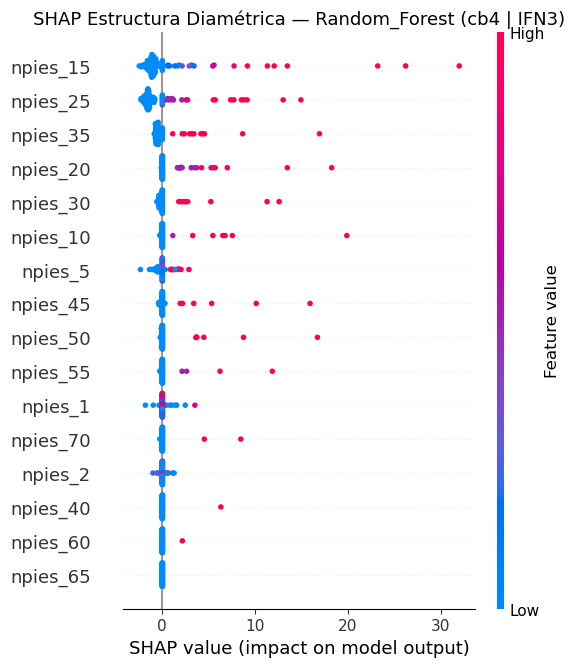

OK
  SVR... [caché] 

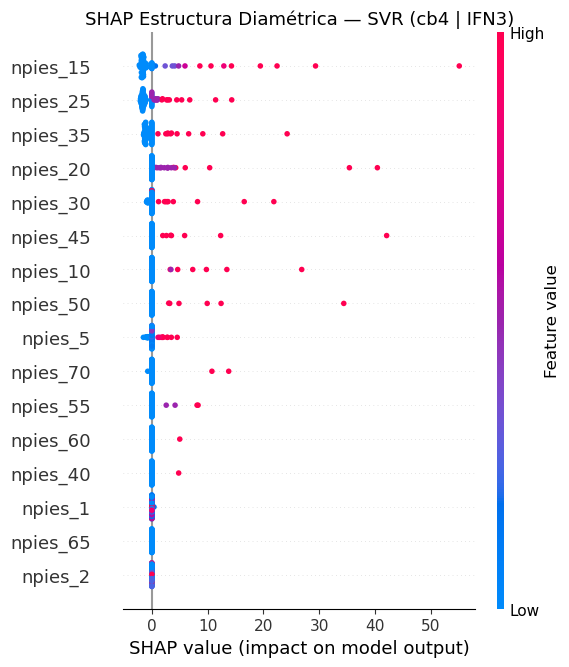

OK
  XGBoost... [caché] 

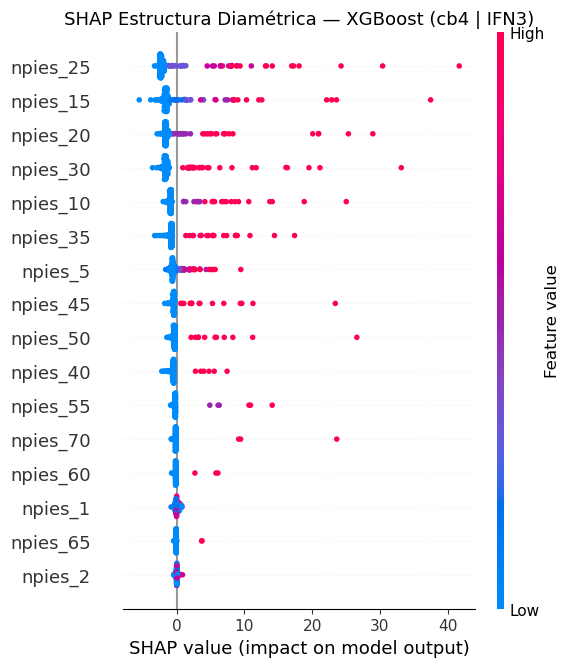

OK

Estadísticas recopiladas: 176 entradas


In [33]:
out_npies_all = OUTPUT_SHAP / 'carbono_bruto4' / 'npies_analysis'
out_npies_all.mkdir(parents=True, exist_ok=True)

stats_all = []  # lista de dicts {Model, Clase_Diametrica, Mean_Abs_SHAP, Mean_Raw_SHAP, Median_Raw_SHAP}

for fname in model_files_cb4:
    model_name = fname.replace('.joblib', '')
    model_path = MODELS_IFN3_CB4 / fname
    cache_path = CACHE_SHAP / 'base' / 'carbono_bruto4' / f'{model_name}.joblib'

    print(f'  {model_name}...', end=' ')

    try:
        # Reutiliza la caché de la sección 2 si existe (evita recargar el modelo)
        sv, fn, Xt_df, Xr_used, base_val = load_or_compute_shap(
            model_path, X_sample_cb4, X_bg_cb4, model_name, cache_path=cache_path
        )

        npies_idx = [i for i, f in enumerate(fn) if f.startswith('npies')]
        if not npies_idx:
            print('sin npies features, omitiendo')
            continue

        sv_npies = sv[:, npies_idx]
        fn_npies = [fn[i] for i in npies_idx]

        # Beeswarm solo npies
        expl = shap.Explanation(
            values=sv_npies,
            base_values=base_val,
            data=Xt_df.iloc[:, npies_idx].values,
            feature_names=fn_npies
        )
        fig, ax = plt.subplots(figsize=(10, 8))
        shap.plots.beeswarm(expl, max_display=30, show=False)
        plt.title(f'SHAP Estructura Diamétrica — {model_name} (cb4 | IFN3)', fontsize=13)
        plt.subplots_adjust(left=0.35, bottom=0.15)
        plt.savefig(out_npies_all / f'beeswarm_npies_{model_name}.png', dpi=300, bbox_inches='tight')
        plt.savefig((out_npies_all / f'beeswarm_npies_{model_name}.png').with_suffix('.pdf'), bbox_inches='tight')
        plt.show()
        plt.close()

        # Estadísticas
        for i, fname_npies in enumerate(fn_npies):
            m = re.search(r'npies_(\d+)', fname_npies)
            if m:
                cd = int(m.group(1))
                col_sv = sv_npies[:, i]
                stats_all.append({
                    'Model': model_name,
                    'Clase_Diametrica': cd,
                    'Mean_Abs_SHAP': float(np.mean(np.abs(col_sv))),
                    'Mean_Raw_SHAP': float(np.mean(col_sv)),
                    'Median_Raw_SHAP': float(np.median(col_sv))
                })
        print('OK')
    except Exception as e:
        print(f'ERROR: {e}')
    finally:
        gc.collect()

print(f'\nEstadísticas recopiladas: {len(stats_all)} entradas')

CSV guardado: ../../figures/shap/carbono_bruto4/npies_analysis/shap_npies_consolidado.csv
  -> ../../figures/shap/carbono_bruto4/npies_analysis/consolidado_npies_importancia.png


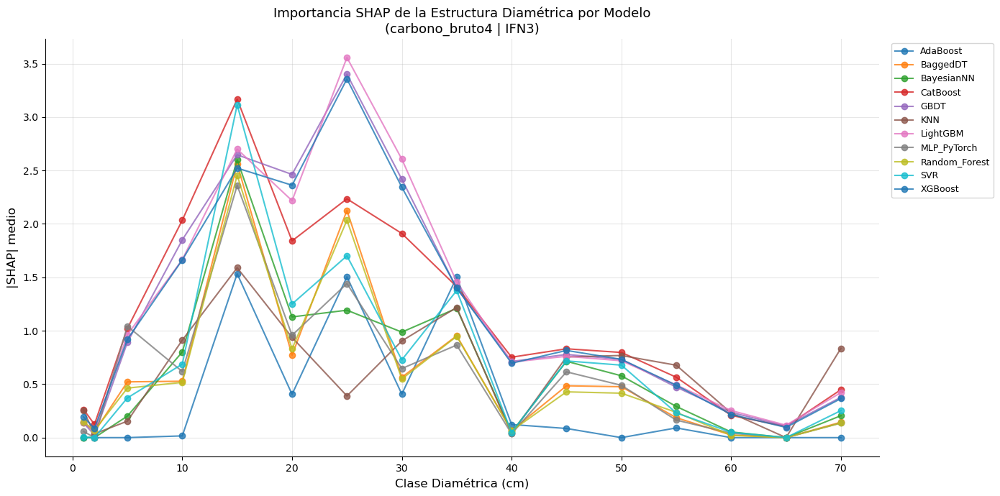

  -> ../../figures/shap/carbono_bruto4/npies_analysis/consolidado_npies_direccion.png


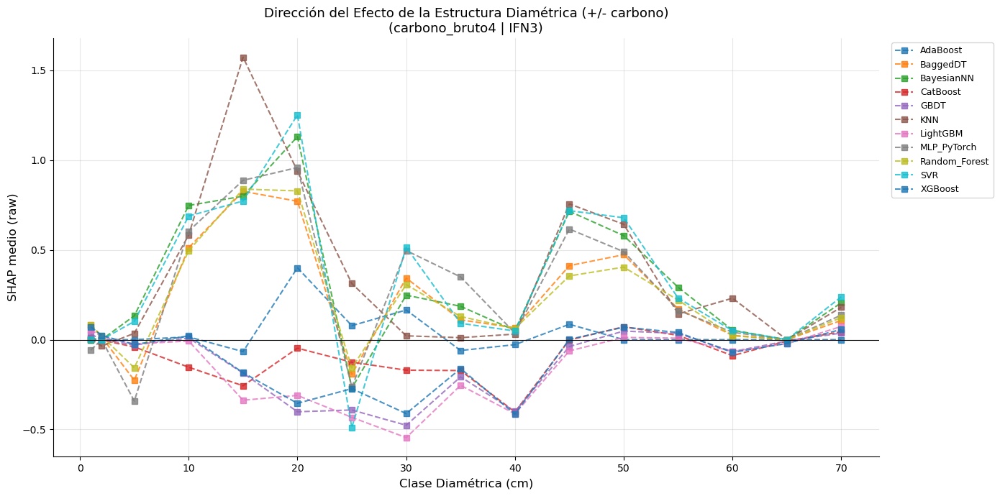

Model,AdaBoost,BaggedDT,BayesianNN,CatBoost,GBDT,KNN,LightGBM,MLP_PyTorch,Random_Forest,SVR,XGBoost
Clase_Diametrica,,,,,,,,,,,
1,0.0000,0.1406,0.0013,0.2640,0.1372,0.2515,0.1458,0.0586,0.1469,0.0039,0.1948
2,0.0000,0.0544,0.0000,0.1242,0.0253,0.0355,0.0646,0.0000,0.0675,0.0000,0.0860
5,0.0000,0.5218,0.2013,1.0214,0.8917,0.1541,0.9630,1.0430,0.4635,0.3719,0.9203
10,0.0162,0.5277,0.8016,2.0346,1.8508,0.9125,1.6655,0.6184,0.5169,0.6879,1.6630
15,1.5337,2.5622,2.6000,3.1672,2.6469,1.5897,2.6998,2.3607,2.4552,3.1139,2.5226
20,0.4056,0.7718,1.1297,1.8412,2.4632,0.9377,2.2176,0.9578,0.8303,1.2504,2.3620
25,1.5045,2.1261,1.1925,2.2348,3.4007,0.3900,3.5569,1.4416,2.0344,1.7012,3.3566
30,0.4069,0.5652,0.9874,1.9105,2.4182,0.9049,2.6060,0.6465,0.5486,0.7278,2.3433
35,1.5025,0.9533,1.2103,1.4128,1.3972,1.2183,1.4562,0.8662,0.9477,1.3766,1.4014



Análisis SHAP completado.


In [34]:
if stats_all:
    df_stats = pd.DataFrame(stats_all).sort_values(['Model', 'Clase_Diametrica'])

    # Guardar CSV
    csv_path = out_npies_all / 'shap_npies_consolidado.csv'
    df_stats.to_csv(csv_path, index=False)
    print(f'CSV guardado: {csv_path}')

    # Plot 1: Importancia absoluta media
    fig, ax = plt.subplots(figsize=(14, 7))
    for model in sorted(df_stats['Model'].unique()):
        sub = df_stats[df_stats['Model'] == model]
        ax.plot(sub['Clase_Diametrica'], sub['Mean_Abs_SHAP'],
                marker='o', label=model, alpha=0.8, linewidth=1.5)
    ax.set_xlabel('Clase Diamétrica (cm)', fontsize=12)
    ax.set_ylabel('|SHAP| medio', fontsize=12)
    ax.set_title('Importancia SHAP de la Estructura Diamétrica por Modelo\n(carbono_bruto4 | IFN3)', fontsize=13)
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    print(f'  -> {out_npies_all / "consolidado_npies_importancia.png"}')
    plt.savefig(out_npies_all / 'consolidado_npies_importancia.png', dpi=300)
    plt.savefig(out_npies_all / 'consolidado_npies_importancia.pdf')
    plt.show()
    plt.close()

    # Plot 2: Dirección media del efecto
    fig, ax = plt.subplots(figsize=(14, 7))
    for model in sorted(df_stats['Model'].unique()):
        sub = df_stats[df_stats['Model'] == model]
        ax.plot(sub['Clase_Diametrica'], sub['Mean_Raw_SHAP'],
                marker='s', label=model, linestyle='--', alpha=0.8, linewidth=1.5)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Clase Diamétrica (cm)', fontsize=12)
    ax.set_ylabel('SHAP medio (raw)', fontsize=12)
    ax.set_title('Dirección del Efecto de la Estructura Diamétrica (+/- carbono)\n(carbono_bruto4 | IFN3)', fontsize=13)
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    print(f'  -> {out_npies_all / "consolidado_npies_direccion.png"}')
    plt.savefig(out_npies_all / 'consolidado_npies_direccion.png', dpi=300)
    plt.savefig(out_npies_all / 'consolidado_npies_direccion.pdf')
    plt.show()
    plt.close()

    display(df_stats.pivot_table(
        index='Clase_Diametrica', columns='Model',
        values='Mean_Abs_SHAP', aggfunc='mean'
    ).round(4))
else:
    print('No hay datos de npies para graficar.')

print('\nAnálisis SHAP completado.')

---
## 6. SHAP Beeswarm — Modelos Stacking (c4, IFN3)

Para cada configuración de stacking (Stack1–Stack5) y cada meta-learner (6),
el SHAP muestra **cuánto contribuye la predicción de cada modelo base** al resultado final del stack.

**Estructura:**
- Input del meta-learner = vector de predicciones de los modelos base
- Explainer: TreeExplainer (GBT, RF), LinearExplainer (LR, Ridge), KernelExplainer (SVR, MLP)
- **Memoria:** las bases se cargan una por una (predict + del). La matriz de meta-features se reutiliza para los 6 meta-learners del mismo stack y se libera al cambiar de config.

In [35]:
# =============================================================================
# Funciones auxiliares para SHAP de modelos stacking
# =============================================================================

def make_meta_features(base_names, base_models_dir, X_raw, features):
    """
    Carga cada modelo base uno por uno, genera predicciones sobre X_raw,
    libera el modelo inmediatamente. Retorna DataFrame (n_samples × n_bases).
    """
    present = [c for c in features if c in X_raw.columns]
    preds = {}
    for name in base_names:
        path = base_models_dir / f'{name}.joblib'
        print(f'    [{name}]...', end=' ')
        pipe = None
        try:
            pipe = joblib.load(path)
            preds[name] = pipe.predict(X_raw[present])
            print('OK')
        except Exception as e:
            print(f'ERROR: {e}')
            preds[name] = np.zeros(len(X_raw))
        finally:
            if pipe is not None:
                del pipe
            gc.collect()
    return pd.DataFrame(preds)


def compute_meta_shap(meta_pipe, X_meta):
    """
    Calcula SHAP values para el meta-modelo de un stack.
    El meta-pipeline es Pipeline([('scaler', StandardScaler()), ('meta', estimator)]).
    - GradientBoosting / RandomForest → TreeExplainer (sobre features escaladas)
    - LinearRegression / Ridge / RidgeCV → LinearExplainer (sobre features escaladas)
    - SVR / MLP / otros → KernelExplainer (sobre features escaladas, bg=kmeans(5))
    Retorna: shap_vals (array), X_scaled (DataFrame), base_val (float)
    """
    scaler = meta_pipe.named_steps['scaler']
    meta   = meta_pipe.named_steps['meta']
    X_scaled = pd.DataFrame(scaler.transform(X_meta), columns=X_meta.columns)

    meta_type = type(meta).__name__

    if any(t in meta_type for t in ['GradientBoosting', 'RandomForest']):
        explainer = shap.TreeExplainer(meta)
        shap_vals = explainer.shap_values(X_scaled)

    elif any(t in meta_type for t in ['LinearRegression', 'Ridge', 'BayesianRidge']):
        explainer = shap.LinearExplainer(meta, X_scaled)
        shap_vals = explainer.shap_values(X_scaled)

    else:  # SVR, MLP, etc. — pocos features, KernelExplainer es rápido
        bg = shap.kmeans(X_scaled, min(5, len(X_scaled)))
        explainer = shap.KernelExplainer(meta.predict, bg)
        shap_vals = explainer.shap_values(X_scaled)

    if isinstance(shap_vals, list):
        shap_vals = shap_vals[0]
    base_val = explainer.expected_value
    if isinstance(base_val, (list, np.ndarray)):
        base_val = float(base_val[0])

    return shap_vals, X_scaled, base_val


print('Funciones stacking SHAP OK')

Funciones stacking SHAP OK



Stack1 (c4) — bases: ['LightGBM', 'Random_Forest']
  Todos los plots existen — mostrando desde disco
  [OK] Stack1_GradientBoosting


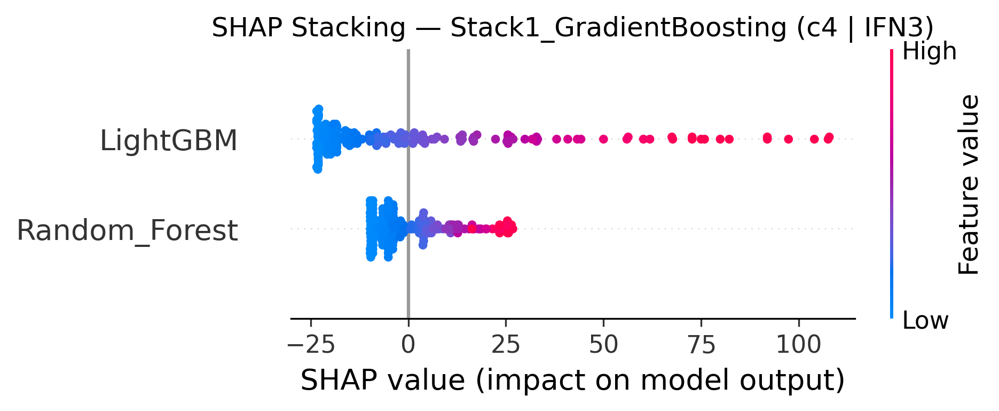

  [OK] Stack1_LinearRegression


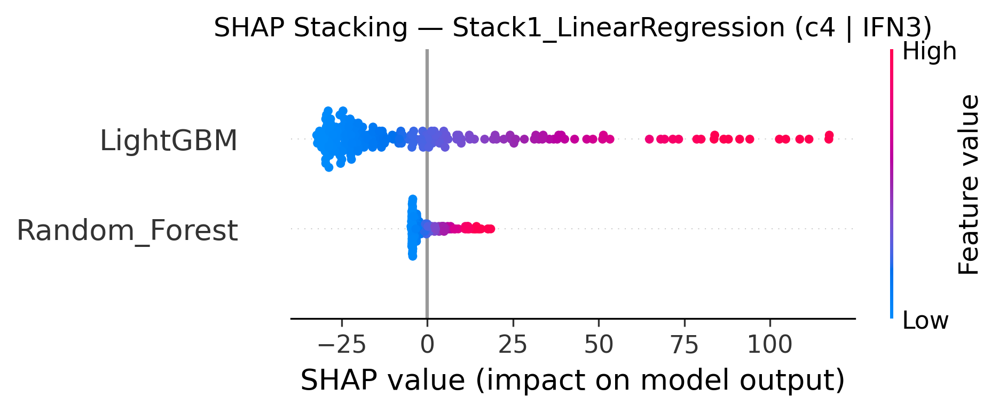

  [OK] Stack1_MLP


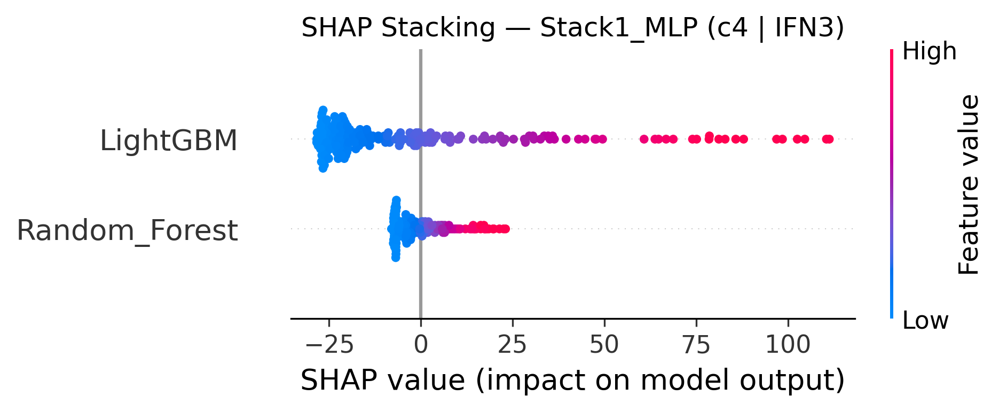

  [OK] Stack1_RandomForest


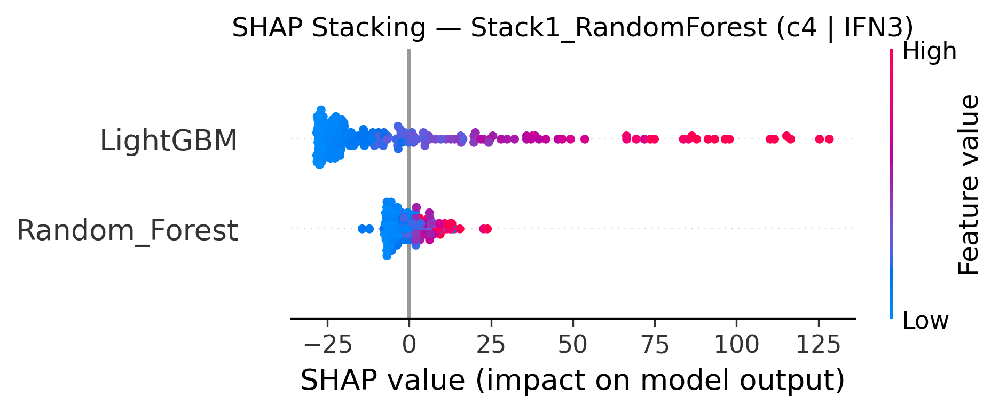

  [OK] Stack1_Ridge


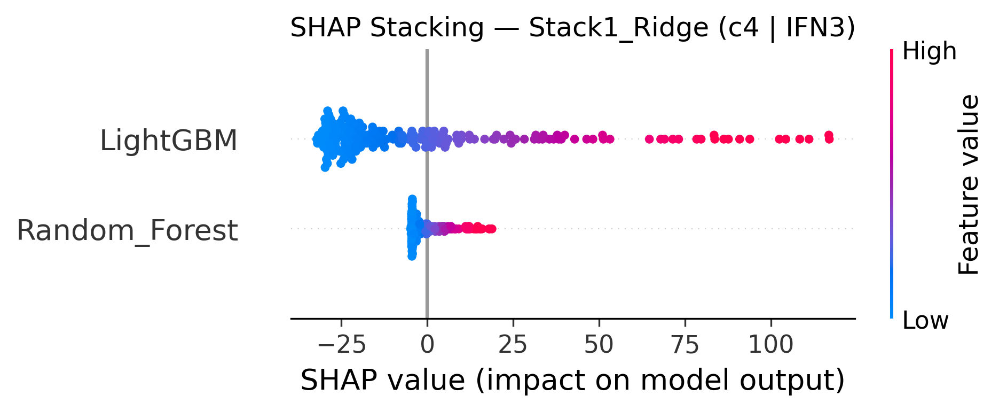

  [OK] Stack1_SVR


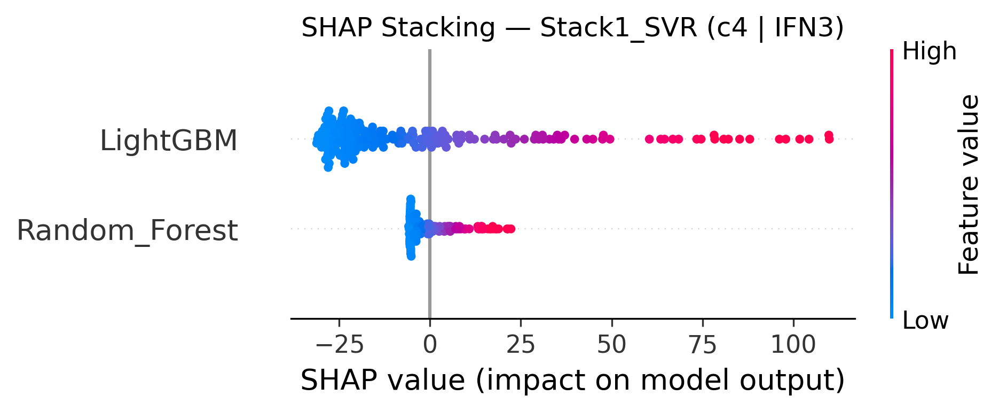


Stack2 (c4) — bases: ['LightGBM', 'XGBoost', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack2_GradientBoosting


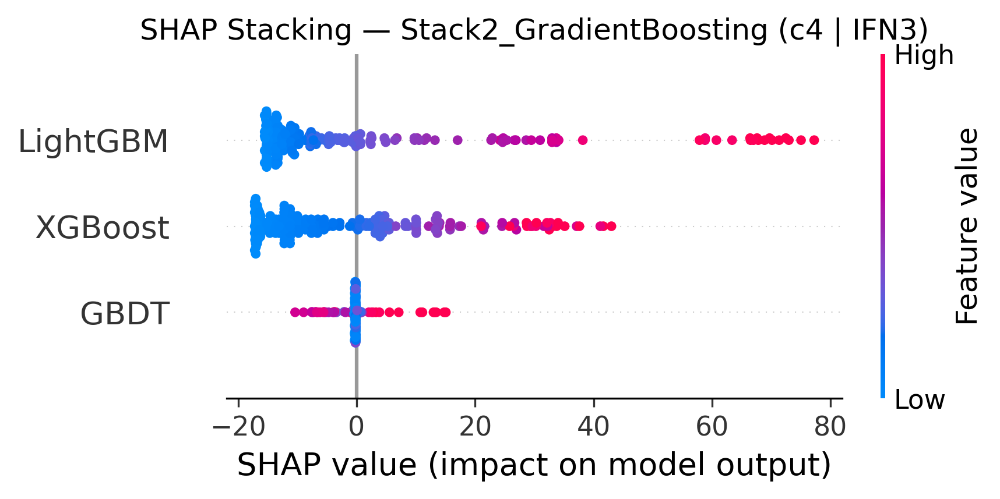

  [OK] Stack2_LinearRegression


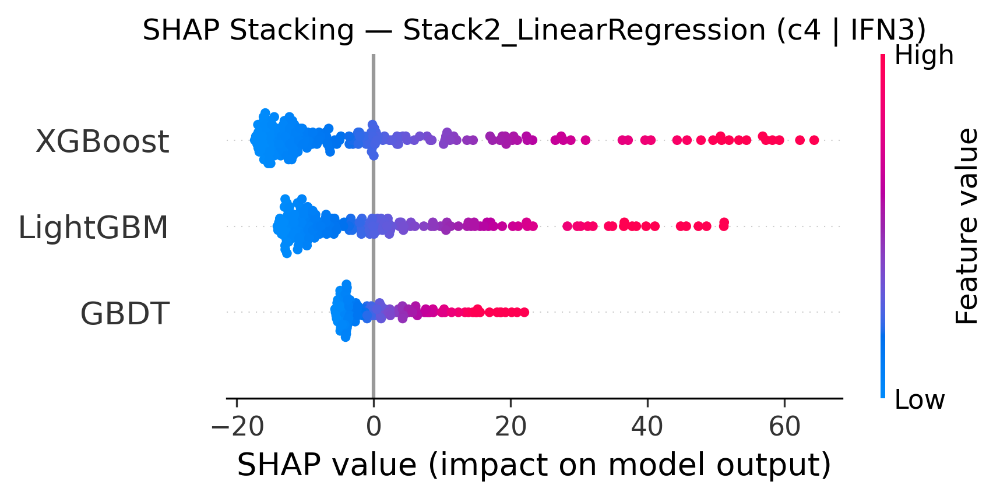

  [OK] Stack2_MLP


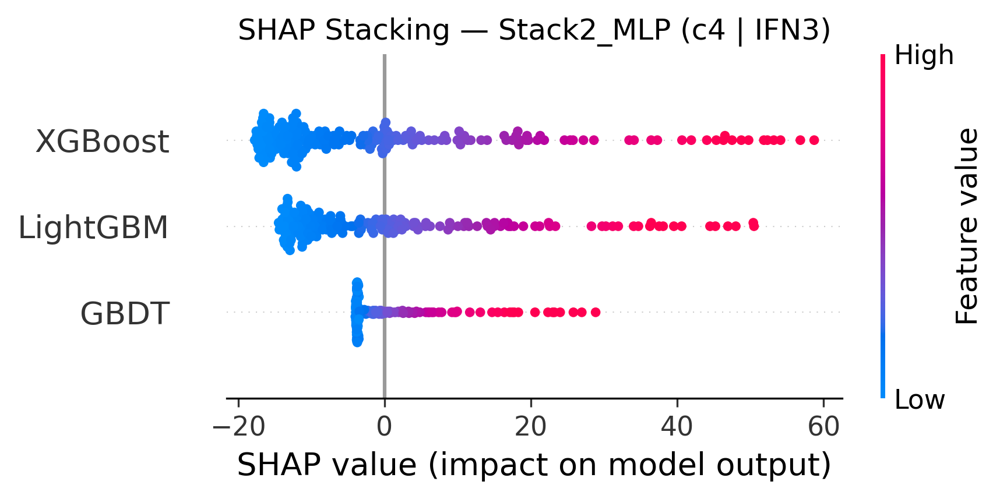

  [OK] Stack2_RandomForest


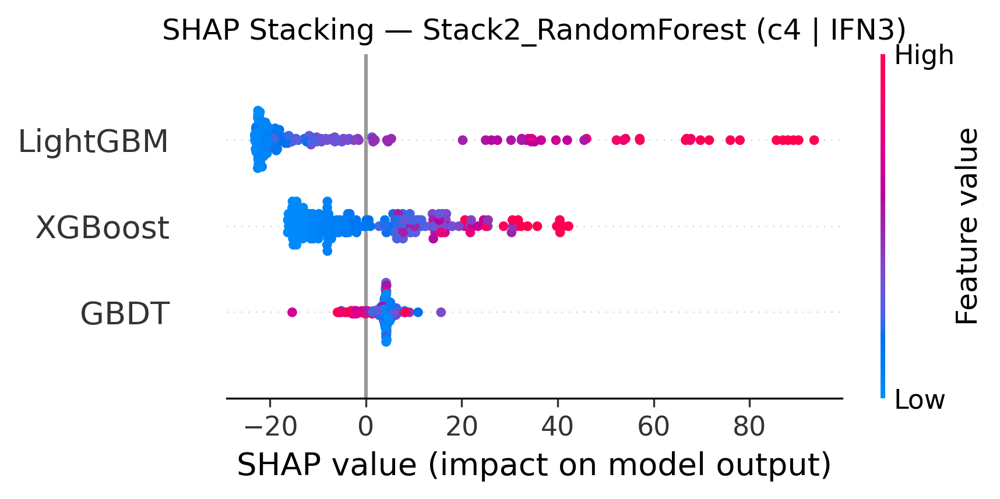

  [OK] Stack2_Ridge


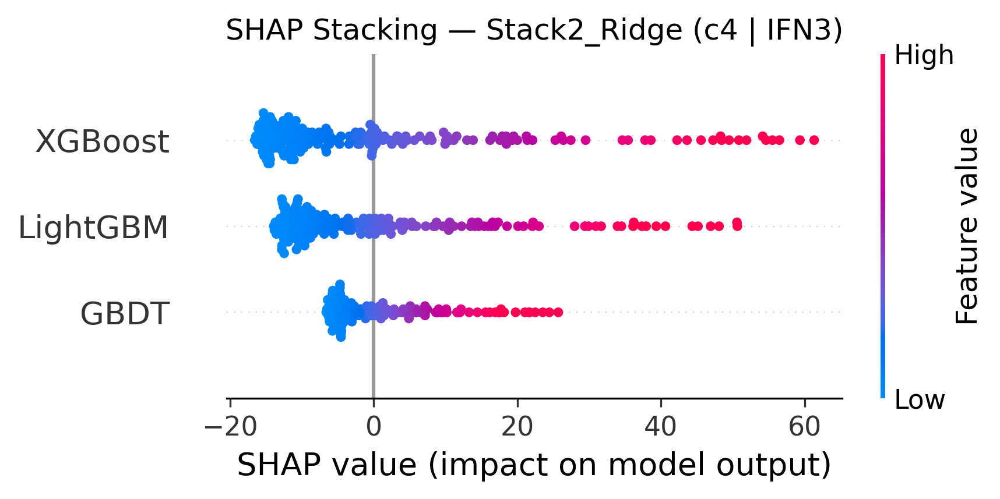

  [OK] Stack2_SVR


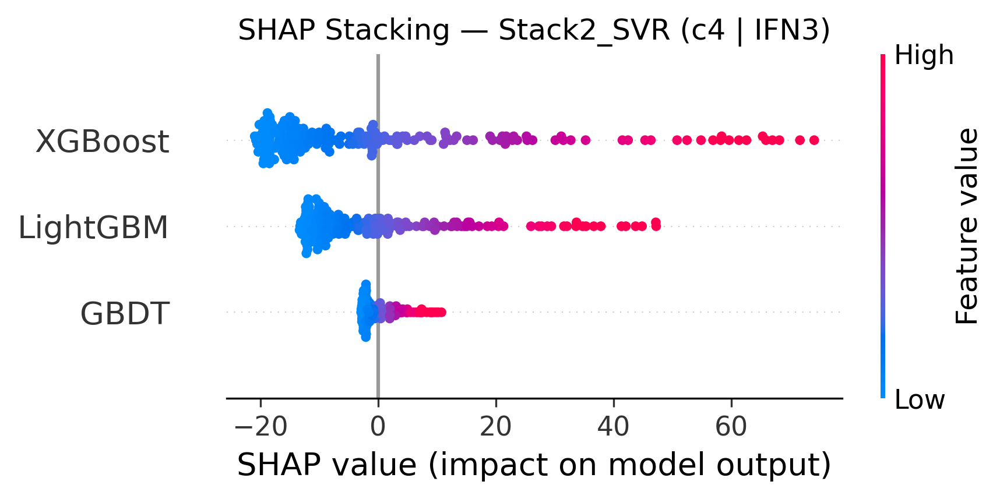


Stack3 (c4) — bases: ['CatBoost', 'Random_Forest', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack3_GradientBoosting


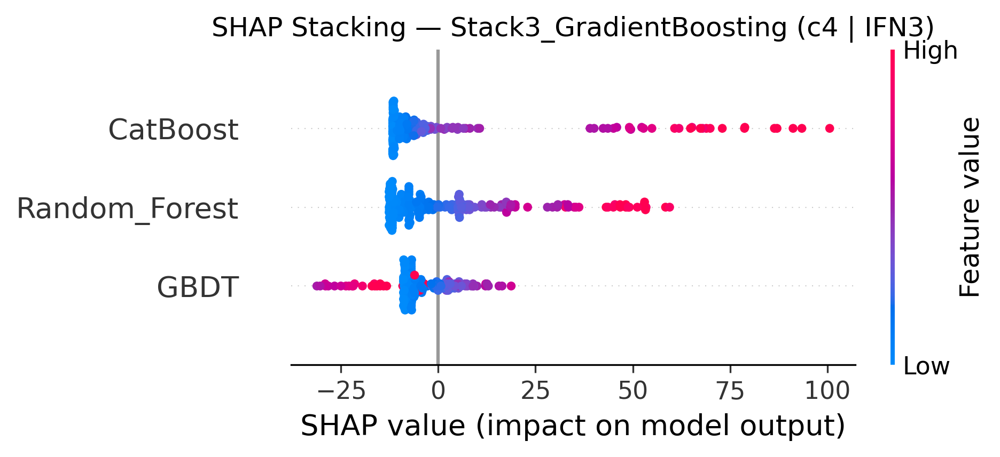

  [OK] Stack3_LinearRegression


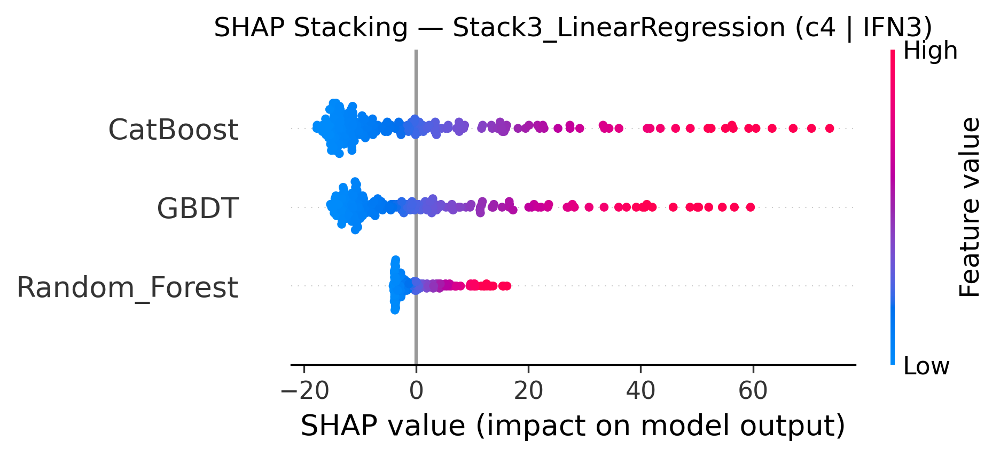

  [OK] Stack3_MLP


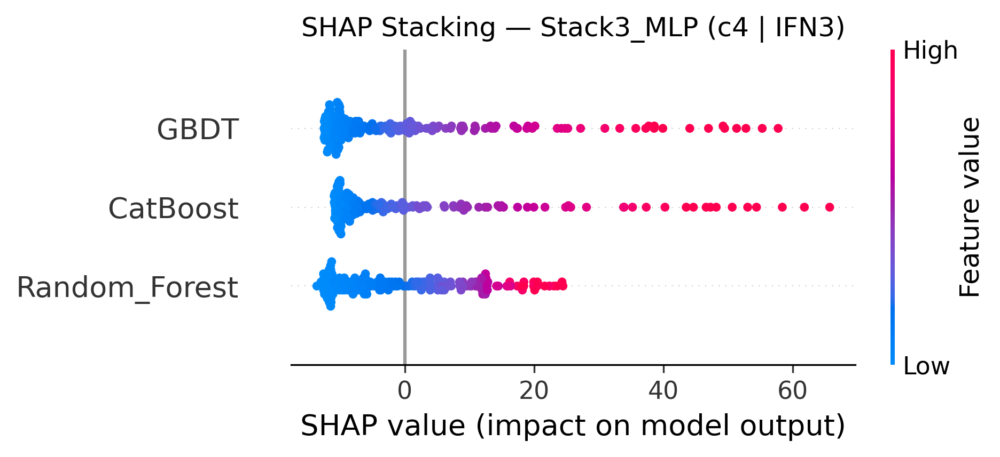

  [OK] Stack3_RandomForest


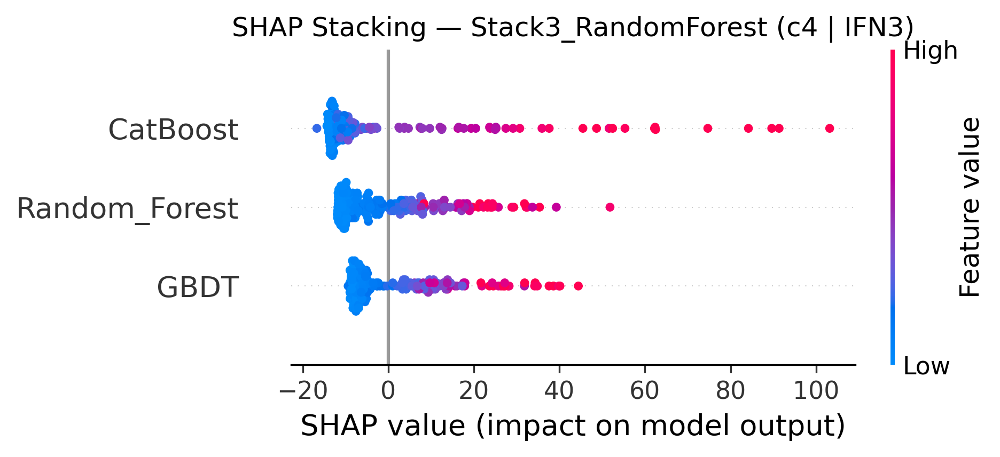

  [OK] Stack3_Ridge


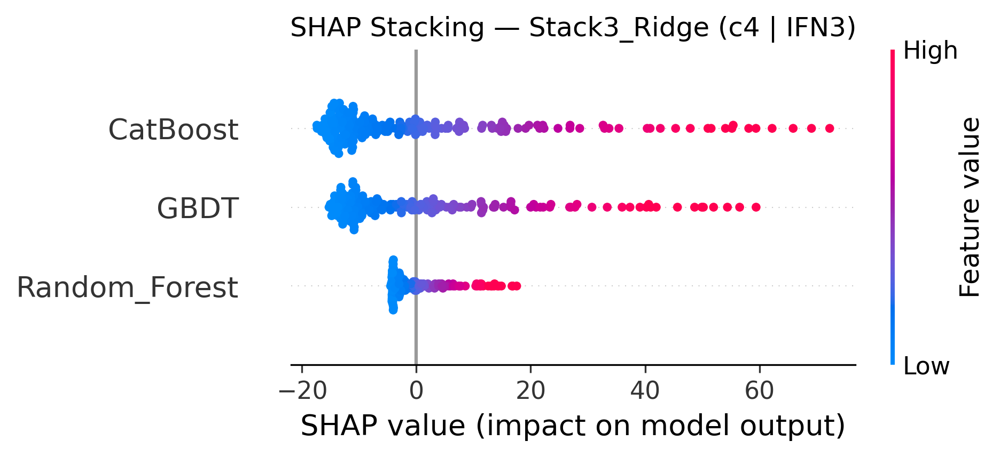

  [OK] Stack3_SVR


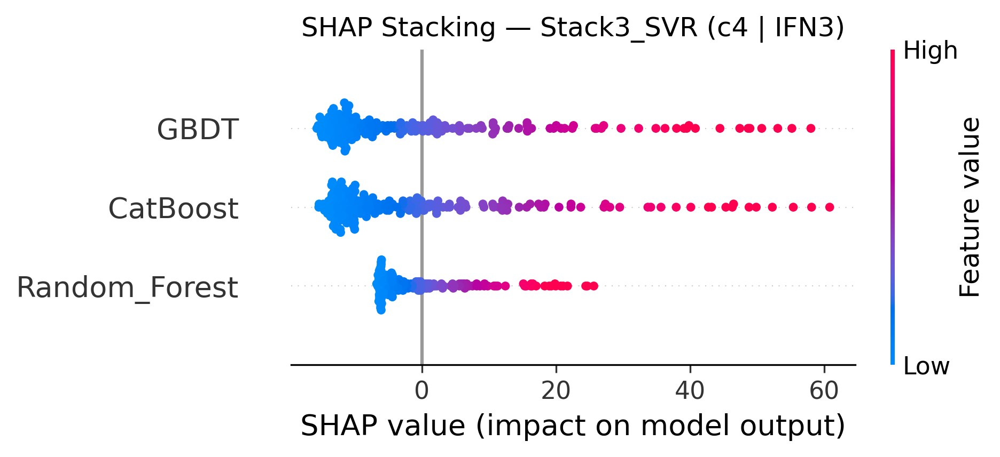


Stack4 (c4) — bases: ['CatBoost', 'LightGBM', 'Random_Forest', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack4_GradientBoosting


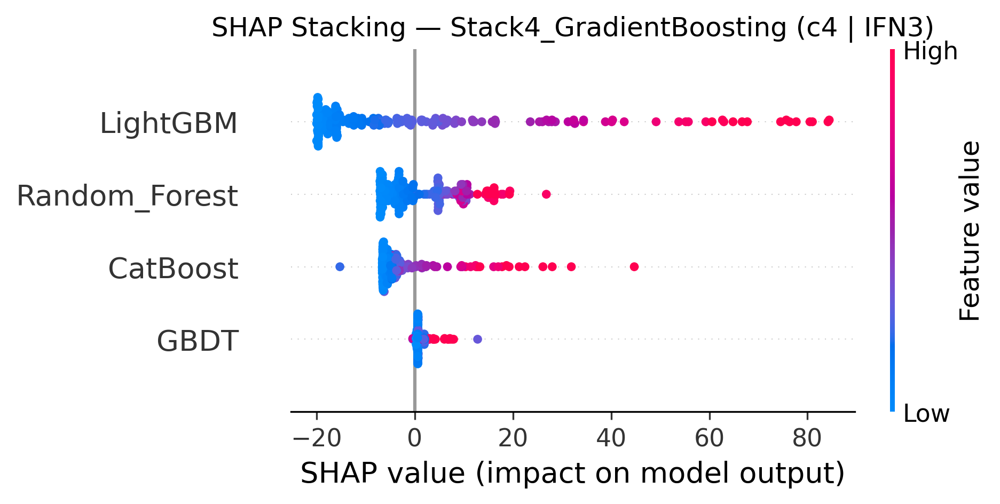

  [OK] Stack4_LinearRegression


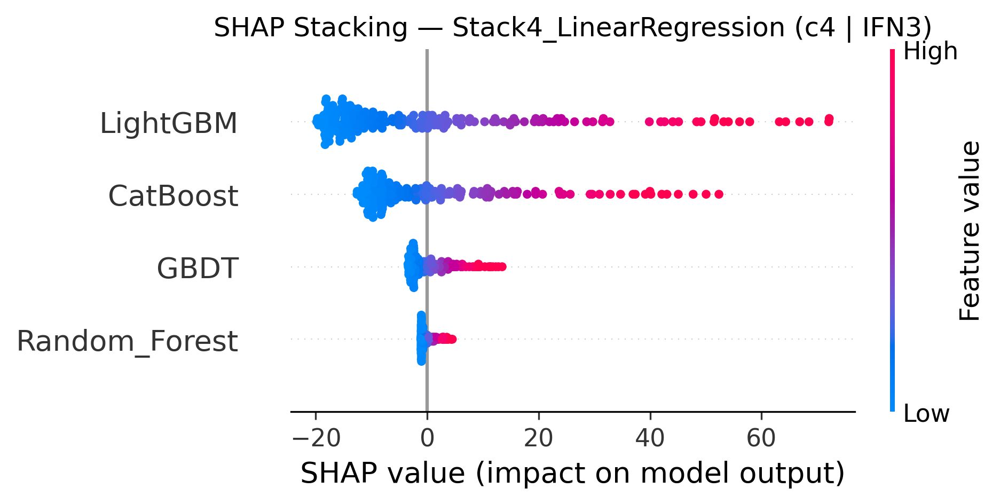

  [OK] Stack4_MLP


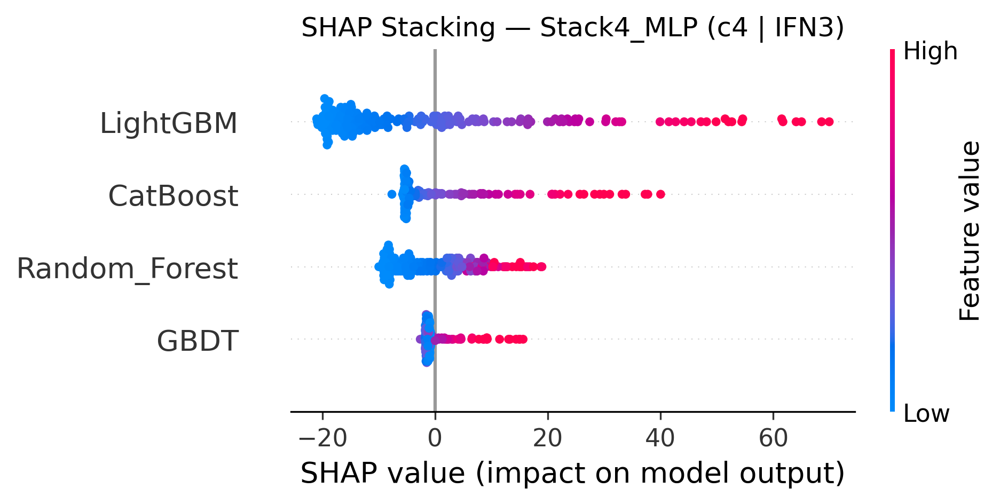

  [OK] Stack4_RandomForest


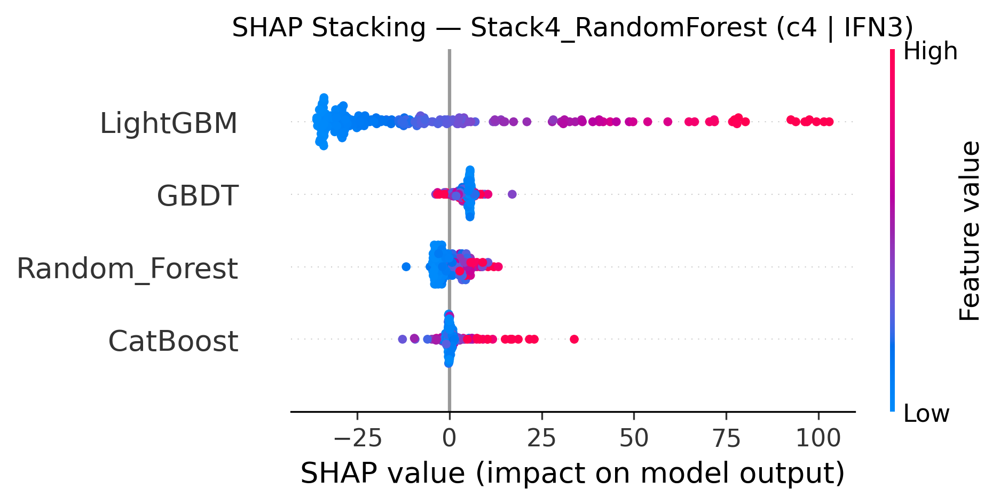

  [OK] Stack4_Ridge


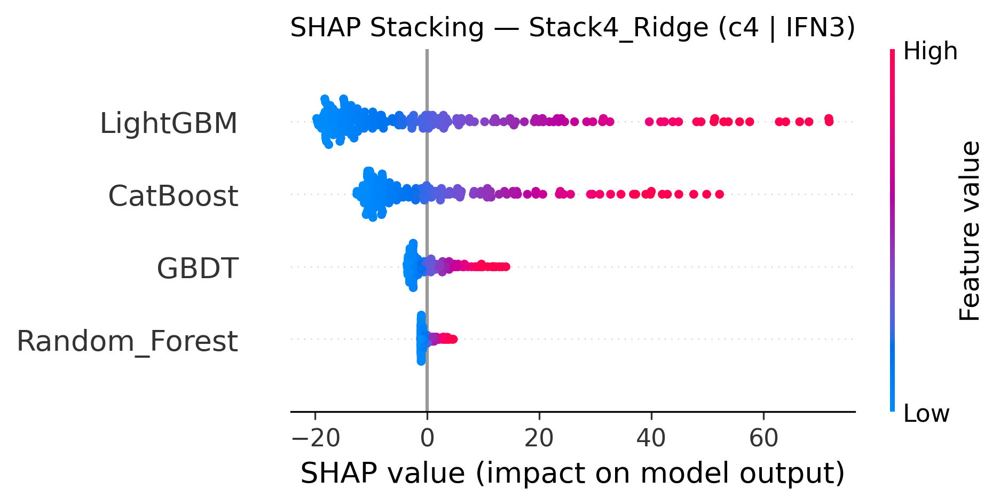

  [OK] Stack4_SVR


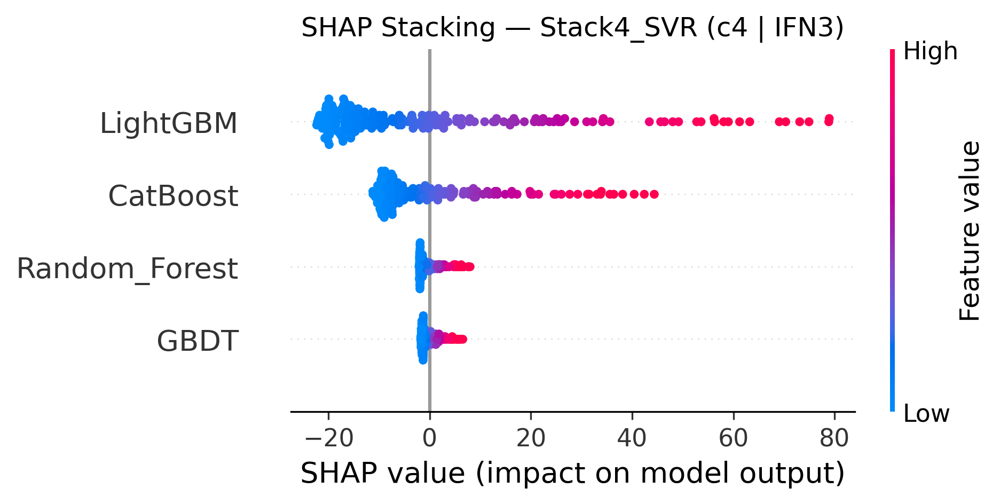


Stack5 (c4) — bases: ['CatBoost', 'LightGBM', 'XGBoost', 'Random_Forest', 'GBDT', 'BaggedDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack5_GradientBoosting


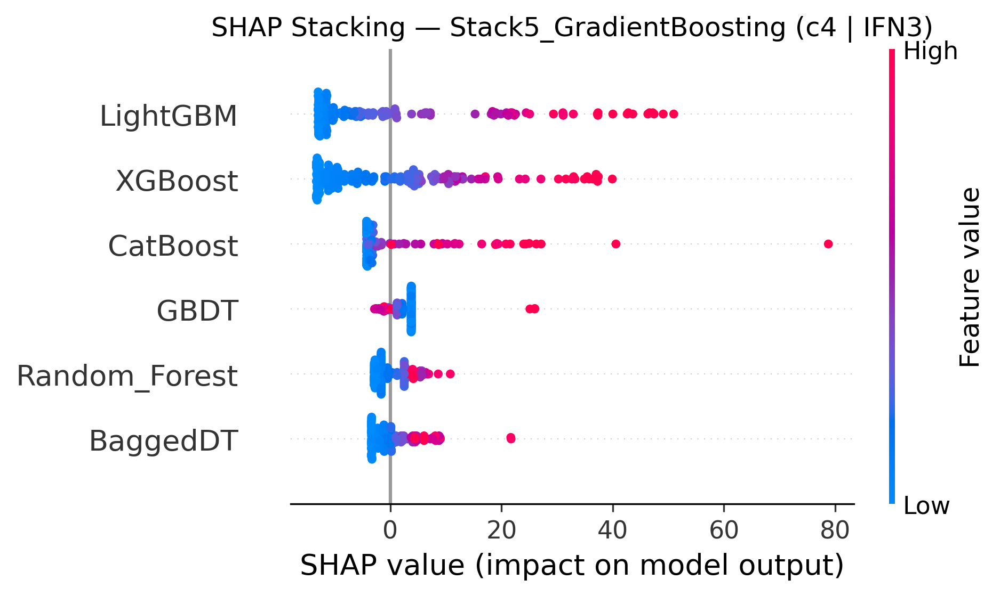

  [OK] Stack5_LinearRegression


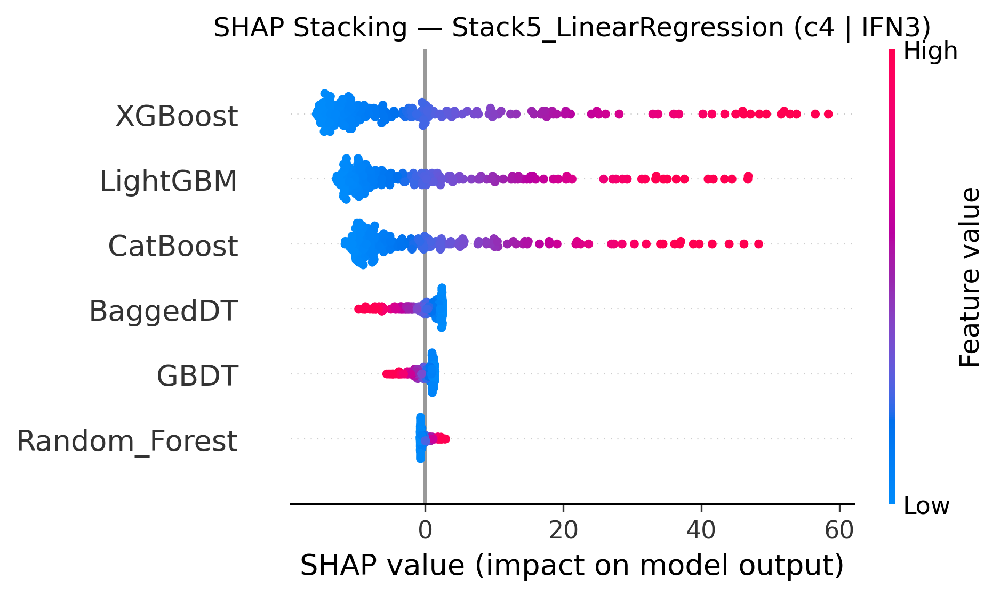

  [OK] Stack5_MLP


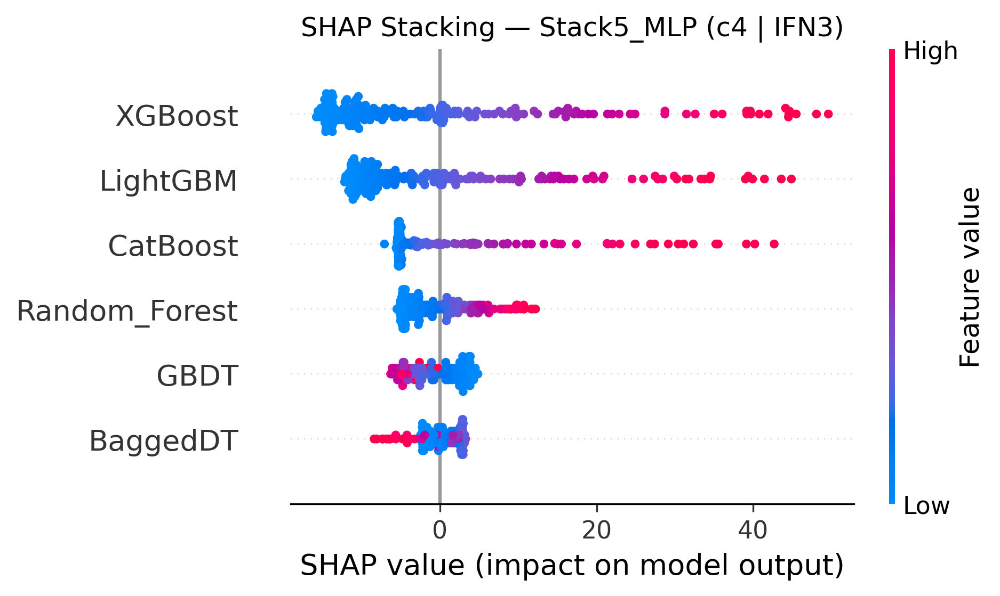

  [OK] Stack5_RandomForest


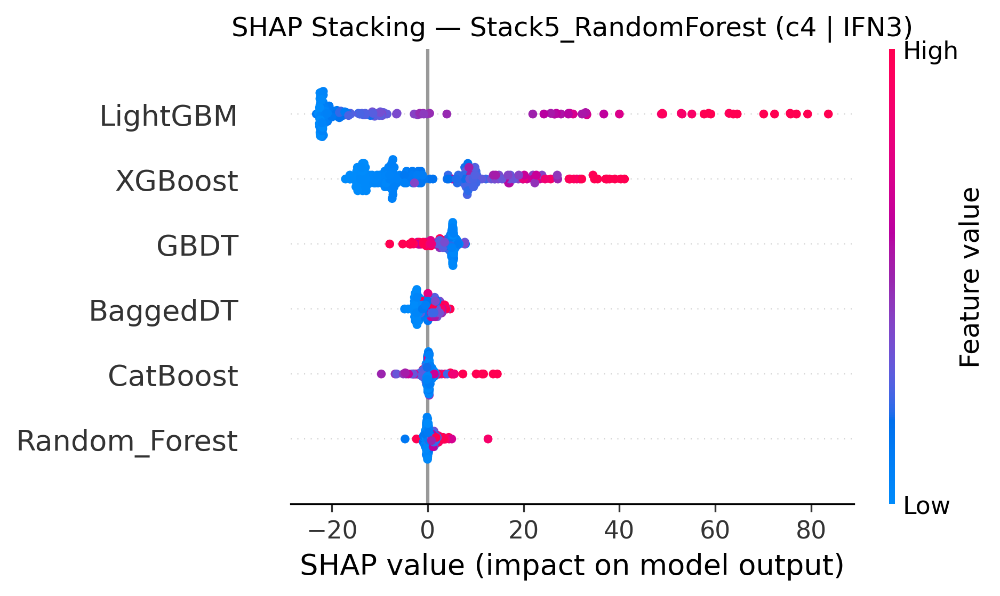

  [OK] Stack5_Ridge


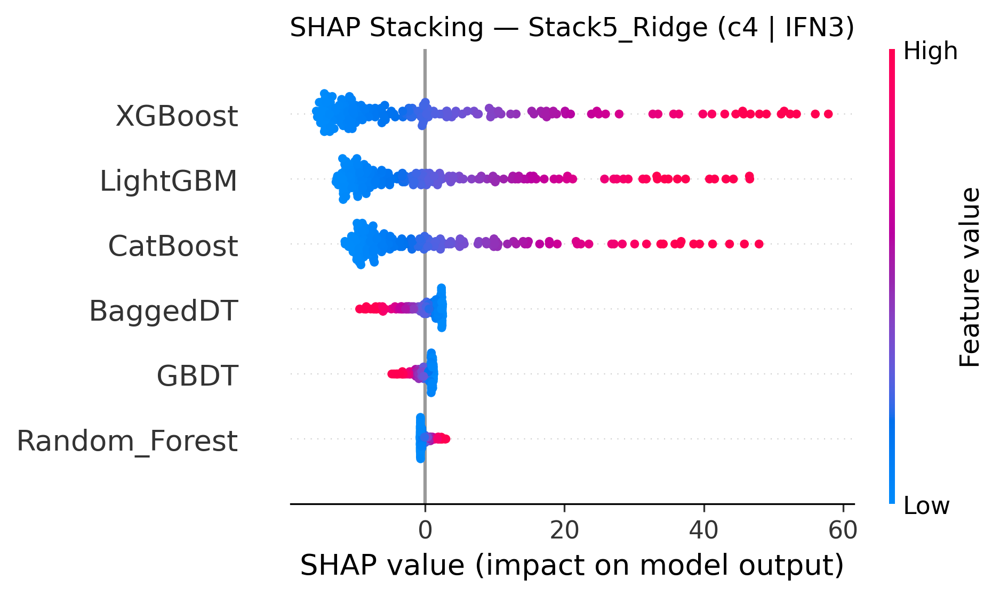

  [OK] Stack5_SVR


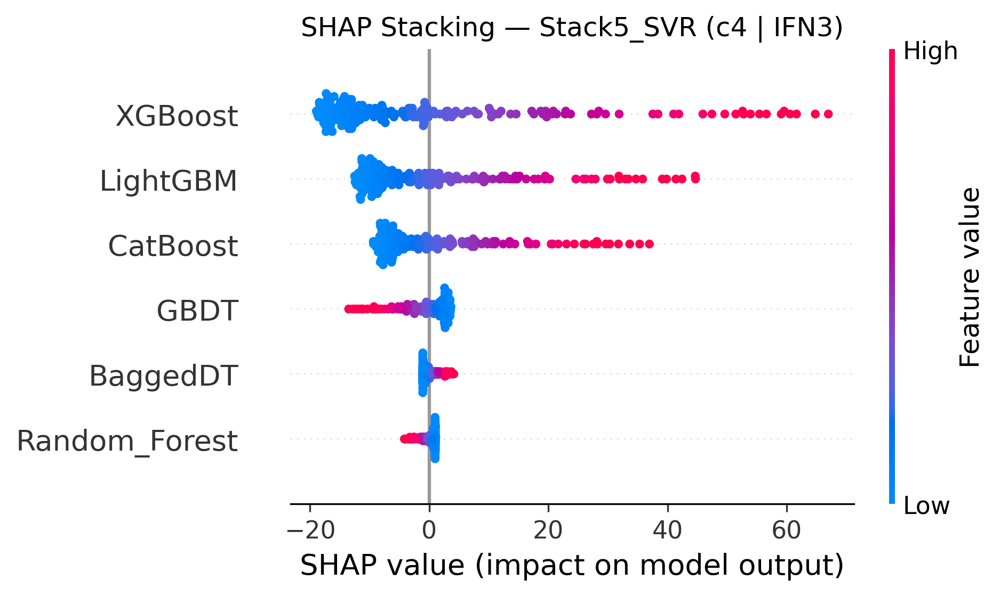


Sección 6 completada.


In [36]:
out_dir_stack_c4 = OUTPUT_SHAP / 'c4' / 'stacking_beeswarm'
out_dir_stack_c4.mkdir(parents=True, exist_ok=True)

for stack_name, base_names in STACK_CONFIGS.items():
    print(f'\n{"="*60}')
    print(f'{stack_name} (c4) — bases: {base_names}')
    print(f'{"="*60}')

    meta_files = sorted(MODELS_IFN3_C4_STACK.glob(f'{stack_name}_*.joblib'))

    # Comprobar si todos los plots ya existen antes de cargar las bases
    save_paths = {mp.stem: out_dir_stack_c4 / f'beeswarm_{mp.stem}.png' for mp in meta_files}
    all_exist  = all(p.exists() and p.with_suffix('.pdf').exists() for p in save_paths.values())

    if all_exist:
        print(f'  Todos los plots existen — mostrando desde disco')
        for meta_name, save_path in save_paths.items():
            print(f'  [OK] {meta_name}')
            ipy_display(IPImage(str(save_path)))
        continue

    # Al menos uno falta: cargar bases una por una y generar meta-features
    X_meta = make_meta_features(base_names, MODELS_IFN3_C4, X_sample_c4, FEATURES_C4)
    print(f'  Meta-features: {X_meta.shape}')

    for meta_path in meta_files:
        meta_name = meta_path.stem
        save_path = save_paths[meta_name]

        if save_path.exists() and save_path.with_suffix('.pdf').exists():
            print(f'  [OK] {meta_name}')
            ipy_display(IPImage(str(save_path)))
            continue

        print(f'  {meta_name}...', end=' ')
        meta_pipe = None
        try:
            meta_pipe = joblib.load(meta_path)
            shap_vals, X_scaled, base_val = compute_meta_shap(meta_pipe, X_meta)
            del meta_pipe; meta_pipe = None
            gc.collect()

            explanation = shap.Explanation(
                values=shap_vals,
                base_values=base_val,
                data=X_scaled.values,
                feature_names=list(X_meta.columns)
            )
            n_feats = len(base_names)
            fig, ax = plt.subplots(figsize=(9, max(4, n_feats + 2)))
            shap.plots.beeswarm(explanation, max_display=n_feats, show=False)
            plt.title(f'SHAP Stacking — {meta_name} (c4 | IFN3)', fontsize=12)
            plt.subplots_adjust(left=0.35, bottom=0.15)
            print(f'  -> {save_path}')
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
            plt.show()
            plt.close()
            print('OK')
        except Exception as e:
            print(f'ERROR: {e}')
        finally:
            if meta_pipe is not None:
                del meta_pipe
            gc.collect()

    del X_meta
    gc.collect()

print('\nSección 6 completada.')

---
## 7. SHAP Beeswarm — Modelos Stacking (carbono\_bruto4, IFN3)

Mismo análisis que la sección 6 pero para el target `carbono_bruto4`.


Stack1 (carbono_bruto4) — bases: ['LightGBM', 'Random_Forest']
  Todos los plots existen — mostrando desde disco
  [OK] Stack1_GradientBoosting


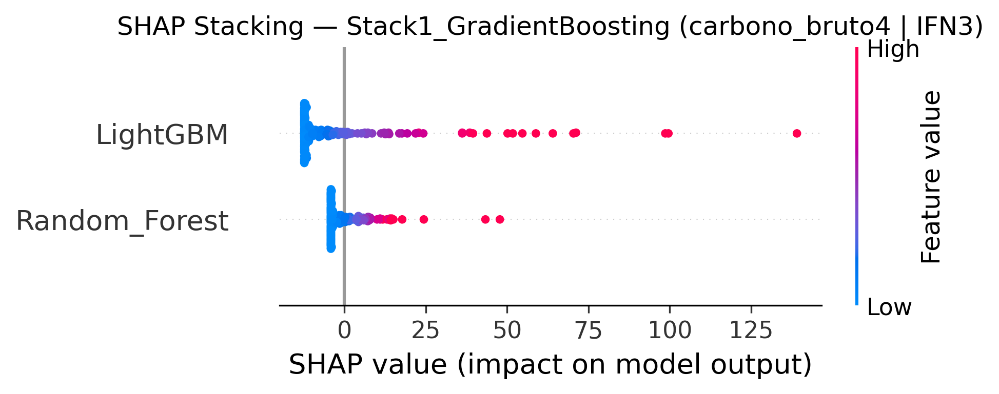

  [OK] Stack1_LinearRegression


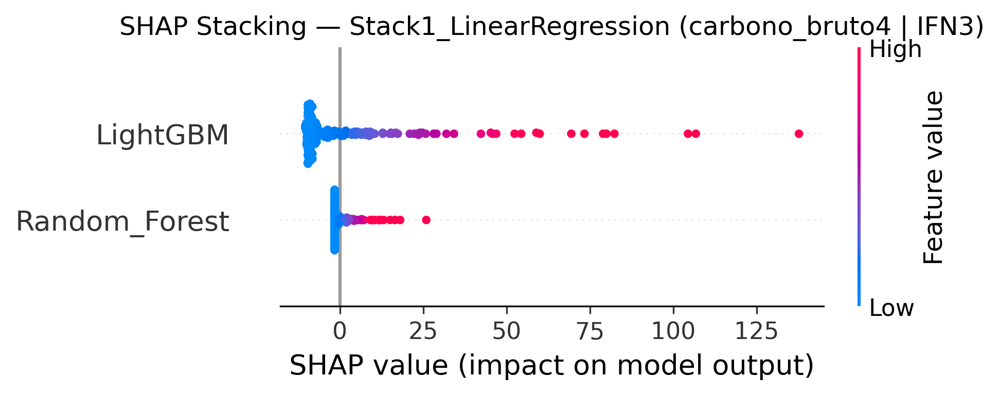

  [OK] Stack1_MLP


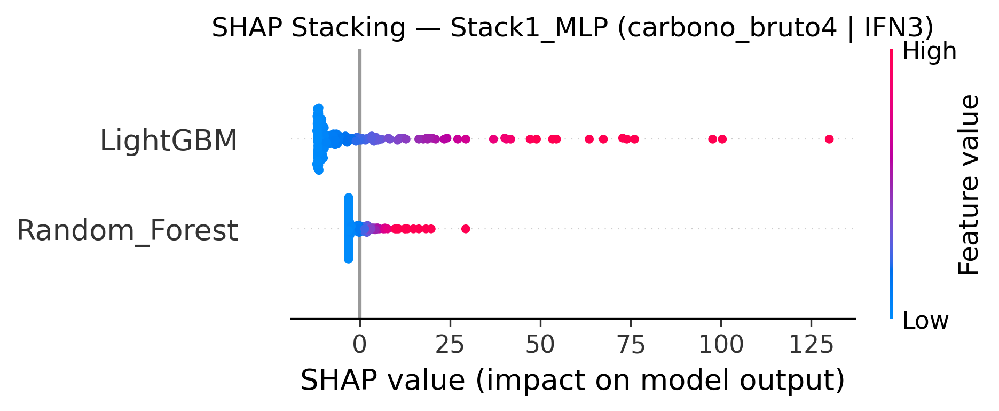

  [OK] Stack1_RandomForest


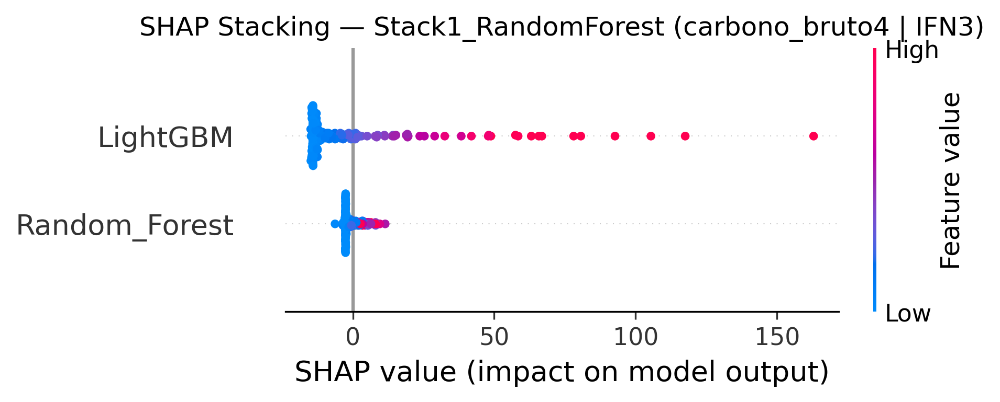

  [OK] Stack1_Ridge


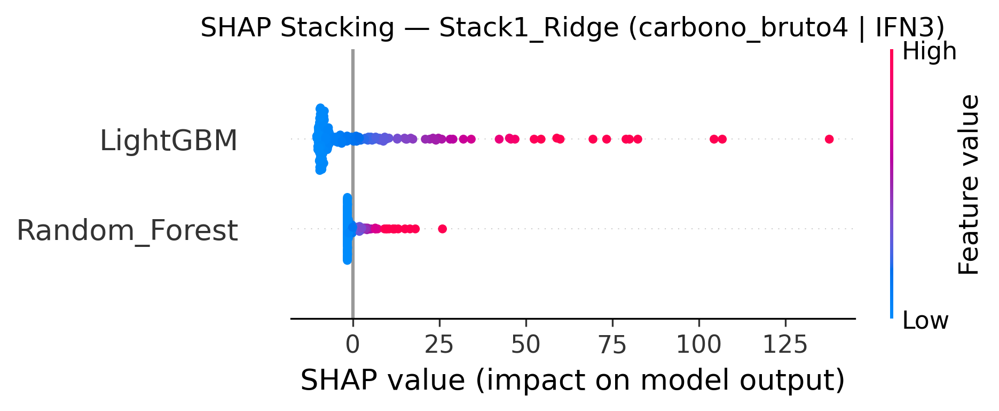

  [OK] Stack1_SVR


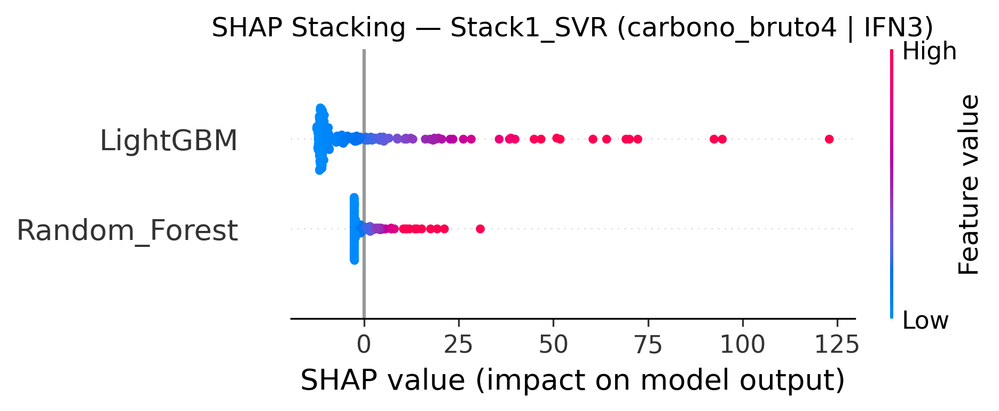


Stack2 (carbono_bruto4) — bases: ['LightGBM', 'XGBoost', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack2_GradientBoosting


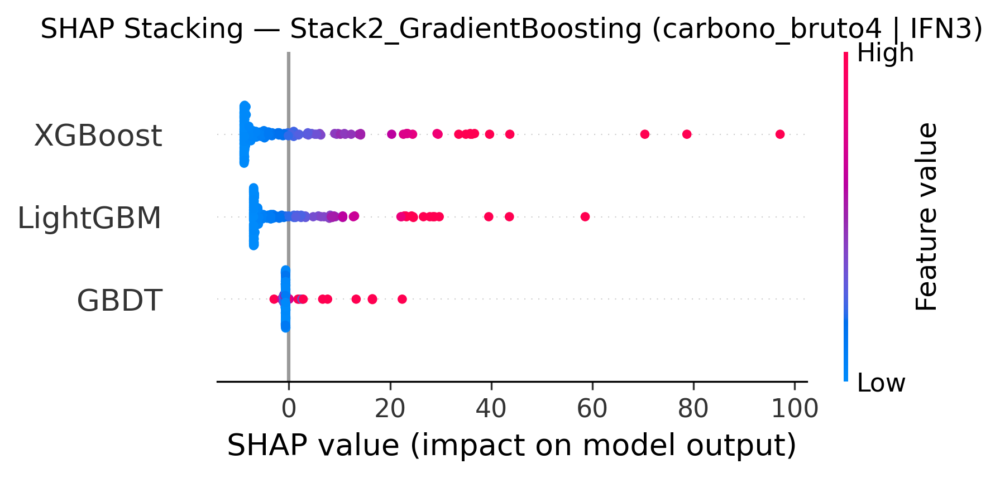

  [OK] Stack2_LinearRegression


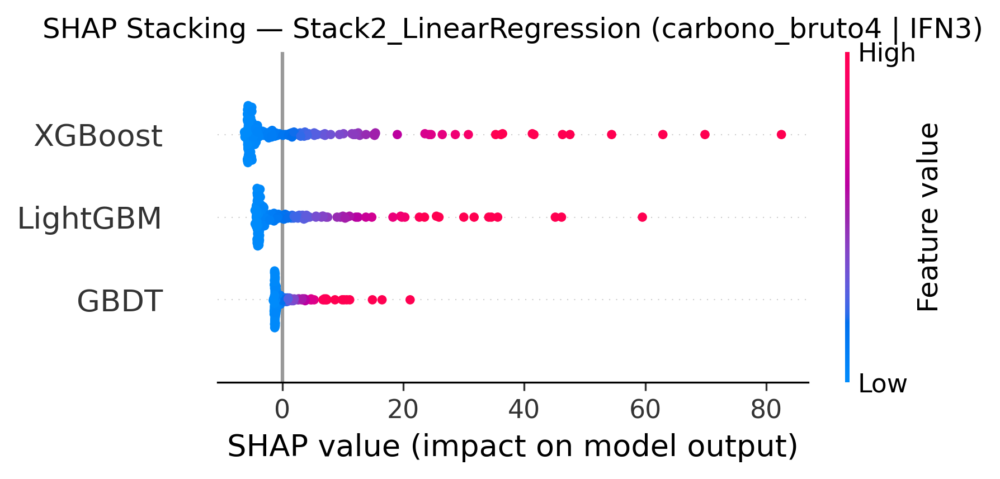

  [OK] Stack2_MLP


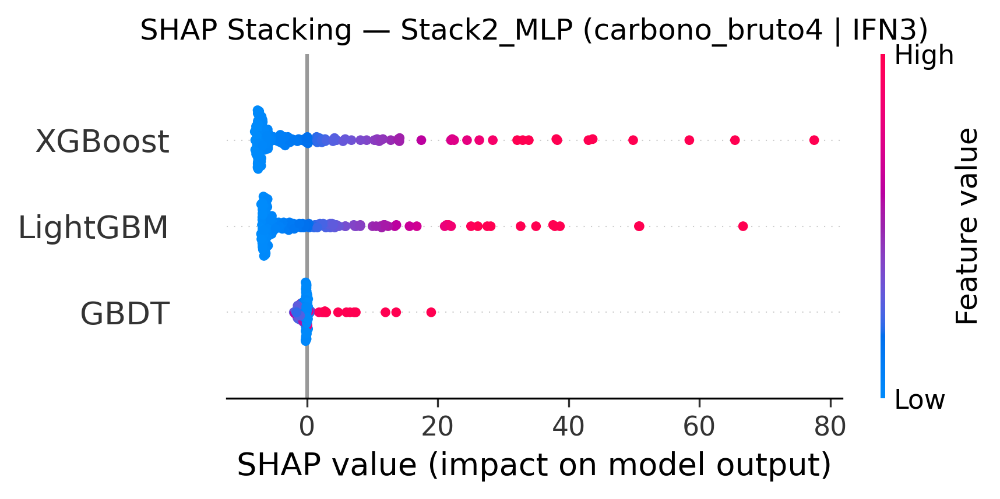

  [OK] Stack2_RandomForest


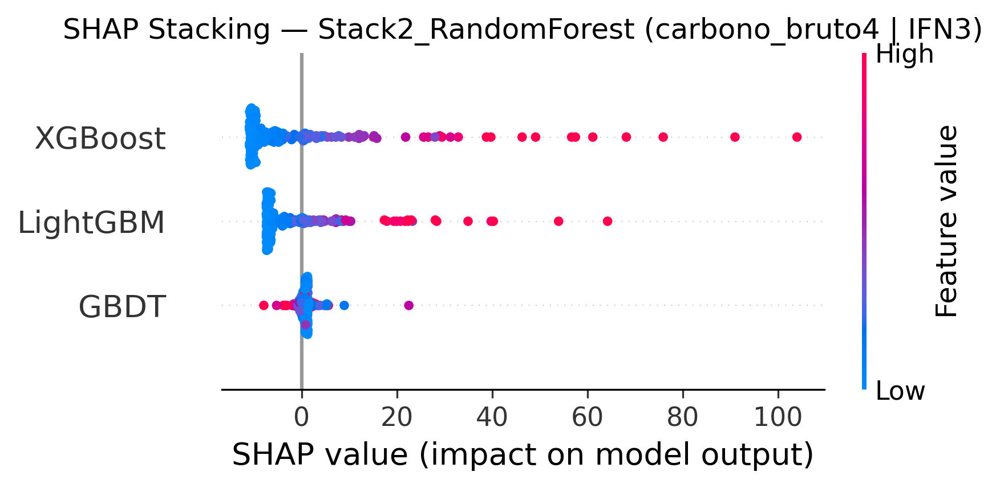

  [OK] Stack2_Ridge


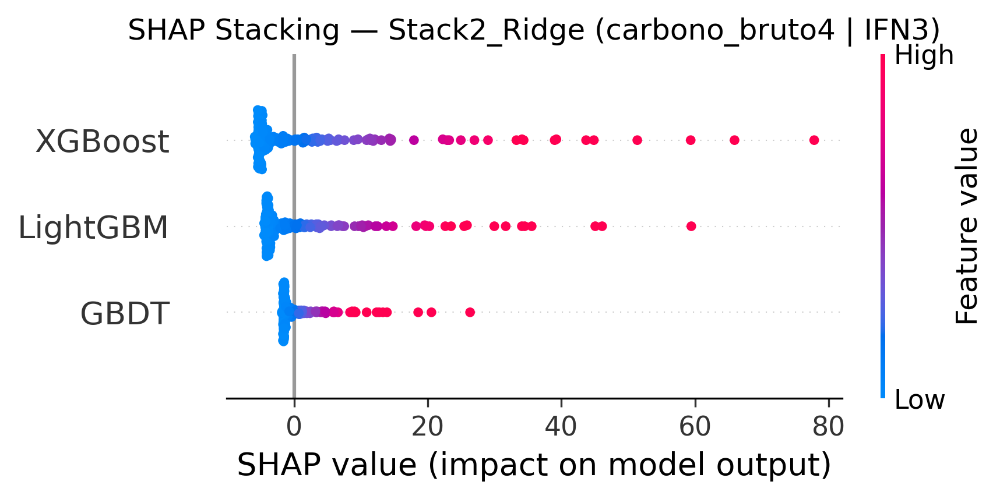

  [OK] Stack2_SVR


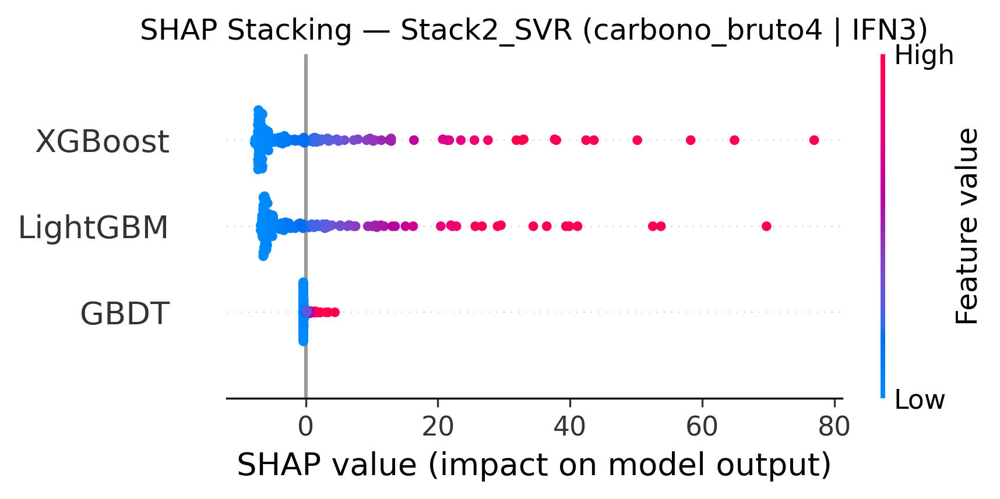


Stack3 (carbono_bruto4) — bases: ['CatBoost', 'Random_Forest', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack3_GradientBoosting


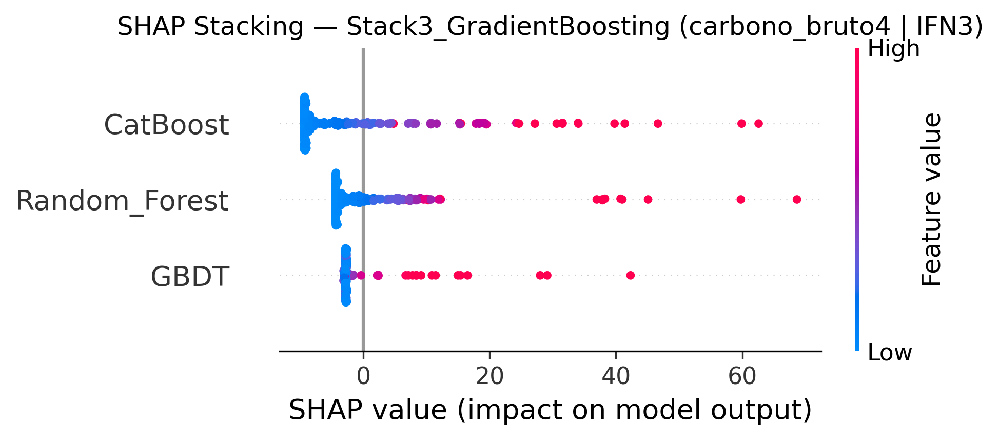

  [OK] Stack3_LinearRegression


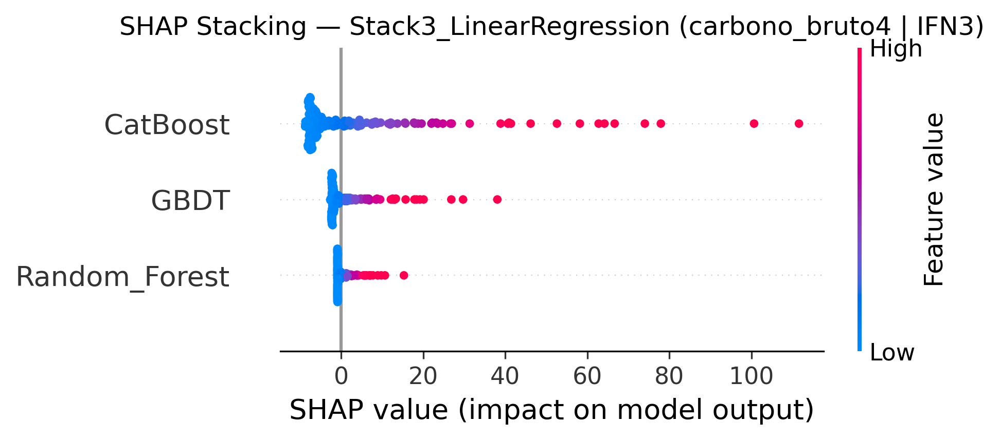

  [OK] Stack3_MLP


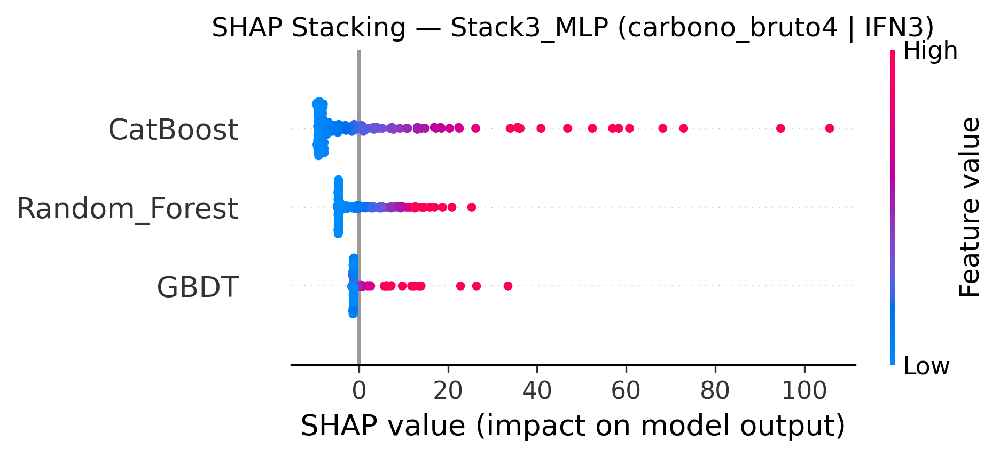

  [OK] Stack3_RandomForest


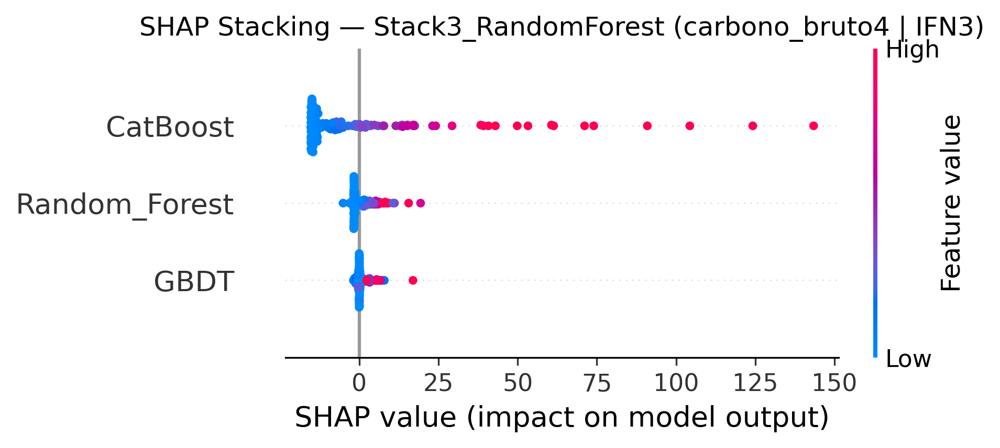

  [OK] Stack3_Ridge


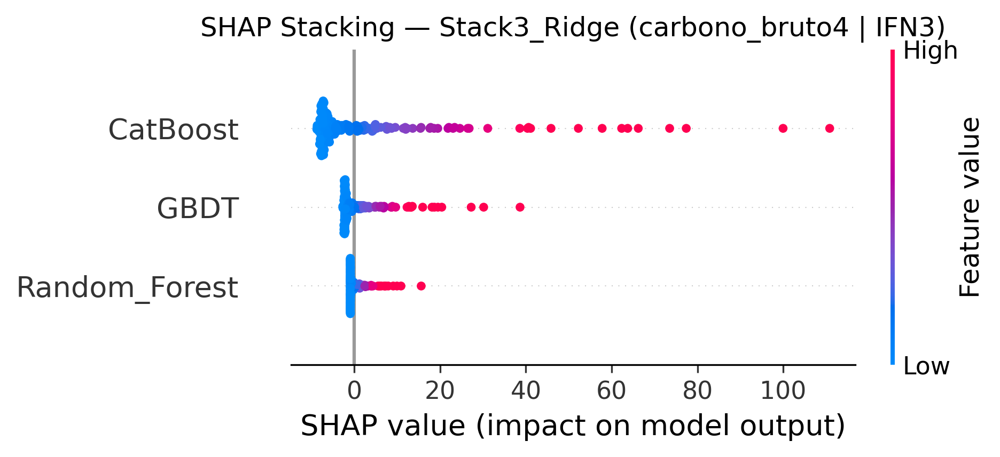

  [OK] Stack3_SVR


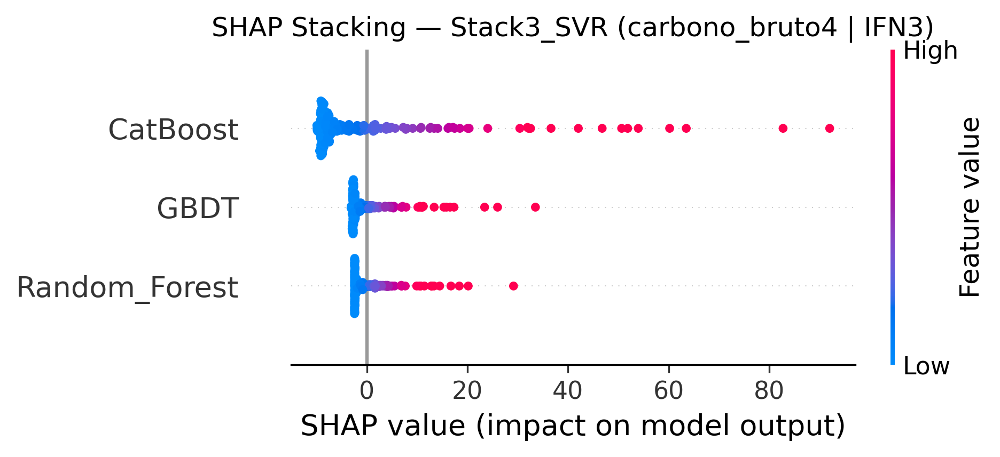


Stack4 (carbono_bruto4) — bases: ['CatBoost', 'LightGBM', 'Random_Forest', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack4_GradientBoosting


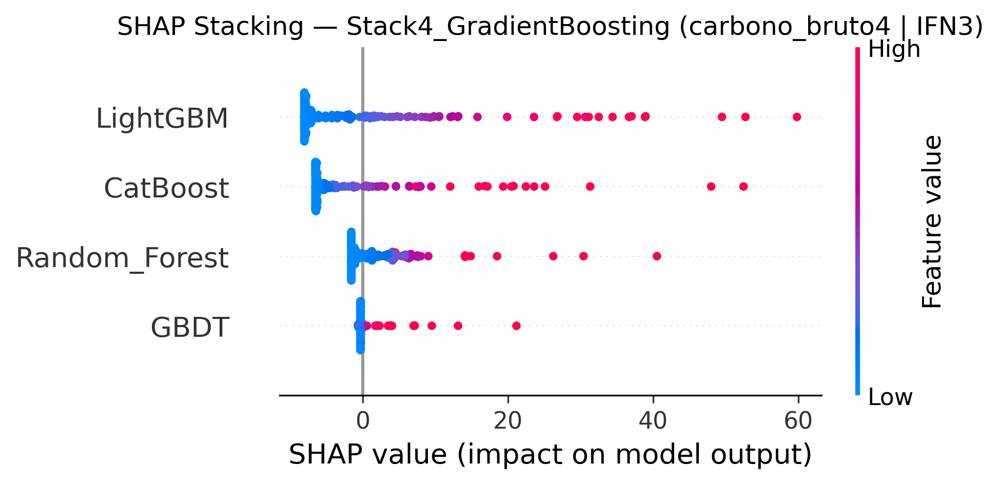

  [OK] Stack4_LinearRegression


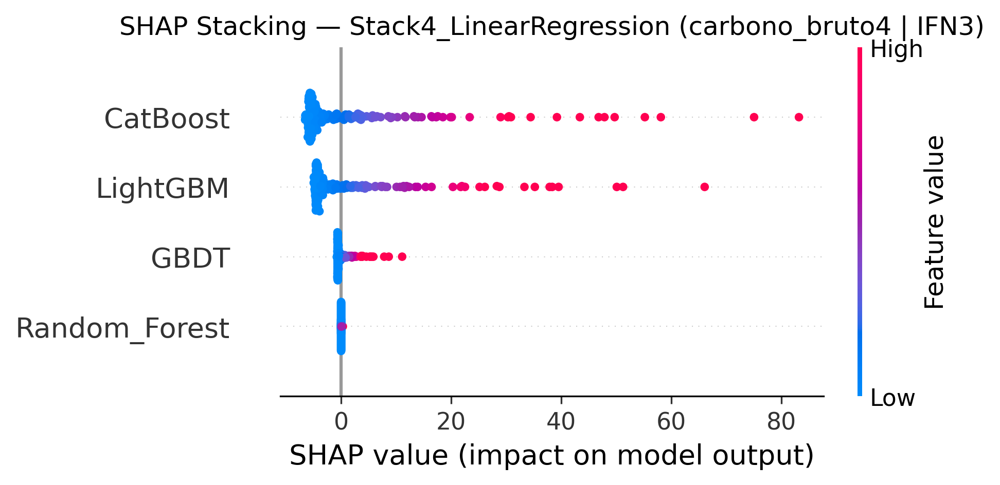

  [OK] Stack4_MLP


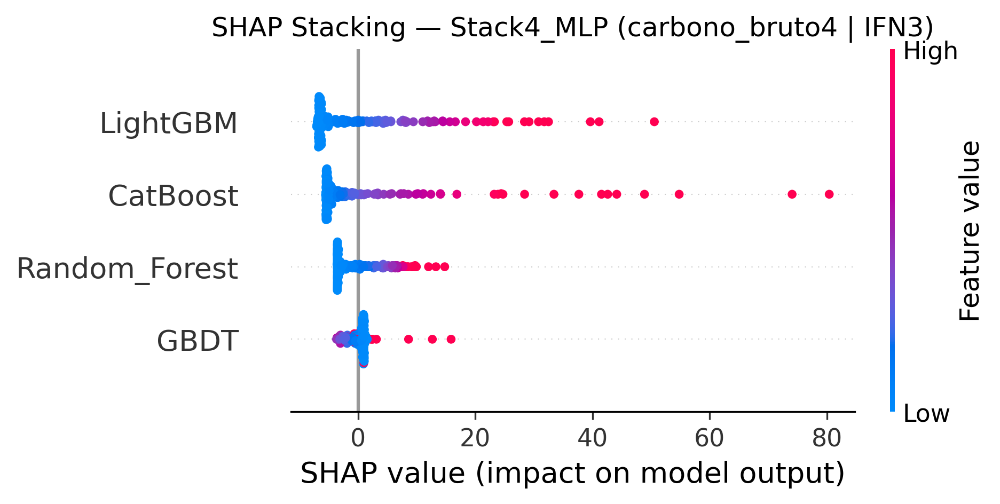

  [OK] Stack4_RandomForest


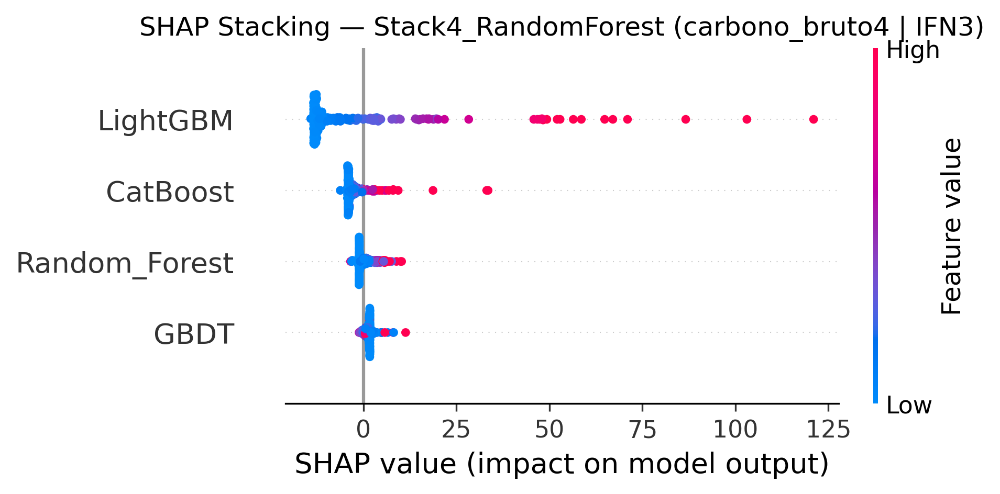

  [OK] Stack4_Ridge


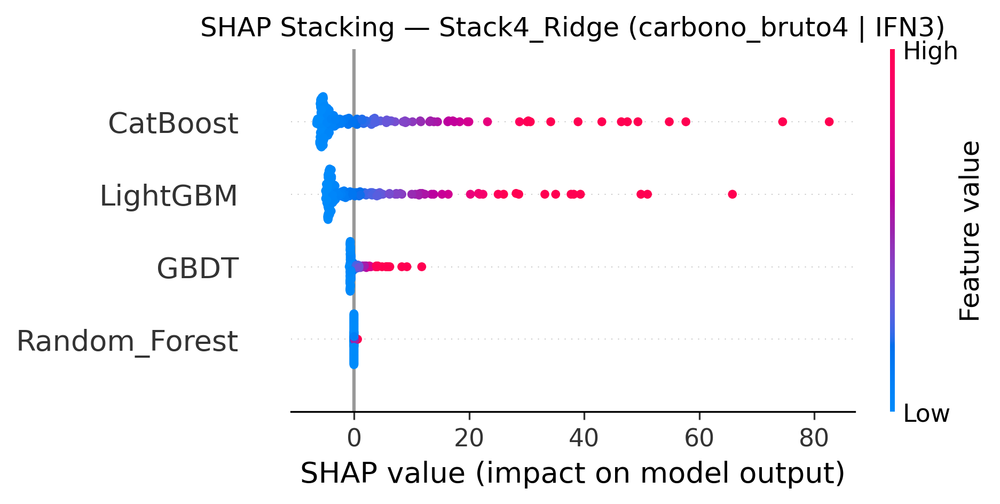

  [OK] Stack4_SVR


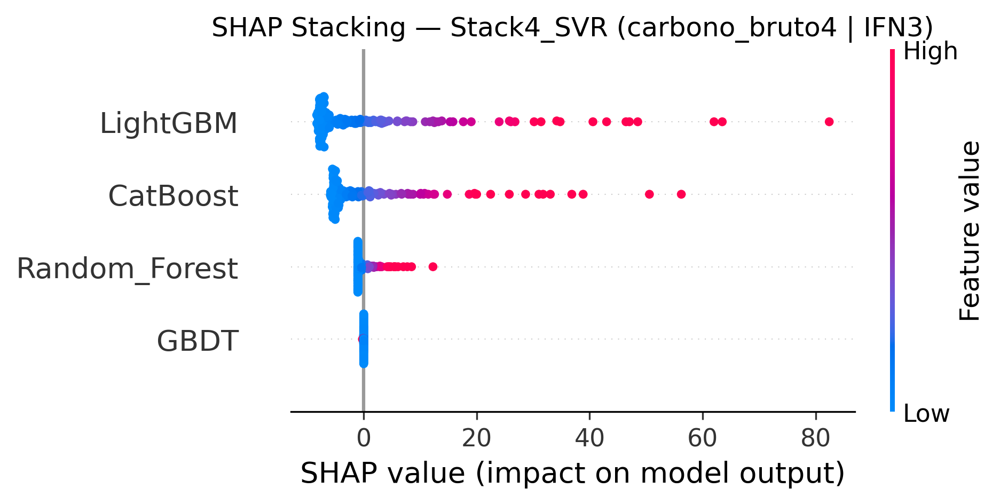


Stack5 (carbono_bruto4) — bases: ['CatBoost', 'LightGBM', 'XGBoost', 'Random_Forest', 'GBDT', 'BaggedDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack5_GradientBoosting


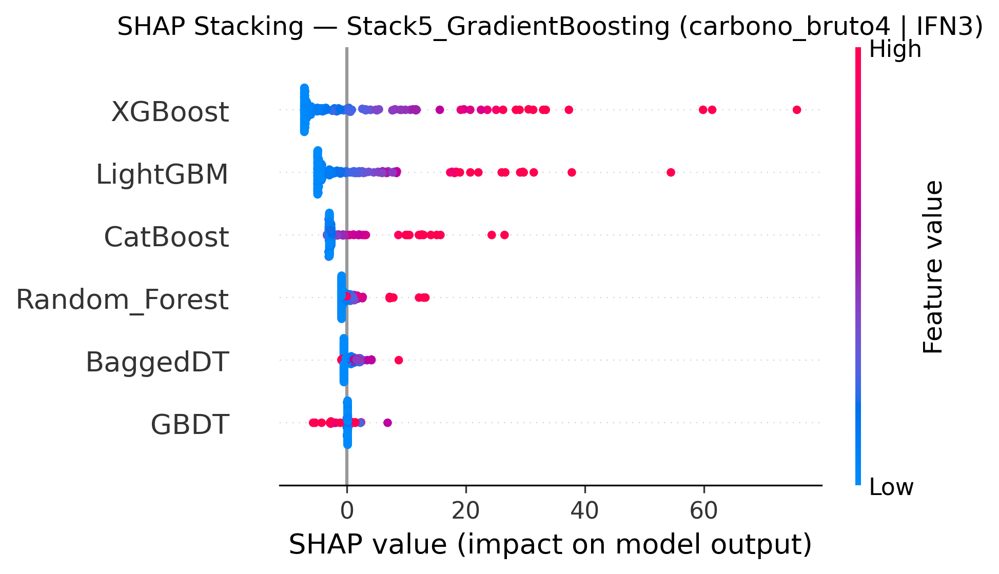

  [OK] Stack5_LinearRegression


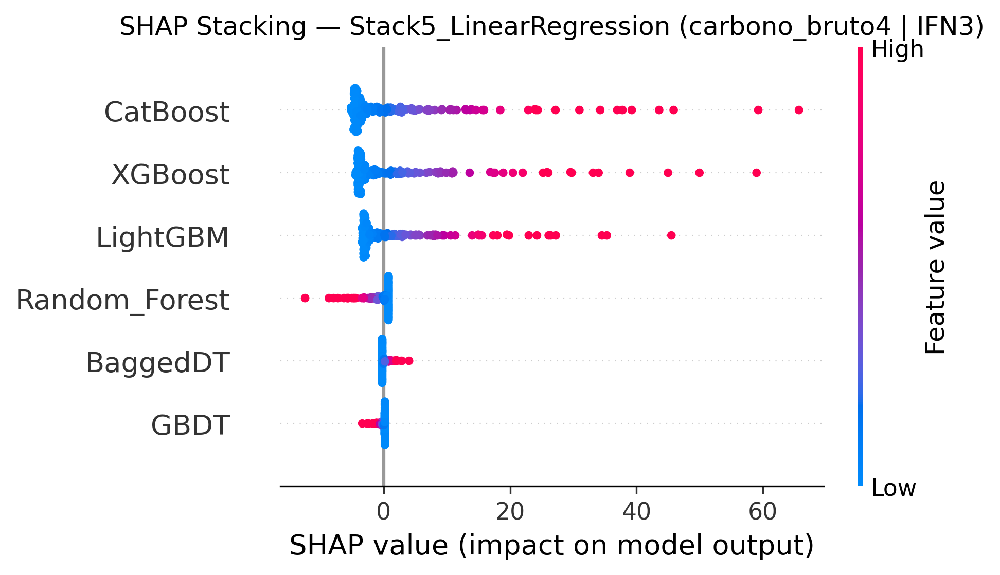

  [OK] Stack5_MLP


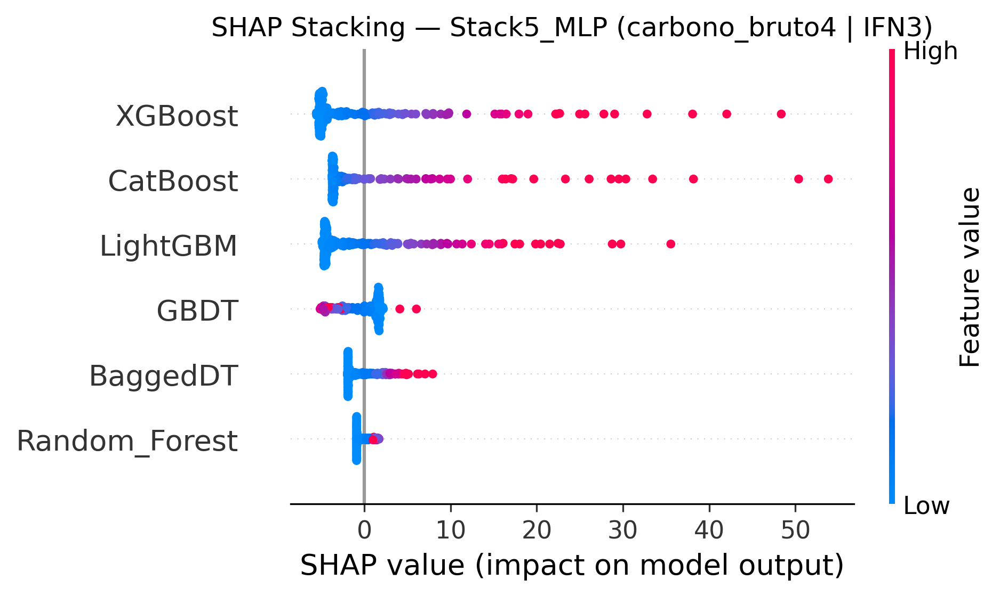

  [OK] Stack5_RandomForest


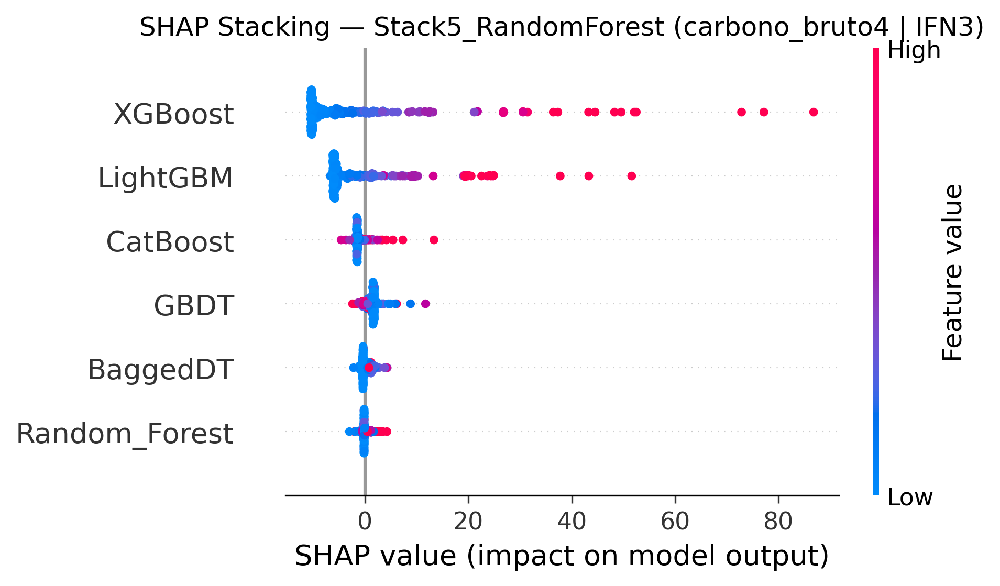

  [OK] Stack5_Ridge


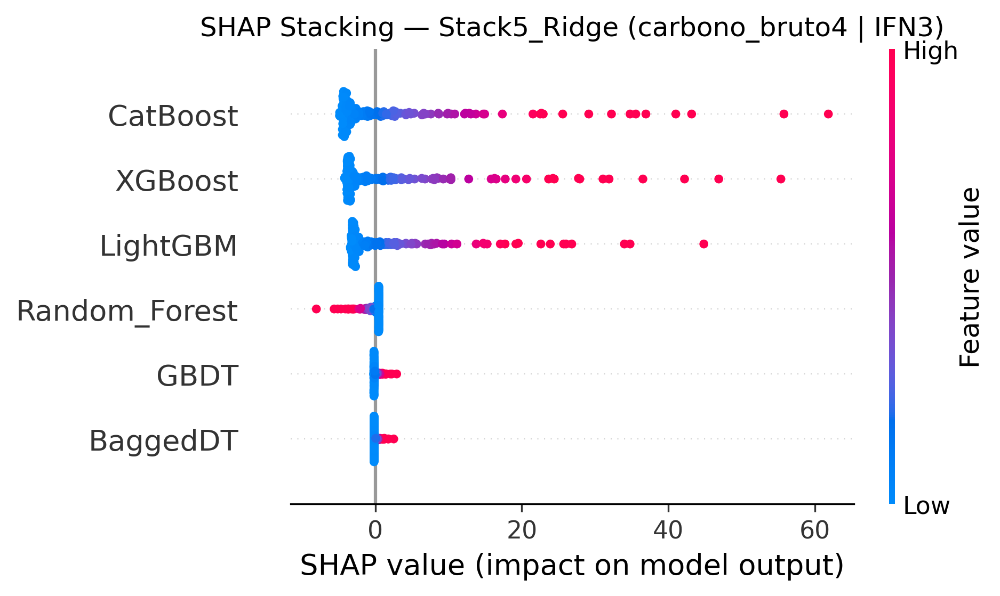

  [OK] Stack5_SVR


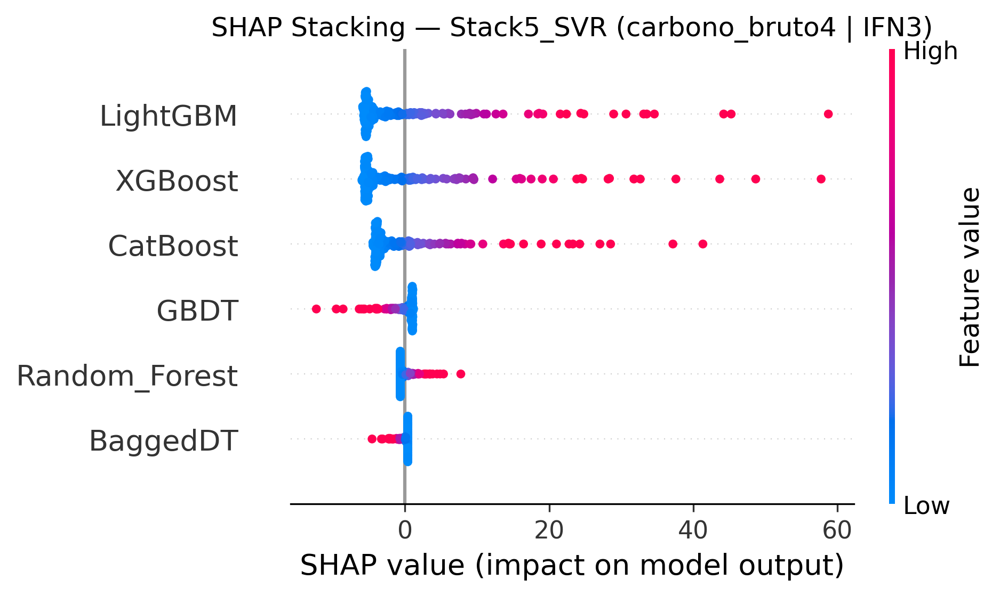


Sección 7 completada.


In [37]:
out_dir_stack_cb4 = OUTPUT_SHAP / 'carbono_bruto4' / 'stacking_beeswarm'
out_dir_stack_cb4.mkdir(parents=True, exist_ok=True)

for stack_name, base_names in STACK_CONFIGS.items():
    print(f'\n{"="*60}')
    print(f'{stack_name} (carbono_bruto4) — bases: {base_names}')
    print(f'{"="*60}')

    meta_files = sorted(MODELS_IFN3_CB4_STACK.glob(f'{stack_name}_*.joblib'))

    # Comprobar si todos los plots ya existen antes de cargar las bases
    save_paths = {mp.stem: out_dir_stack_cb4 / f'beeswarm_{mp.stem}.png' for mp in meta_files}
    all_exist  = all(p.exists() and p.with_suffix('.pdf').exists() for p in save_paths.values())

    if all_exist:
        print(f'  Todos los plots existen — mostrando desde disco')
        for meta_name, save_path in save_paths.items():
            print(f'  [OK] {meta_name}')
            ipy_display(IPImage(str(save_path)))
        continue

    # Al menos uno falta: cargar bases una por una y generar meta-features
    X_meta = make_meta_features(base_names, MODELS_IFN3_CB4, X_sample_cb4, FEATURES_CB4)
    print(f'  Meta-features: {X_meta.shape}')

    for meta_path in meta_files:
        meta_name = meta_path.stem
        save_path = save_paths[meta_name]

        if save_path.exists() and save_path.with_suffix('.pdf').exists():
            print(f'  [OK] {meta_name}')
            ipy_display(IPImage(str(save_path)))
            continue

        print(f'  {meta_name}...', end=' ')
        meta_pipe = None
        try:
            meta_pipe = joblib.load(meta_path)
            shap_vals, X_scaled, base_val = compute_meta_shap(meta_pipe, X_meta)
            del meta_pipe; meta_pipe = None
            gc.collect()

            explanation = shap.Explanation(
                values=shap_vals,
                base_values=base_val,
                data=X_scaled.values,
                feature_names=list(X_meta.columns)
            )
            n_feats = len(base_names)
            fig, ax = plt.subplots(figsize=(9, max(4, n_feats + 2)))
            shap.plots.beeswarm(explanation, max_display=n_feats, show=False)
            plt.title(f'SHAP Stacking — {meta_name} (carbono_bruto4 | IFN3)', fontsize=12)
            plt.subplots_adjust(left=0.35, bottom=0.15)
            print(f'  -> {save_path}')
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
            plt.show()
            plt.close()
            print('OK')
        except Exception as e:
            print(f'ERROR: {e}')
        finally:
            if meta_pipe is not None:
                del meta_pipe
            gc.collect()

    del X_meta
    gc.collect()

print('\nSección 7 completada.')

---
## 8. Summary Plots (3 paneles)

Para cada modelo base IFN3 (× 2 targets):
- **Summary plot 3 paneles**: bar de importancia + violin con gradiente de color + beeswarm


In [38]:
# Colormap SHAP por defecto (azul=Low, rojo=High)
try:
    import shap as _shap_mod
    CMAP_FEAT = _shap_mod.plots.colors.red_blue
except Exception:
    CMAP_FEAT = mpl.colors.LinearSegmentedColormap.from_list(
        'shap_feat', ['#3288bd', '#ffffbf', '#d53e4f'], N=256
    )

COLOR_BAR    = '#1a7e5c'
COLOR_VIOLIN = '#2fa56a'


def _draw_violin_gradient(ax, x_r, d_n, y_center, cmap, grad=None):
    """Fills a violin shape with a horizontal colormap gradient via imshow + clip."""
    from matplotlib.patches import PathPatch
    from matplotlib.path import Path as MplPath

    top   = np.column_stack([x_r,        y_center + d_n])
    bot   = np.column_stack([x_r[::-1],  y_center - d_n[::-1]])
    verts = np.vstack([top, bot, top[:1]])
    codes = ([MplPath.MOVETO]
             + [MplPath.LINETO] * (len(verts) - 2)
             + [MplPath.CLOSEPOLY])
    path  = MplPath(verts, codes)
    patch = PathPatch(path, transform=ax.transData, facecolor='none', edgecolor='none')
    ax.add_patch(patch)

    if grad is None:
        grad = np.linspace(0, 1, len(x_r)).reshape(1, -1)
    lo, hi = x_r[0], x_r[-1]
    im = ax.imshow(
        grad, aspect='auto', cmap=cmap,
        extent=[lo, hi, y_center - 0.43, y_center + 0.43],
        origin='lower', zorder=2, alpha=0.85
    )
    im.set_clip_path(patch)


def _compute_gradient(shap_vals, feat_vals, x_r):
    """Color del violín en cada posición X = promedio normalizado del valor de
    feature de las muestras que caen en ese bin SHAP. Igual que la librería SHAP."""
    f_min, f_max = feat_vals.min(), feat_vals.max()
    if f_max - f_min < 1e-10:
        return np.full((1, len(x_r)), 0.5)
    feat_norm = (feat_vals - f_min) / (f_max - f_min)
    n = len(x_r)
    lo, hi = x_r[0], x_r[-1]
    span = hi - lo + 1e-12
    # Asignar cada muestra al bin más cercano del eje x_r
    idx = np.clip(np.round((shap_vals - lo) / span * (n - 1)).astype(int), 0, n - 1)
    bin_colors  = np.zeros(n)
    bin_weights = np.zeros(n)
    np.add.at(bin_colors,  idx, feat_norm)
    np.add.at(bin_weights, idx, 1.0)
    valid = bin_weights > 0
    if valid.sum() == 0:
        return np.linspace(0, 1, n).reshape(1, -1)
    bin_colors[valid] /= bin_weights[valid]
    # Interpolar bins vacíos con vecino más cercano
    if valid.sum() < n:
        xp = np.where(valid)[0].astype(float)
        fp = bin_colors[valid]
        for j in np.where(~valid)[0]:
            nearest = xp[np.argmin(np.abs(xp - j))]
            bin_colors[j] = fp[int(np.where(xp == nearest)[0][0])]
    return bin_colors.reshape(1, -1)


def _draw_section(fig, gs_row, names_s, sv_s, dv_s, imp_s, rng, show_xlabel, unit='', var_colors=None):
    """Draw one section (bar + violin + beeswarm) into a GridSpec row."""
    n_s = len(names_s)
    y_s = np.arange(n_s)

    ax1 = fig.add_subplot(gs_row[0])
    ax2 = fig.add_subplot(gs_row[1])
    ax3 = fig.add_subplot(gs_row[2])

    # Bar
    ax1.barh(y_s, imp_s, color=COLOR_BAR, height=0.55, zorder=2)
    ax1.set_yticks(y_s)
    ax1.set_yticklabels(names_s, fontsize=8.5, fontweight='bold')
    if var_colors is not None:
        for tick, col in zip(ax1.get_yticklabels(), var_colors):
            tick.set_color(col)
    ax1.tick_params(axis='x', labelsize=7.5)
    ax1.spines[['top', 'right']].set_visible(False)
    ax1.axvline(0, color='black', linewidth=0.6)
    ax1.grid(axis='x', alpha=0.25, zorder=0)
    ax1.set_ylim(-0.5, n_s - 0.5)
    if show_xlabel:
        ax1.set_xlabel(
            f'mean(|SHAP value|) ({unit})\n(average impact on\nmagnitude of model output)',
            fontsize=8
        )

    # Violin con gradiente de colormap
    for i in range(n_s):
        vals = sv_s[:, i]
        if np.std(vals) < 1e-8:
            ax2.scatter([vals[0]], [y_s[i]], color=COLOR_VIOLIN, s=12, zorder=3)
            continue
        try:
            kde = gaussian_kde(vals, bw_method=0.4)
            lo  = vals.min() - 0.01 * abs(vals.max() - vals.min())
            hi  = vals.max() + 0.01 * abs(vals.max() - vals.min())
            x_r = np.linspace(lo, hi, 200)
            den = kde(x_r)
            d_n = den / den.max() * 0.42
            feat_vals_i = dv_s[:, i]
            grad_i = _compute_gradient(vals, feat_vals_i, x_r)
            _draw_violin_gradient(ax2, x_r, d_n, y_s[i], CMAP_FEAT, grad=grad_i)
            ax2.plot(x_r, y_s[i] - d_n, color='white', linewidth=0.3, alpha=0.4)
            ax2.plot(x_r, y_s[i] + d_n, color='white', linewidth=0.3, alpha=0.4)
        except Exception:
            pass
    ax2.axvline(0, color='black', linewidth=0.7, zorder=4)
    ax2.set_yticks(y_s)
    ax2.set_yticklabels([])
    ax2.tick_params(axis='x', labelsize=7)
    ax2.spines[['top', 'right']].set_visible(False)
    ax2.grid(axis='x', alpha=0.2, zorder=0)
    ax2.set_ylim(-0.5, n_s - 0.5)
    if show_xlabel:
        ax2.set_xlabel(f'SHAP value ({unit})\n(impact on model output)', fontsize=8)

    # Beeswarm
    for i in range(n_s):
        vals      = sv_s[:, i]
        feat_vals = dv_s[:, i]
        f_min, f_max = feat_vals.min(), feat_vals.max()
        feat_norm = (feat_vals - f_min) / (f_max - f_min + 1e-12)
        jitter_y  = np.clip(rng.standard_normal(len(vals)) * 0.17, -0.38, 0.38)
        ax3.scatter(vals, y_s[i] + jitter_y, c=feat_norm, cmap=CMAP_FEAT,
                    s=6, alpha=0.65, linewidths=0, zorder=3)
    ax3.axvline(0, color='black', linewidth=0.7, zorder=2)
    ax3.set_yticks(y_s)
    ax3.set_yticklabels([])
    ax3.tick_params(axis='x', labelsize=7)
    ax3.spines[['top', 'right']].set_visible(False)
    ax3.grid(axis='x', alpha=0.2, zorder=0)
    ax3.set_ylim(-0.5, n_s - 0.5)
    if show_xlabel:
        ax3.set_xlabel(f'SHAP value ({unit})\n(impact on model output)', fontsize=8)

    return ax1, ax2, ax3


def plot_3panel_summary(shap_g, data_g, names_g, title, save_path, top_n=12, n_top_split=2, unit='', var_colors=None):
    """
    3-panel SHAP summary con dos secciones:
      - Superior: top n_top_split caracteristicas (escala X propia)
      - Inferior: caracteristicas restantes (escala X propia)
    Violin coloreado con gradiente. Colorbar incrustada en beeswarm inferior.
    """
    from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

    shap_clean = np.nan_to_num(shap_g, nan=0.0, posinf=0.0, neginf=0.0)
    data_clean = np.nan_to_num(data_g, nan=0.0, posinf=0.0, neginf=0.0)

    importances = np.mean(np.abs(shap_clean), axis=0)
    n_avail    = len(importances)
    actual_top = min(top_n, n_avail)
    top_idx    = np.argsort(importances)[::-1][:actual_top][::-1]
    names  = [names_g[i] for i in top_idx]
    sv     = shap_clean[:, top_idx]
    dv     = data_clean[:, top_idx]
    imp    = importances[top_idx]
    colors = [var_colors[i] for i in top_idx] if var_colors is not None else None
    n_feat = actual_top

    n_top  = min(n_top_split, n_feat)
    n_rest = n_feat - n_top

    # Seccion superior: los n_top mas importantes (indices finales)
    names_top  = names[n_rest:]
    sv_top     = sv[:, n_rest:]
    dv_top     = dv[:, n_rest:]
    imp_top    = imp[n_rest:]
    colors_top = colors[n_rest:] if colors is not None else None

    # Seccion inferior: los n_rest restantes
    names_rest  = names[:n_rest]
    sv_rest     = sv[:, :n_rest]
    dv_rest     = dv[:, :n_rest]
    imp_rest    = imp[:n_rest]
    colors_rest = colors[:n_rest] if colors is not None else None

    h_top  = max(0.9, n_top  * 0.40 + 0.25)
    h_rest = max(2.2, n_rest * 0.29 + 0.35)

    fig = plt.figure(figsize=(5.5, h_top + h_rest + 0.3))

    gs = GridSpec(2, 1, figure=fig,
                  height_ratios=[h_top, h_rest],
                  hspace=0.35)

    col_ratios = [1, 1.4, 1.4]
    gs_top = GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[0],
                                     width_ratios=col_ratios, wspace=0.08)
    gs_bot = GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[1],
                                     width_ratios=col_ratios, wspace=0.08)

    rng = np.random.default_rng(42)

    _draw_section(fig, gs_top, names_top, sv_top, dv_top, imp_top, rng, show_xlabel=False, unit=unit, var_colors=colors_top)
    _, _, ax3_bot = _draw_section(fig, gs_bot, names_rest, sv_rest, dv_rest, imp_rest, rng,
                                   show_xlabel=True, unit=unit, var_colors=colors_rest)

    # Colorbar incrustada en beeswarm inferior, abajo a la derecha
    # Usamos ax.inset_axes (coordenadas en axes-space) en lugar de
    # mpl_toolkits inset_axes para evitar desplazamiento en PDF.
    sm = mpl.cm.ScalarMappable(cmap=CMAP_FEAT, norm=Normalize(0, 1))
    sm.set_array([])
    axins = ax3_bot.inset_axes([0.93, 0.03, 0.04, 0.33])
    cbar = fig.colorbar(sm, cax=axins)
    cbar.set_ticks([0.02, 0.98])
    cbar.set_ticklabels(['Low', 'High'], fontsize=7.5)
    cbar.outline.set_visible(False)
    axins.yaxis.set_ticks_position('left')
    axins.yaxis.set_label_position('left')

    # Leyenda de tipos de variables
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=COLOR_VAR_NPIES,   label='npies*: normalized sum by diameter class'),
        Patch(facecolor=COLOR_VAR_ORDINAL, label='Ordinal cat.*: color = real variable value'),
        Patch(facecolor=COLOR_VAR_NOMINAL, label='Nominal cat.*: color = dataset mean carbon'),
        Patch(facecolor=COLOR_VAR_CONT,    label='Continuous: color = normalized real value'),
    ]
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.subplots_adjust(bottom=0.24)
    fig.legend(handles=legend_elements, loc='lower center',
               prop={'size': 6.5, 'weight': 'bold'},
               ncol=2, framealpha=0.95, edgecolor='#aaaaaa',
               bbox_to_anchor=(0.5, 0.04), borderpad=0.8)
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
    plt.show()
    plt.close()
    print(f'  -> {save_path}')



print('Funciones de plot OK')


Funciones de plot OK


In [39]:
# Carga de datos IFN3 (mismo proceso que analisis_shap.ipynb)
df_raw = pd.read_csv(DATA_PATH)
df_raw['ifn_str'] = df_raw['ifn_id'].astype(str)
df_raw = df_raw[df_raw['ifn_str'].str.contains('3')].copy()
df_raw['pendiente_cat']   = df_raw['pendiente_cat'].map(MAPA_PENDIENTE)
df_raw['orientacion_cat'] = df_raw['orientacion_cat'].map(MAPA_ORIENTACION)
print(f'Registros IFN3: {len(df_raw)}')

def get_ifn3_sample(target, features, n_sample=200, n_bg=50):
    df = df_raw[(df_raw[target].notna()) & (df_raw[target] != 0)].copy()
    if 'c' in df.columns:
        df = df[(df['c'].isna()) | (df['c'] < df[target])].copy()
    df = df[~(df['fccarb'].notna() & (df['fccarb'] < 20))].copy()
    tm = {col: df.groupby(col)[target].mean().to_dict()
          for col in VARS_CATEGORICAS if col in df.columns}
    present = [c for c in features if c in df.columns]
    X = df[present].copy().astype('float32')
    y = df[target].copy().astype('float32')
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    _, te_idx = next(gss.split(X, y, groups=df['parcela_id']))
    X_test = X.iloc[te_idx].copy()
    X_sample = X_test.sample(min(n_sample, len(X_test)), random_state=42)
    X_bg     = X_test.sample(min(n_bg, len(X_test)), random_state=42)
    print(f'  {target}: {len(X_sample)} muestras SHAP  |  bg={len(X_bg)}')
    return X_sample, X_bg, tm

samples = {}
for tgt, cfg in CONFIGS_SF.items():
    X_s, X_bg, tm = get_ifn3_sample(tgt, cfg['features'])
    samples[tgt] = {'X_sample': X_s, 'X_bg': X_bg, 'tm': tm}

print('\nDatos listos.')

Registros IFN3: 171157
  c4: 200 muestras SHAP  |  bg=50
  carbono_bruto4: 200 muestras SHAP  |  bg=50

Datos listos.



SUMMARY PLOTS — IFN3 / c4  (11 modelos)
  AdaBoost... [caché] 

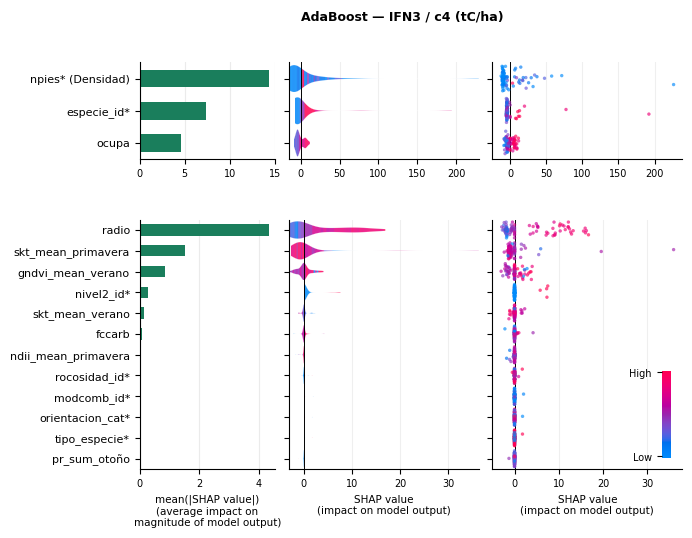

  -> ../../figures/shap_summary/IFN3/c4/summary_AdaBoost.png
  BaggedDT... [caché] 

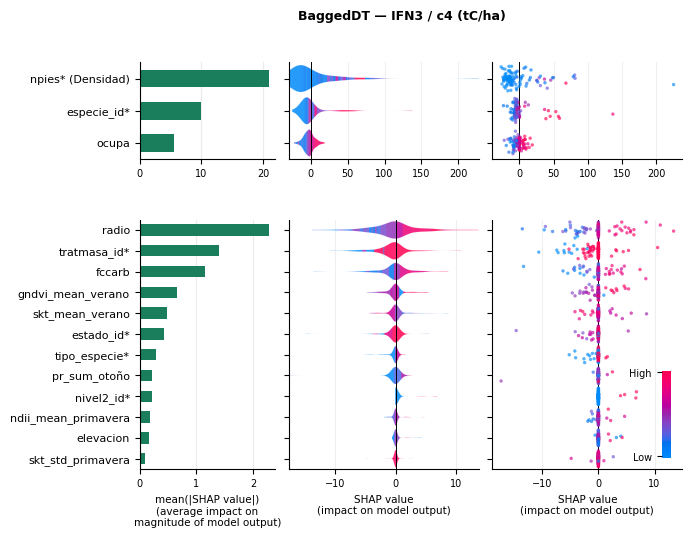

  -> ../../figures/shap_summary/IFN3/c4/summary_BaggedDT.png
  BayesianNN... [caché] 

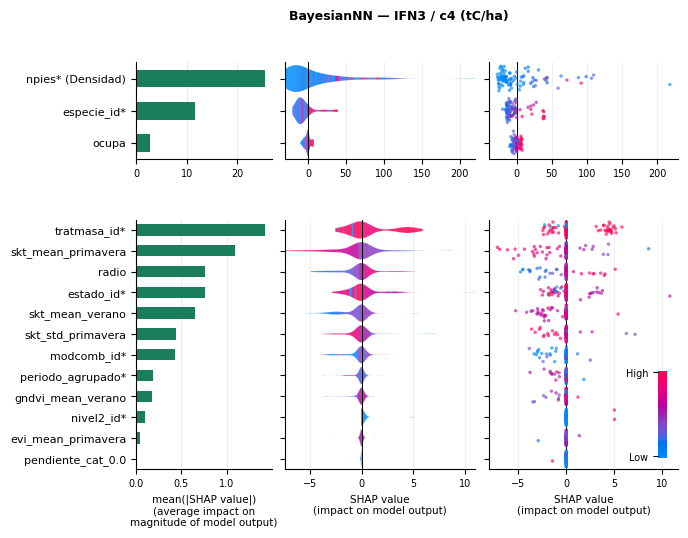

  -> ../../figures/shap_summary/IFN3/c4/summary_BayesianNN.png
  CatBoost... [caché] 

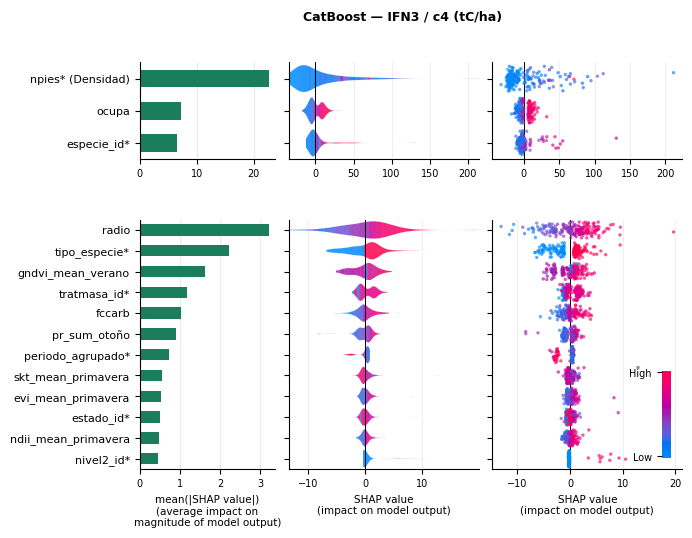

  -> ../../figures/shap_summary/IFN3/c4/summary_CatBoost.png
  GBDT... [caché] 

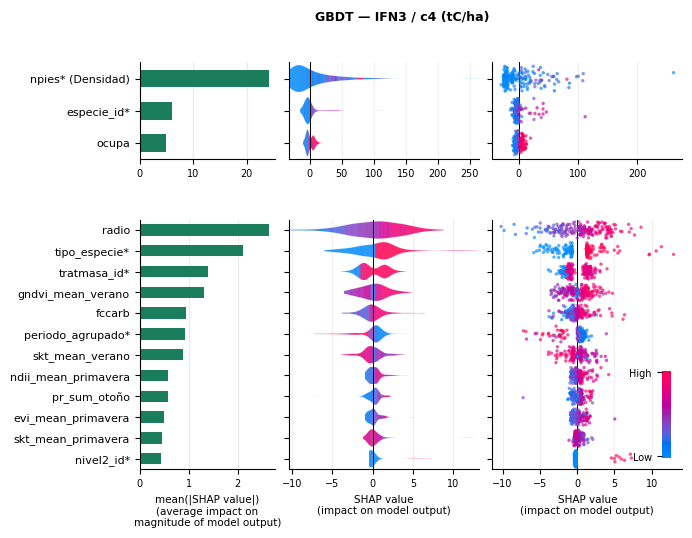

  -> ../../figures/shap_summary/IFN3/c4/summary_GBDT.png
  KNN... [caché] 

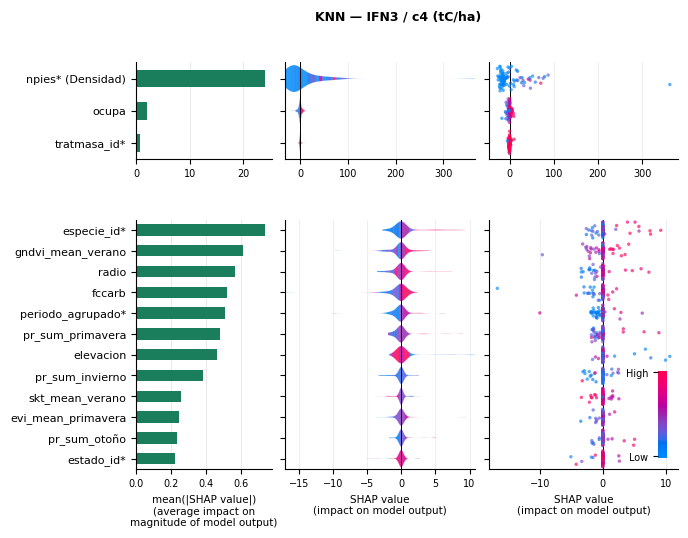

  -> ../../figures/shap_summary/IFN3/c4/summary_KNN.png
  LightGBM... [caché] 

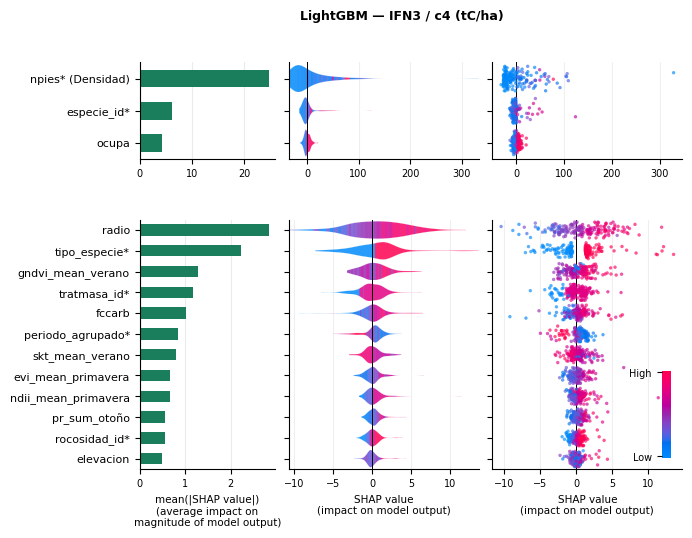

  -> ../../figures/shap_summary/IFN3/c4/summary_LightGBM.png
  MLP_PyTorch... [caché] 

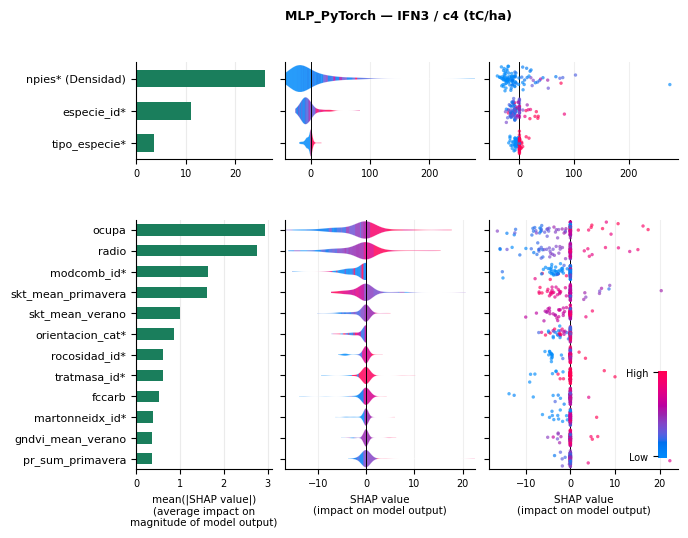

  -> ../../figures/shap_summary/IFN3/c4/summary_MLP_PyTorch.png
  Random_Forest... [caché] 

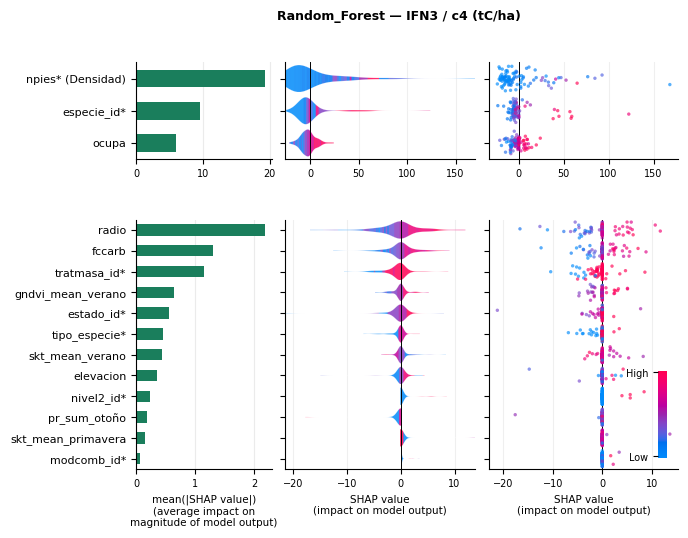

  -> ../../figures/shap_summary/IFN3/c4/summary_Random_Forest.png
  SVR... [caché] 

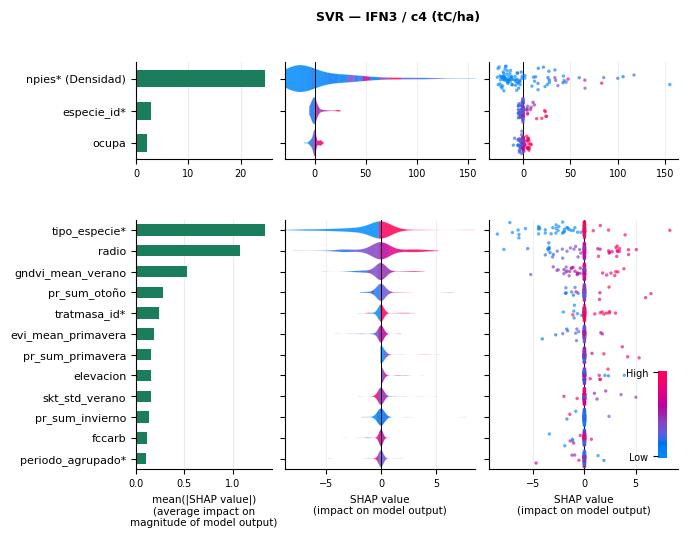

  -> ../../figures/shap_summary/IFN3/c4/summary_SVR.png
  XGBoost... [caché] 

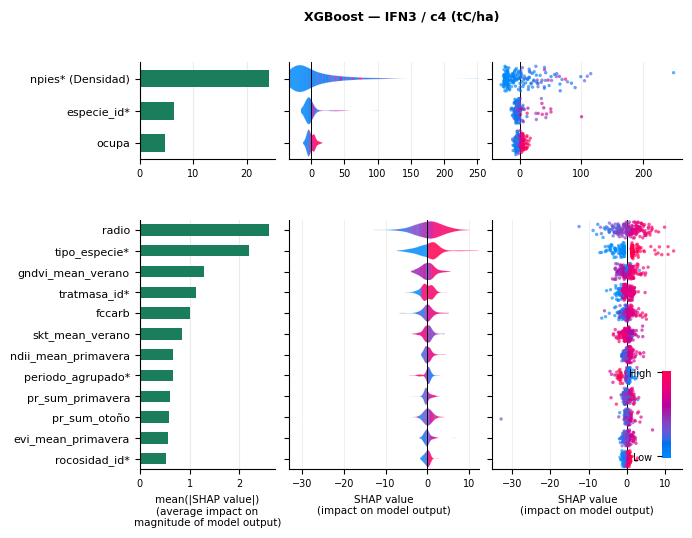

  -> ../../figures/shap_summary/IFN3/c4/summary_XGBoost.png

SUMMARY PLOTS — IFN3 / carbono_bruto4  (11 modelos)
  AdaBoost... [caché] 

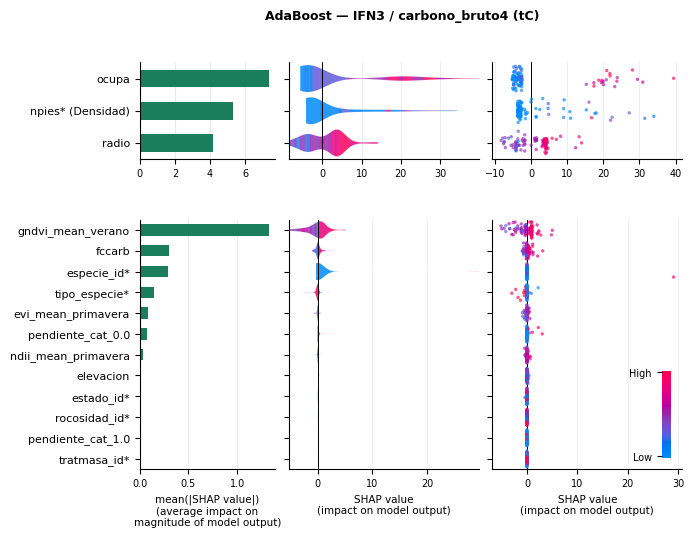

  -> ../../figures/shap_summary/IFN3/carbono_bruto4/summary_AdaBoost.png
  BaggedDT... [caché] 

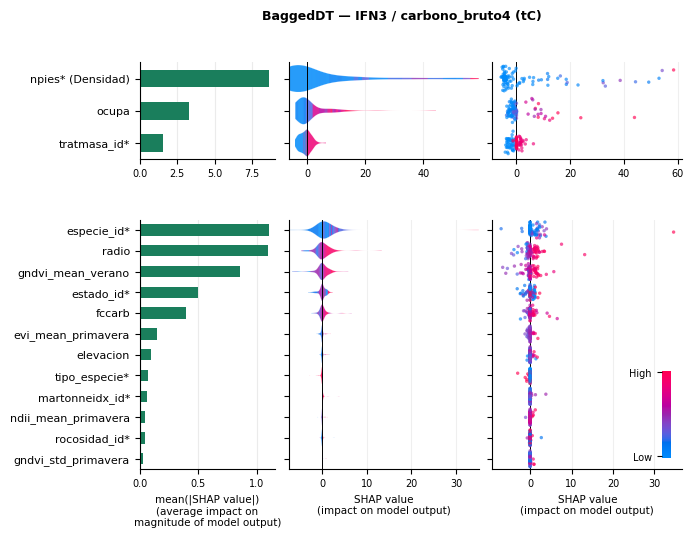

  -> ../../figures/shap_summary/IFN3/carbono_bruto4/summary_BaggedDT.png
  BayesianNN... [caché] 

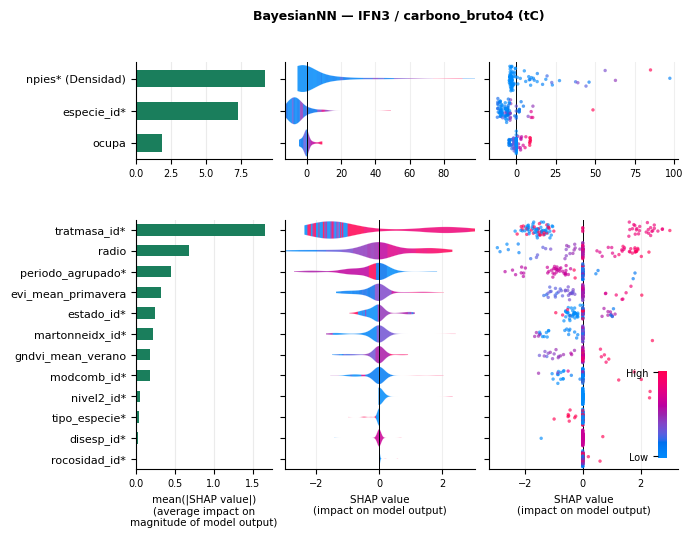

  -> ../../figures/shap_summary/IFN3/carbono_bruto4/summary_BayesianNN.png
  CatBoost... [caché] 

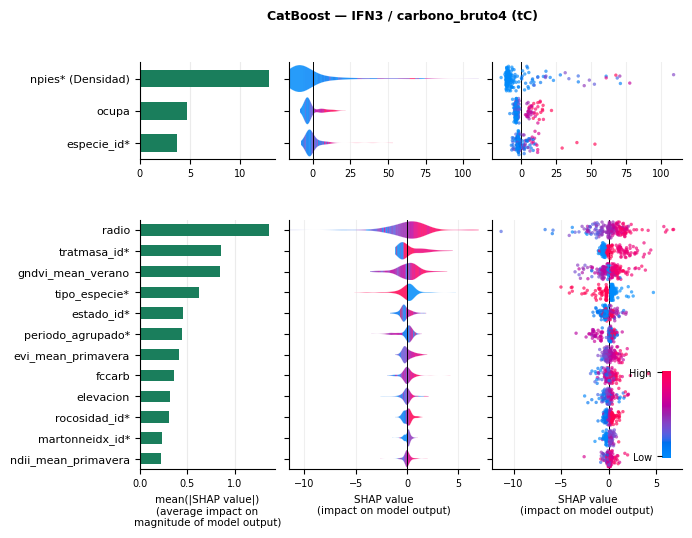

  -> ../../figures/shap_summary/IFN3/carbono_bruto4/summary_CatBoost.png
  GBDT... [caché] 

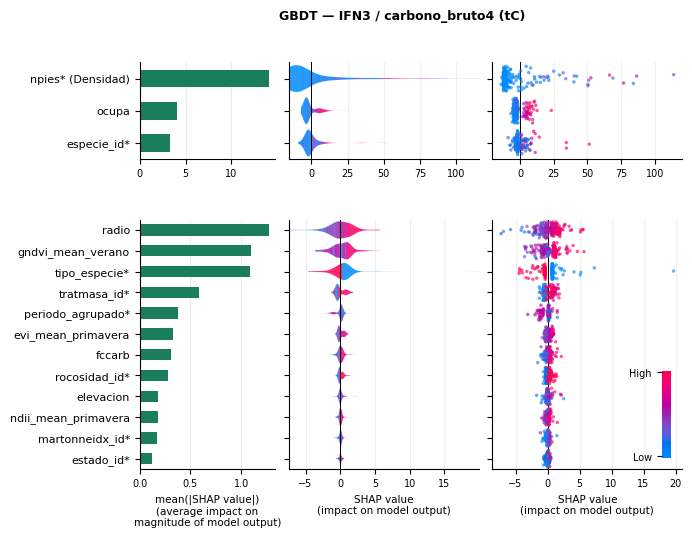

  -> ../../figures/shap_summary/IFN3/carbono_bruto4/summary_GBDT.png
  KNN... [caché] 

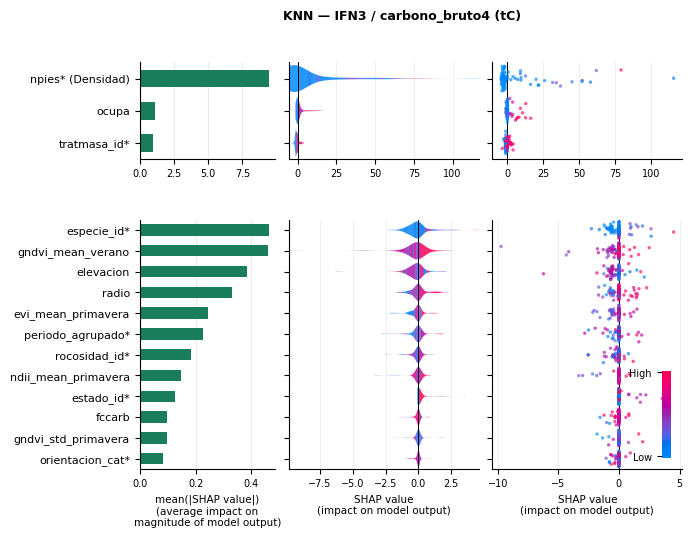

  -> ../../figures/shap_summary/IFN3/carbono_bruto4/summary_KNN.png
  LightGBM... [caché] 

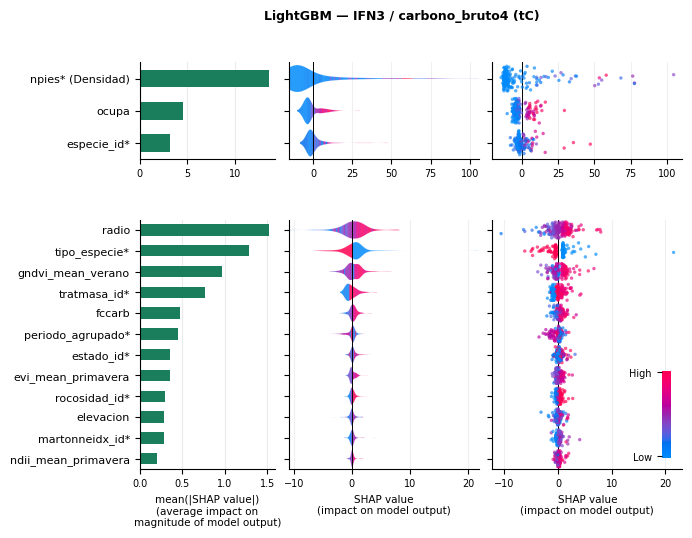

  -> ../../figures/shap_summary/IFN3/carbono_bruto4/summary_LightGBM.png
  MLP_PyTorch... [caché] 

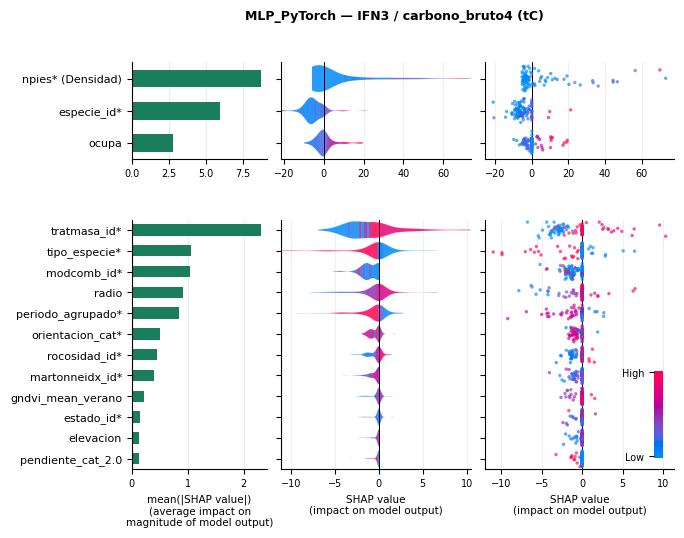

  -> ../../figures/shap_summary/IFN3/carbono_bruto4/summary_MLP_PyTorch.png
  Random_Forest... [caché] 

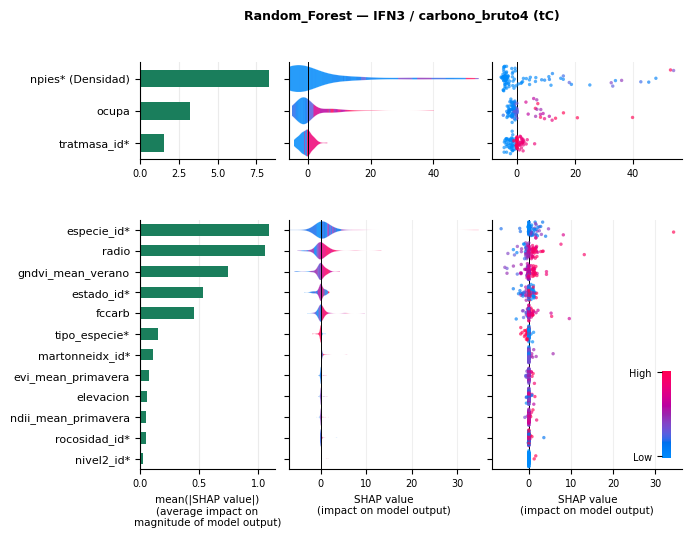

  -> ../../figures/shap_summary/IFN3/carbono_bruto4/summary_Random_Forest.png
  SVR... [caché] 

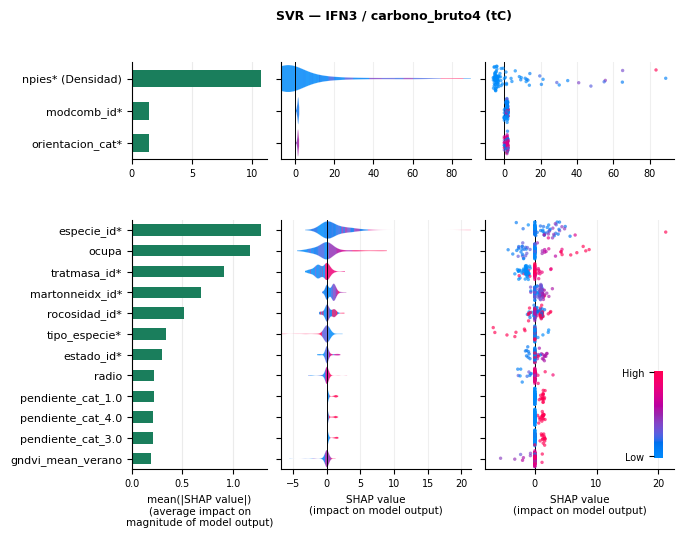

  -> ../../figures/shap_summary/IFN3/carbono_bruto4/summary_SVR.png
  XGBoost... [caché] 

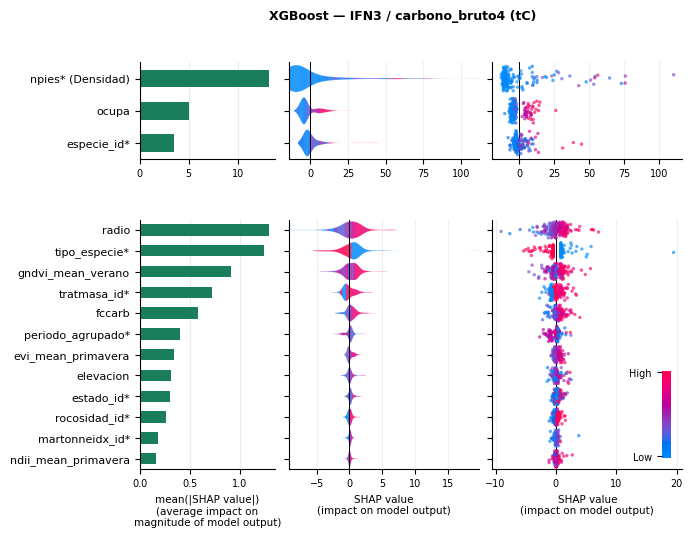

  -> ../../figures/shap_summary/IFN3/carbono_bruto4/summary_XGBoost.png

Summary plots completados.


In [40]:
FORCE_REGEN = True   # True → regenera aunque el PNG ya exista

for target_name, cfg in CONFIGS_SF.items():
    X_sample = samples[target_name]['X_sample']
    X_bg     = samples[target_name]['X_bg']
    tm       = samples[target_name]['tm']
    models_dir = cfg['models']
    unit       = cfg['unit']

    model_files = sorted(
        f for f in models_dir.iterdir()
        if f.suffix == '.joblib' and 'training_context' not in f.name
        and 'test_indices' not in f.name
    )

    print(f'\n{"="*65}')
    print(f'SUMMARY PLOTS — IFN3 / {target_name}  ({len(model_files)} modelos)')
    print(f'={"="*64}')

    for model_path in model_files:
        model_name = model_path.stem
        save_path  = OUT_SUMMARY / f'IFN3/{target_name}/summary_{model_name}.png'
        cache_path = CACHE_SHAP / 'IFN3' / 'base' / target_name / f'{model_name}.joblib'

        if save_path.exists() and not FORCE_REGEN:
            print(f'  [OK] {model_name}')
            ipy_display(IPImage(str(save_path)))
            continue

        print(f'  {model_name}...', end=' ')
        try:
            sv, fn, Xt, Xr, bv = load_or_compute_shap(
                model_path, X_sample, X_bg, model_name, cache_path=cache_path
            )
            shap_g, data_g, names_g, colors_g = group_shap(sv, fn, Xr, Xt, tm)
            plot_3panel_summary(
                shap_g, data_g, names_g,
                title     = f'{model_name} — IFN3 / {target_name} ({unit})',
                save_path = save_path,
                top_n     = 15,
                unit      = unit,
                var_colors= colors_g,
            )
        except Exception as e:
            print(f'ERROR: {e}')
        finally:
            gc.collect()

print('\nSummary plots completados.')

---
## 9. Importancia SHAP por Especie

Calcula SHAP con TreeExplainer sobre todo el dataset IFN3 (~260k muestras) y analiza qué especies aumentan o disminuyen la predicción de carbono.

- **Grupo A** — Especies que *aumentan* el carbono predicho (SHAP medio > 0)
- **Grupo B** — Especies que *disminuyen* el carbono predicho (SHAP medio < 0)

In [41]:
# ── Rutas sección 9 ───────────────────────────────────────────────────────
MODEL_DIR_ESP = MODELS_IFN3_C4          # itera sobre todos los modelos base
OUT_DIR_ESP   = BASE / 'figures/shap'
OUT_DIR_ESP.mkdir(parents=True, exist_ok=True)
print('Config sección 9 OK')


Config sección 9 OK


In [42]:
import time

# Carga del dataset completo (una sola vez para todos los modelos)
df_raw_esp = pd.read_csv(DATA_PATH)
print(f'Dataset: {df_raw_esp.shape[0]:,} filas x {df_raw_esp.shape[1]} columnas')

# Preprocesador de referencia (idéntico para todos los modelos base IFN3 c4)
_ref_pipe = joblib.load(MODEL_DIR_ESP / 'CatBoost.joblib')
pre_esp   = _ref_pipe.named_steps['preprocessor']

def _get_feat_names(preprocessor):
    import math

    def _is_nan(v):
        try: return math.isnan(v)
        except: return False

    try:
        return list(preprocessor.get_feature_names_out())
    except Exception:
        names = []
        for name, step, cols in preprocessor.transformers_:
            if name == 'remainder' and step == 'drop': continue
            surviving = list(cols)
            if isinstance(step, Pipeline):
                for _, est in step.steps:
                    if hasattr(est, 'statistics_'):
                        surviving = [c for c, v in zip(surviving, est.statistics_)
                                     if not _is_nan(v)]
                        break
            s = step.steps[-1][1] if isinstance(step, Pipeline) else step
            if isinstance(s, OneHotEncoder) and hasattr(s, 'categories_'):
                for col, cats in zip(surviving, s.categories_):
                    names.extend([f'{col}_{c}' for c in cats])
            else:
                names.extend(surviving)
        return names

feat_names_esp = _get_feat_names(pre_esp)
print('Transformando dataset...')
X_trans_esp = pre_esp.transform(df_raw_esp[[c for c in df_raw_esp.columns if c != 'c4']])
if X_trans_esp.shape[1] != len(feat_names_esp):
    feat_names_esp = [f'f_{i:03d}' for i in range(X_trans_esp.shape[1])]
X_df_esp = pd.DataFrame(X_trans_esp, columns=feat_names_esp)
del _ref_pipe; gc.collect()

# Columnas OHE de especie_id y valores raw
esp_cols_esp = [(i, f) for i, f in enumerate(feat_names_esp)
                if f.startswith('especie_id_') or f == 'especie_id']
esp_raw_esp  = df_raw_esp['especie_id'].values
print(f'Columnas especie_id OHE: {len(esp_cols_esp)}')

# Lookup BD (una sola vez)
id_list_bd = ','.join(sorted({
    str(int(float(f.replace('especie_id_','').replace('.0',''))))
    for _, f in esp_cols_esp if '_' in f
}))
conn = mysql.connector.connect(**DB_CFG)
cur  = conn.cursor()
cur.execute(f'SELECT especie_id, nombre, tipo_especie FROM especies WHERE especie_id IN ({id_list_bd})')
_db = cur.fetchall()
conn.close()
nombres_map = {r[0]: r[1] for r in _db}
tipos_map   = {r[0]: ('Frondosa' if r[2] == 1 else 'Conífera') for r in _db}
print(f'Especies en BD: {len(nombres_map)}')
print('Datos listos.')


Dataset: 259,853 filas x 446 columnas
Transformando dataset...
Columnas especie_id OHE: 122
Especies en BD: 122
Datos listos.


In [ ]:
TOP_PLOT    = 15
SAMPLE_PERM = 2000   # filas para PermutationExplainer (no-árbol)
N_PER_ESP   = 30     # max muestras por especie en el subsample

model_files = sorted(
    f for f in MODEL_DIR_ESP.iterdir()
    if f.suffix == '.joblib'
    and 'training_context' not in f.name
    and 'test_indices' not in f.name
)
print(f'Modelos a analizar: {len(model_files)}')

df_esp = df_pos = df_neg = None


def _stratified_idx(esp_vals, n_per, total_max, seed=42):
    """Índices con hasta n_per filas por especie_id, total ≤ total_max."""
    rng = np.random.default_rng(seed)
    idx = []
    for e in np.unique(esp_vals):
        pos = np.where(esp_vals == e)[0]
        take = min(n_per, len(pos))
        idx.extend(rng.choice(pos, take, replace=False).tolist())
    idx = np.array(idx)
    if len(idx) > total_max:
        idx = np.random.default_rng(seed).choice(idx, total_max, replace=False)
    return idx


for model_path in model_files:
    model_name = model_path.stem
    print(f'\n{"="*58}')
    print(f'Modelo: {model_name}')
    print(f'{"="*58}')

    try:
        pipe_m  = joblib.load(model_path)
        model_m = pipe_m.named_steps['regressor']

        sv_m         = None
        esp_raw_used = esp_raw_esp          # por defecto: todo el dataset

        # ── Intento 1: TreeExplainer (rápido, modelos árbol) ──────────────
        try:
            t0   = time.time()
            expl = shap.TreeExplainer(model_m)
            sv_m = expl.shap_values(X_df_esp)
            if isinstance(sv_m, list): sv_m = sv_m[0]
            print(f'  SHAP (tree) en {time.time()-t0:.1f}s  |  shape: {sv_m.shape}')

        except Exception as e_tree:
            # ── Intento 2: PermutationExplainer con muestra estratificada ──
            print(f'  TreeExplainer no soportado — PermutationExplainer '
                  f'(~{SAMPLE_PERM} filas, ≤{N_PER_ESP}/especie)')
            try:
                idx_perm = _stratified_idx(
                    esp_raw_esp, n_per=N_PER_ESP, total_max=SAMPLE_PERM)
                X_perm       = X_df_esp.iloc[idx_perm].reset_index(drop=True)
                esp_raw_used = esp_raw_esp[idx_perm]

                # Background: 100 filas aleatorias
                rng_bg  = np.random.default_rng(99)
                bg_idx  = rng_bg.choice(len(X_df_esp),
                                        min(100, len(X_df_esp)), replace=False)
                masker  = shap.maskers.Independent(
                    X_df_esp.iloc[bg_idx], max_samples=100)

                def _predict_fn(X_in):
                    arr = model_m.predict(
                        pd.DataFrame(X_in, columns=feat_names_esp))
                    r = np.array(arr).flatten().astype(float)
                    return r

                t0     = time.time()
                expl_p = shap.Explainer(
                    _predict_fn, masker, algorithm='permutation')
                sv_m   = expl_p(X_perm).values
                if isinstance(sv_m, list): sv_m = sv_m[0]
                print(f'  SHAP (perm) en {time.time()-t0:.1f}s  |  '
                      f'shape: {sv_m.shape}  (muestra)')

            except Exception as e_perm:
                print(f'  PermutationExplainer también falló '
                      f'({type(e_perm).__name__}: {e_perm}) — saltando')
                del pipe_m; gc.collect()
                continue

        del pipe_m; gc.collect()

        # ── Importancia y signo por especie ───────────────────────────────
        rows_m = []
        for col_idx, col_name in esp_cols_esp:
            raw_id = col_name.replace('especie_id_', '').replace('.0', '')
            try:    esp_id = int(float(raw_id))
            except: esp_id = raw_id
            mask_m = esp_raw_used == esp_id
            n_act  = int(mask_m.sum())
            sv_col = sv_m[:, col_idx]
            rows_m.append({
                'especie_id'  : esp_id,
                'shap_abs'    : float(np.mean(np.abs(sv_col))),
                'shap_signed' : float(sv_col[mask_m].mean()) if n_act > 0 else 0.0,
                'n_activo'    : n_act,
            })

        df_m = (pd.DataFrame(rows_m)
                  .set_index('especie_id')
                  .sort_values('shap_abs', ascending=False))
        df_m['nombre'] = df_m.index.map(nombres_map)
        df_m['tipo']   = df_m.index.map(tipos_map).fillna('?')
        df_pos_m = df_m[df_m['shap_signed'] > 0].sort_values('shap_signed', ascending=False)
        df_neg_m = df_m[df_m['shap_signed'] < 0].sort_values('shap_signed', ascending=True)
        print(f'  Positivas: {len(df_pos_m)}  |  Negativas: {len(df_neg_m)}')

        if model_name == 'CatBoost':
            df_esp, df_pos, df_neg = df_m.copy(), df_pos_m.copy(), df_neg_m.copy()

        # ── Gráfico de barras por grupos ──────────────────────────────────
        fig, axes = plt.subplots(1, 2, figsize=(9.5, TOP_PLOT * 0.28 + 1.2))
        fig.suptitle(
            f'Efecto de cada especie sobre la predicción de carbono '
            f'({model_name} / IFN3 / c4)\n'
            'SHAP medio con signo — muestras donde la especie está activa',
            fontsize=8.5, fontweight='bold')
        for ax, df_g, color, titulo in [
            (axes[0], df_pos_m.head(TOP_PLOT), '#c62828',
             f'Grupo A — Aumentan carbono (n={len(df_pos_m)} especies)'),
            (axes[1], df_neg_m.head(TOP_PLOT), '#1565c0',
             f'Grupo B — Disminuyen carbono (n={len(df_neg_m)} especies)'),
        ]:
            labels = (df_g['nombre'].fillna('?') + '  (id=' +
                      df_g.index.astype(str) + ')').values[::-1]
            vals   = df_g['shap_signed'].values[::-1]
            y      = range(len(labels))
            ax.barh(y, vals, color=color, height=0.65, alpha=0.85, zorder=2)
            ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=7.5)
            ax.axvline(0, color='black', linewidth=0.8)
            ax.set_xlabel('SHAP medio con signo (tC/ha)', fontsize=8)
            ax.set_title(titulo, fontsize=8, fontweight='bold')
            ax.spines[['top','right']].set_visible(False)
            ax.grid(axis='x', alpha=0.25, zorder=0)
            xl = ax.get_xlim(); xr = xl[1] - xl[0]
            for i, v in enumerate(vals):
                if v >= 0:
                    tx, ha_t = v + 0.02 * xr, 'left'
                else:
                    tx_out = v - 0.02 * xr
                    tx, ha_t = ((v + 0.02 * xr, 'left')
                                if tx_out < xl[0] + 0.08 * xr
                                else (tx_out, 'right'))
                ax.text(tx, i, f'{v:+.2f}', va='center', ha=ha_t, fontsize=6.5)
        plt.tight_layout(rect=[0, 0, 1, 0.94])
        save_p = OUT_DIR_ESP / f'especie_signo_grupos_ifn3_c4_{model_name}.png'
        plt.savefig(save_p, dpi=300, bbox_inches='tight')
        plt.show(); plt.close()
        print(f'  -> {save_p.name}')
        del sv_m; gc.collect()

    except Exception as e:
        print(f'  ERROR inesperado: {e}')

print('\nAnálisis de especies completado.')
if df_pos is None:
    print('AVISO: no se encontraron resultados de CatBoost; tabla/scatter no disponibles.')


Modelos a analizar: 11

Modelo: AdaBoost
  TreeExplainer no soportado — PermutationExplainer (~2000 filas, ≤30/especie)


PermutationExplainer explainer:   3%|▎         | 51/2000 [00:38<18:06,  1.79it/s]

## 5. Grupo A — Especies que AUMENTAN el carbono predicho

Una especie con SHAP positivo indica que su presencia **empuja la predicción del modelo por encima del baseline** (media del dataset). En el contexto de este modelo — que predice el carbono aéreo en un periodo futuro — esto significa que los rodales de esta especie tienden a tener **más carbono en el futuro** de lo que indica la media del IFN.

La explicación principal para la mayoría de las especies del Grupo A no es su altísima productividad en términos absolutos, sino su patrón de **gestión extensiva o semi-natural**: estas especies no se cortan o se cortan con poca frecuencia, por lo que en cualquier medición futura el stock de carbono se mantiene o acumula.

---

### Pinus halepensis — SHAP ≈ +0.44 tC/ha (el más alto)
**Interpretación ecológica: coherente**

El pino carrasco es la especie más extendida del IFN español (> 3 millones de ha), principalmente en el arco mediterráneo. Aunque su productividad absoluta es moderada (MAI de 1–5 m³/ha/año; stocks de 15–40 tC/ha), la mayor parte de su área se gestiona de forma extensiva o natural, sin aprovechamientos forestales regulares. En consecuencia, entre dos mediciones del IFN (~10 años), el carbono de los rodales de *P. halepensis* **aumenta sistemáticamente** y supera la media del dataset, en la que también entran especies que se cortan (eucaliptos, castaños).

**Ref**: Ruiz-Peinado et al. (2011) *Forest Systems* 20(1); Montero et al. (2005) INIA/MMA.

---

### Pinus pinaster — SHAP ≈ +0.30 tC/ha
**Interpretación ecológica: coherente**

El pino resinero tiene una distribución bimodal: plantaciones atlánticas de alta productividad (Galicia, Asturias) y masas naturales mediterráneas de productividad media-baja. El SHAP positivo refleja que, en la mayoría de sus plots, los stocks de carbono en el futuro predicho son superiores a la media, tanto por su crecimiento moderado-alto como por la menor intensidad de cortas en comparación con las plantaciones de eucalipto.

**Ref**: Balboa-Murias et al. (2006) *For. Ecol. Manag.* 211; Merino et al. (2005) *Biomass Bioenergy* 28.

---

### Quercus pyrenaica — SHAP ≈ +0.14 tC/ha
**Interpretación ecológica: muy coherente**

El roble melojo domina los pisos montanos del Sistema Central, norte de Extremadura y montaña ibérica. Forma bosques de crecimiento lento pero muy constante (MAI de 1.5–4 m³/ha/año), con escasa presión de tala. Los stocks adultos de 30–80 tC/ha son consistentemente superiores a la media del IFN. La baja intensidad de aprovechamiento implica que entre mediciones el carbono siempre crece, generando un SHAP positivo robusto.

**Ref**: Ruiz-Peinado et al. (2012) *Forest Systems* 21(3); Montero et al. (2005).

---

### Quercus robur — SHAP ≈ +0.13 tC/ha
**Interpretación ecológica: muy coherente**

El roble pedunculado es la frondosa dominante del NW español (Galicia, Asturias, Cantabria, País Vasco). Junto con *Q. pyrenaica*, forma los bosques con stocks de carbono más estables del IFN: 40–100 tC/ha en masa madura, con aprovechamientos muy esporádicos. El SHAP positivo refleja la acumulación continua de carbono entre periodos del IFN.

---

### Quercus faginea — SHAP ≈ +0.056 tC/ha
**Interpretación ecológica: coherente**

El quejigo coloniza los pisos meso- y supramediterráneo en toda la Península. Especie de crecimiento lento, escasamente explotada, con stocks de 20–50 tC/ha. Su SHAP positivo sigue el mismo patrón que el resto de las quercíneas: acumulación continua sin perturbaciones de cosecha.

---

### Otras especies del Grupo A
*Corylus avellana*, *Quercus suber*, *Erica arborea*, *Pinus sylvestris*, *Crataegus monogyna*, *Ilex aquifolium* — todas comparten el rasgo de baja intensidad de gestión o larga rotación, que favorece la acumulación de carbono entre mediciones del IFN.

*Juniperus thurifera* con SHAP ≈ +0.001 es marginal; el valor es estadísticamente débil.

---

**¿Tiene sentido el Grupo A?** Sí, con una interpretación dinámica clave: el modelo no solo aprende el stock estático de cada especie, sino la **trayectoria temporal esperada** del carbono del rodal. Las especies de gestión extensiva o natural (pinos mediterráneos, quercíneas) acumulan carbono de forma predecible entre mediciones → SHAP positivo. Las de gestión intensiva (eucalipto, castaño) se cortan y regeneran → stock en el futuro por debajo del baseline → SHAP negativo.

## 6. Grupo B — Especies que DISMINUYEN el carbono predicho

Una especie con SHAP negativo hace que el modelo prediga **menos carbono del esperado por el baseline**. El resultado más llamativo es que las especies de mayor productividad absoluta en España (eucaliptos, castaños, hayas) aparecen en este grupo. La razón es la clave interpretativa del análisis: el modelo predice carbono en un **futuro**, no en el instante de la medida.

**Hipótesis central**: las especies de gestión intensiva o alta presión de cosecha (eucalipto, castaño, chopos, fresnos madereros) se cortan con regularidad; en la siguiente medición del IFN (~10 años) la masa ha sido regenerada o replantada y el stock de carbono es muy inferior al de la medición anterior. El modelo aprende este patrón y asigna SHAP negativo a estas especies.

---

### Eucalyptus globulus — SHAP ≈ −1.49 tC/ha (el más bajo)
**Interpretación ecológica: coherente — la más llamativa del análisis**

El mayor SHAP negativo del dataset. *E. globulus* tiene rotaciones de **10–12 años** en Galicia y Asturias, con aprovechamiento casi universal al final de cada turno (masa cortada a matarrasa). Aunque los stocks en el pico de producción son de 50–120 tC/ha (los más altos de España), **en cualquier punto aleatorio del ciclo de 10 años**, la masa puede estar recién plantada (< 5 tC/ha) o a mitad de turno (20–60 tC/ha). La media esperada en el **futuro** predicho es sistemáticamente inferior al baseline del IFN.

El modelo no aprende "eucalipto → mucho carbono" sino "eucalipto → carbono incierto, con alta probabilidad de estar por debajo de la media por aprovechamiento".

**Ref**: Balboa-Murias et al. (2006) *For. Ecol. Manag.* 211 — confirma los turnos cortos y la variabilidad de stocks.

---

### Castanea sativa — SHAP ≈ −1.04 tC/ha
**Interpretación ecológica: coherente**

El castaño en monte bajo (turno de vara: 5–15 años) es uno de los sistemas forestales más productivos e intensivamente gestionados de la cornisa Cantábrica y norte de Extremadura. Rotaciones cortas para la producción de madera de sierra, frutos o estacas garantizan que en la siguiente medición del IFN el rodal esté en la fase de regeneración post-corta, con stock mínimo.

La madera es densa (0.55–0.65 g/cm³) y los stocks en máximo son de 80–160 tC/ha, pero la frecuencia de la corta hace que el carbon futuro sea bajo. SHAP negativo consistente con el patrón de gestión.

**Ref**: Álvarez-Álvarez et al. (2011) *Biomass Bioenergy*; Montero et al. (2005) INIA/MMA.

---

### Pinus nigra — SHAP ≈ −0.20 tC/ha
**Interpretación ecológica: moderadamente coherente**

El pino laricio tiene una distribución concentrada en las sierras béticas, ibéricas y Pirineos, con stocks de 20–60 tC/ha. Muchas de las masas del IFN son repoblaciones de los años 1950–1970 que en el periodo de IFN2 a IFN3 llegaron a su turno de corta o sufrieron perturbaciones (nevadas, viento, escolítidos). El SHAP negativo puede reflejar esta combinación de aprovechamientos y eventos de mortalidad que reducen el carbono en el futuro predicho.

---

### Fagus sylvatica — SHAP ≈ −0.20 tC/ha
**Interpretación ecológica: requiere matiz**

El haya forma los bosques con los stocks aéreos más altos de España (80–200 tC/ha en masa madura). El SHAP negativo puede explicarse por dos factores:

1. **Gestión en monte bajo o monte medio**: muchos hayedos de los Pirineos y Cantábrico tienen historial de aprovechamiento en turnos de 40–80 años. Si en el periodo IFN2→IFN3 hubo cortas, el stock cae significativamente.
2. **Alta variabilidad estructural**: los hayedos abarcan desde masas jóvenes post-corta (< 30 tC/ha) hasta bosques maduros (> 150 tC/ha). La media en el futuro predicho puede quedar por debajo del baseline del dataset si el IFN muestreó mucha superficie joven.

**Ref**: Pan et al. (2011) *Science* 333; Peltoniemi et al. (2006) *Silva Fennica*.

---

### Fraxinus angustifolia — SHAP ≈ −0.13 tC/ha
**Interpretación ecológica: coherente**

El fresno ibérico es una especie de ribera con madera muy valiosa (densidad 0.65–0.75 g/cm³). Las choperas y fresnedas riparias son sistemas de muy alta productividad pero con **frecuentes cortas**, tanto forestales como por mejora de cauces. El modelo predice correctamente que los rodales de fresno en el futuro tendrán stock más bajo que el baseline.

---

### Eucalyptus camaldulensis — SHAP ≈ −0.11 tC/ha
**Interpretación ecológica: idéntica a E. globulus**

El eucalipto rojo del Mediterráneo (Andalucía, Extremadura) tiene los mismos patrones de gestión intensiva y turnos cortos que *E. globulus*, aunque con stocks algo menores (25–70 tC/ha). El SHAP negativo es coherente.

---

### Populus x canadensis y Salix alba — SHAP negativo
**Interpretación ecológica: coherente**

Los chopos híbridos y sauces riparios son los sistemas de **máxima productividad** a corto plazo (MAI de 10–25 m³/ha/año), pero también los de **turnos más cortos** (8–15 años para chopo de madera). La alta frecuencia de aprovechamiento garantiza que el stock en el futuro sea bajo → SHAP negativo.

---

### Quercus ilex ssp. ballota (encina) — SHAP ≈ −0.04 tC/ha
**Interpretación ecológica: coherente por estructura de dehesa**

La encina tiene la madera más densa de España (0.85–1.00 g/cm³) y acumula mucho carbono total. Sin embargo, los plots de encina en el IFN representan mayoritariamente la **dehesa** (sistema agroforestal abierto): 10–30 árboles/ha con solo 5–20 tC/ha aéreos, muy por debajo del baseline. Los aprovechamientos de leñas y el adehesamiento (corta de pies para abrir el dosel) garantizan que el carbono futuro sea consistentemente inferior a la media.

---

**¿Tiene sentido el Grupo B?** Sí, con la interpretación de gestión dinámica. Las especies con mayor SHAP negativo son precisamente las de gestión **más intensiva y turnos más cortos** en el contexto español: eucaliptos (10–12 años), castaños en monte bajo (5–15 años), chopos (8–15 años) y fresnos. El haya y el pino laricio requieren matiz por heterogeneidad estructural y aprovechamientos episódicos. La señal del modelo captura fielmente los patrones reales de gestión forestal del IFN español.

In [ ]:
# Tabla completa con signo, tipo e importancia
TOP_TABLE = 30
df_show = pd.concat([
    df_pos.head(TOP_TABLE).assign(grupo='A: sube'),
    df_neg.head(TOP_TABLE).assign(grupo='B: baja'),
])
cols_show = ['nombre', 'tipo', 'grupo', 'shap_signed', 'shap_abs', 'n_activo']
df_show = df_show[cols_show].rename(columns={
    'shap_signed': 'SHAP signo',
    'shap_abs':    'mean|SHAP|',
    'n_activo':    'n muestras',
})
df_show = df_show.round(4)
print(f'Tabla resumen (top {TOP_TABLE} de cada grupo):')
df_show

Tabla resumen (top 30 de cada grupo):


,nombre,tipo,grupo,SHAP signo,mean|SHAP|,n muestras
especie_id,,,,,,
24,Pinus halepensis,Conífera,A: sube,0.4354,0.4072,15906
26,Pinus pinaster,Conífera,A: sube,0.3041,0.2073,19475
43,Quercus pyrenaica,Frondosa,A: sube,0.1415,0.1242,10346
41,Quercus robur,Frondosa,A: sube,0.1320,0.1348,10368
44,Quercus faginea,Frondosa,A: sube,0.0564,0.0596,10452
74,Corylus avellana,Frondosa,A: sube,0.0467,0.0394,2973
46,Quercus suber,Frondosa,A: sube,0.0423,0.0388,2858
83,Erica arborea,Frondosa,A: sube,0.0187,0.0157,784
21,Pinus sylvestris,Conífera,A: sube,0.0177,0.0359,14085


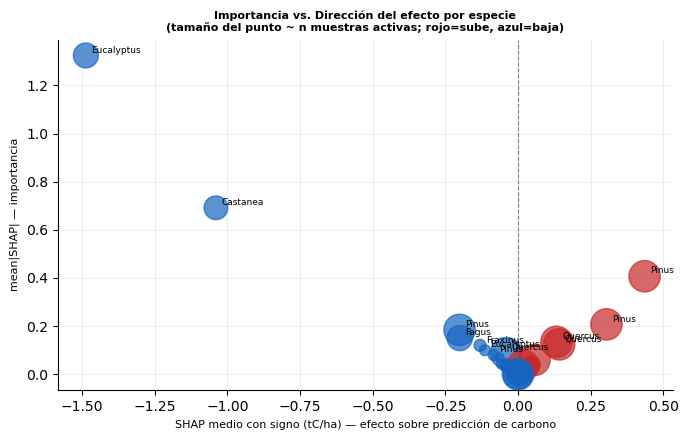

In [ ]:
# Scatter: importancia vs dirección del efecto — todas las especies con n_activo >= 20
df_valid = df_esp[df_esp['n_activo'] >= 20].copy()

fig, ax = plt.subplots(figsize=(7, 4.5))

colors = df_valid['shap_signed'].apply(lambda v: '#c62828' if v > 0 else '#1565c0')
ax.scatter(df_valid['shap_signed'], df_valid['shap_abs'],
           c=colors, s=df_valid['n_activo'].clip(upper=10000) / 20 + 10,
           alpha=0.7, zorder=3)

ax.axvline(0, color='gray', linewidth=0.8, linestyle='--')
ax.set_xlabel('SHAP medio con signo (tC/ha) — efecto sobre predicción de carbono', fontsize=8)
ax.set_ylabel('mean|SHAP| — importancia', fontsize=8)
ax.set_title('Importancia vs. Dirección del efecto por especie\n'
             '(tamaño del punto ~ n muestras activas; rojo=sube, azul=baja)',
             fontsize=8, fontweight='bold')
ax.spines[['top','right']].set_visible(False)
ax.grid(alpha=0.2, zorder=0)

# Etiquetar las más importantes
for _, row in df_valid.nlargest(12, 'shap_abs').iterrows():
    ax.annotate(row['nombre'].split()[0] if pd.notna(row['nombre']) else str(row.name),
                (row['shap_signed'], row['shap_abs']),
                xytext=(4, 2), textcoords='offset points', fontsize=6.5)

plt.tight_layout()
plt.savefig(OUT_DIR_ESP / 'especie_importancia_vs_signo_ifn3_c4.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Referencias bibliográficas

- **Balboa-Murias et al. (2006)** *For. Ecol. Manag.* 211 — biomasa *E. globulus*, *P. pinaster*, *C. sativa*, *Q. robur*
- **Merino et al. (2005)** *Biomass Bioenergy* 28 — stocks en plantaciones gallegas de eucalipto y pino
- **Ruiz-Peinado et al. (2011)** *Forest Systems* 20(1) — ecuaciones alométricas para coníferas españolas (referencia IFN)
- **Ruiz-Peinado et al. (2012)** *Forest Systems* 21(3) — ecuaciones alométricas para frondosas españolas
- **Montero et al. (2005)** INIA/MMA — *Producción de biomasa y fijación de CO₂ por los bosques españoles*; referencia nacional de stocks por especie
- **Pan et al. (2011)** *Science* 333 — stocks de carbono en bosques temperados europeos (*Fagus sylvatica*)
- **Peltoniemi et al. (2006)** *Silva Fennica* — carbono en hayedos europeos gestionados
- **IPCC (2006)** Vol. 4 Forest Land — densidades de madera y fracciones de carbono por género
- **Zianis et al. (2005)** *Silva Fennica* Monographs 4 — base de datos paneuropea de ecuaciones de biomasa